# SkillXray -  Skill extraction

## v22 clean-up (ordering and overwrite problems)

v22 keeps **one definition of each** function and value, in the place where it is first needed. No tuning logic was changed except where listed.

| problem | v22 |
|---|---|
| `standardise_spans` defined 3 times (reconstructed, two-stage with hard-coded 0.40/0.02, "unified" that reset `LINK_CFG` to 0.85 / hub 1.0) | one function in 9b-1 with `link_mode` = `sbert` (default) or `cross_encoder`; always reads `LINK_CFG` |
| two linker-tuning cells, the second overwriting the first and saving a JSON the loader could not read | one tuner (9a-2); cross-encoder only when `TUNE_CROSS_ENCODER = True`; the saved JSON now has the keys the loader reads, plus `link_mode` |
| hard-coded `LINK_THRESHOLD_OVERRIDE` / `LINK_MARGIN_OVERRIDE` beat any tuned file | overrides apply only when no tuned config exists |
| `link_overrides.csv` edited in 4 separate cells (two disagreed on `vs code`) | one cell (9b-0) |
| `match_v2` defined 5 times, the last (`match_v2_optimized`) dropping the raw-similarity floors, tool guard and certificate filter | one definition in 16c-2 with all three; `rule_components` moved there so a fresh session can use `run_v2` |
| `inherited_cover` defined twice with different signatures | one gated definition in 16a |
| 16d evaluated a matcher without the floors and tool guard that `run_v2` deploys; phrases looked up for the resume's first role only | 16d applies the same floors and tool guard, and looks phrases up per requirement role |
| `build_role_profiles` defined twice and profiles rebuilt *after* the matcher was tuned | one builder in section 10 (`PROFILE_WEIGHTING`), blocklist from 14h saved to `role_profiles.parquet` |
| `M` (match + adjacent mask) overwritten by a dataframe merge | the duplicate gold-finalising and re-evaluation cells are removed |
| re-evaluation cells took the **first** role of each resume, so adjacent and far pairs were dropped silently | new 16f scores per (resume, role) and reports how many rows were dropped |
| hard-coded "previous vs expanded" metrics | removed; 16f compares the deployed matcher with the exact-match baseline on the same rows |
| `profile_from_texts` called but never defined; "accountant" profile built from software postings | defined in the live-profile cell; deep dive uses `accountant` postings |
| junk check used `combined_spans` before it existed; duplicate `evaluate_extraction_on_gold` | reordered / merged (now 7a-lite) |

**Still true:** sections 7a/7c, 2b, 13c, 17, 18, 20 and 21 named in the run-order table are **not in this file**.

## v21 clean-up

Removed dead code: `keep_span` and the `pos_filter` plumbing (`pos_doc`, `get_nlp_pos`), `FILLER_*`, `inflect`/`IRREG`/`DOUBLE`, `SOFT_SKILL_VERB_LEMMAS`, `drop_soft`. Moved the `read_resume_file` fallback into setup (it was used before it was defined). `build_role_profiles_filtered` call fixed. Posting phrases in the upgraded `match_v2` are now read as lists. The config dump after `run_v2` no longer fails in a session that skipped 16d. **Reordered:** the cell that upgraded `inherited_cover` / `match_v2` now runs before the 16d evaluation (new cell after 16c), and the `ner_filter` switch plus the VS Code override run right after 8a, so tuning, evaluation and deployment use the same rules. Fixed the indented imports in the Supabase cell, which raised `IndentationError`. `cfg_signature` still hashes `pos_filter=False`, so existing Drive caches stay valid.

## v20 patch notes (review fixes)

Engine version is now `v9`, so cached spans are re-extracted once (the cache key also now covers the noise lists and regexes).

| # | change | where |
|---|---|---|
| 1 | Hard line wraps from PDF/DOCX are re-joined before splitting (`reflow_lines`) | section 6 |
| 2 | `/ , ; \|` end a span in `decode_words` and `snap_spans`: "HTML/CSS" is two skills, not one | sections 3, 6 |
| 3 | Salary filter needs a currency amount plus an unambiguous pay word; KES/Ksh added. No more dropping "range of suppliers, saved $40K" | section 6 |
| 4 | Longer span wins an overlap in `combine_models`; spans over `max_words` are removed before the overlap step | section 6 |
| 5 | "driver's license" and "maintenance" no longer blocked | section 6 |
| 6 | `.NET` keeps its dot; the plain word "net" no longer matches; capital check ignores a leading dot | section 6 |
| 7 | Capital check for `tool_guard` is now dot-safe. **`tool_guard` is still off in `DEFAULT_CFG`: check `extraction_config.json`** | section 6 |
| 8 | Cache signature includes the noise lists and regexes; `default=sorted` for sets | section 6 |
| 9 | `unit_spans` memoised per unique unit; `DocSpanStore.ensure` concatenates once (in a `finally`) | section 6 |
| 10 | Metrics: optimal one-to-one matching, unknown modes raise, `span_prf_ci` bootstrap CIs | section 4 |
| 11 | `!usr/bin/fusermount` typo | first cell |

Not changed: `SOFT_PHRASES` is still a fixed list.

## v22 clean-up (ordering and overwrite problems)

v21 ran top to bottom but later cells silently replaced the functions and values that earlier cells had just tuned. v22 keeps **one definition of each**, in the place where it is first needed. No tuning logic was changed except where listed.

| problem in v21 | v22 |
|---|---|
| `standardise_spans` defined 3 times (reconstructed, two-stage with hard-coded 0.40/0.02, "unified" that reset `LINK_CFG` to 0.85 / hub 1.0) | one function in 9b-1 with `link_mode` = `sbert` (default) or `cross_encoder`; always reads `LINK_CFG` |
| two linker-tuning cells, the second overwriting the first and saving a JSON the loader could not read | one tuner (9a-2); cross-encoder only when `TUNE_CROSS_ENCODER = True`; the saved JSON now has the keys the loader reads, plus `link_mode` |
| hard-coded `LINK_THRESHOLD_OVERRIDE` / `LINK_MARGIN_OVERRIDE` beat any tuned file | overrides apply only when no tuned config exists |
| `link_overrides.csv` edited in 4 separate cells (two disagreed on `vs code`) | one cell (9b-0) |
| `match_v2` defined 5 times, the last (`match_v2_optimized`) dropping the raw-similarity floors, tool guard and certificate filter | one definition in 16c-2 with all three; `rule_components` moved there so a fresh session can use `run_v2` |
| `inherited_cover` defined twice with different signatures | one gated definition in 16a |
| 16d evaluated a matcher without the floors and tool guard that `run_v2` deploys; phrases looked up for the resume's first role only | 16d applies the same floors and tool guard, and looks phrases up per requirement role |
| `build_role_profiles` defined twice and profiles rebuilt *after* the matcher was tuned | one builder in section 10 (`PROFILE_WEIGHTING`), blocklist from 14h saved to `role_profiles.parquet` |
| `M` (match + adjacent mask) overwritten by a dataframe merge | the duplicate gold-finalising and re-evaluation cells are removed |
| re-evaluation cells took the **first** role of each resume, so adjacent and far pairs were dropped silently | new 16f scores per (resume, role) and reports how many rows were dropped |
| hard-coded "previous vs expanded" metrics | removed; 16f compares the deployed matcher with the exact-match baseline on the same rows |
| `profile_from_texts` called but never defined; "accountant" profile built from software postings | defined in the live-profile cell; deep dive uses `accountant` postings |
| junk check used `combined_spans` before it existed; duplicate `evaluate_extraction_on_gold` | reordered / merged (now 7a-lite) |

**Still true:** sections 7a/7c, 2b, 13c, 17, 18, 20 and 21 named in the run-order table are **not in this file**.

## v21 clean-up

Removed dead code: `keep_span` and the `pos_filter` plumbing (`pos_doc`, `get_nlp_pos`), `FILLER_*`, `inflect`/`IRREG`/`DOUBLE`, `SOFT_SKILL_VERB_LEMMAS`, `drop_soft`. Moved the `read_resume_file` fallback into setup (it was used before it was defined). `build_role_profiles_filtered` call fixed. Posting phrases in the upgraded `match_v2` are now read as lists. The config dump after `run_v2` no longer fails in a session that skipped 16d. **Reordered:** the cell that upgraded `inherited_cover` / `match_v2` now runs before the 16d evaluation (new cell after 16c), and the `ner_filter` switch plus the VS Code override run right after 8a, so tuning, evaluation and deployment use the same rules. Fixed the indented imports in the Supabase cell, which raised `IndentationError`. `cfg_signature` still hashes `pos_filter=False`, so existing Drive caches stay valid.

## v20 patch notes (review fixes)

Engine version is now `v9`, so cached spans are re-extracted once (the cache key also now covers the noise lists and regexes).

| # | change | where |
|---|---|---|
| 1 | Hard line wraps from PDF/DOCX are re-joined before splitting (`reflow_lines`) | section 6 |
| 2 | `/ , ; \|` end a span in `decode_words` and `snap_spans`: "HTML/CSS" is two skills, not one | sections 3, 6 |
| 3 | Salary filter needs a currency amount plus an unambiguous pay word; KES/Ksh added. No more dropping "range of suppliers, saved $40K" | section 6 |
| 4 | Longer span wins an overlap in `combine_models`; spans over `max_words` are removed before the overlap step | section 6 |
| 5 | "driver's license" and "maintenance" no longer blocked | section 6 |
| 6 | `.NET` keeps its dot; the plain word "net" no longer matches; capital check ignores a leading dot | section 6 |
| 7 | Capital check for `tool_guard` is now dot-safe. **`tool_guard` is still off in `DEFAULT_CFG`: check `extraction_config.json`** | section 6 |
| 8 | Cache signature includes the noise lists and regexes; `default=sorted` for sets | section 6 |
| 9 | `unit_spans` memoised per unique unit; `DocSpanStore.ensure` concatenates once (in a `finally`) | section 6 |
| 10 | Metrics: optimal one-to-one matching, unknown modes raise, `span_prf_ci` bootstrap CIs | section 4 |
| 11 | `!usr/bin/fusermount` typo | first cell |

Not changed: `SOFT_PHRASES` is still a fixed list.

## Run order (read this first)

Run the cells **top to bottom**. The notebook is arranged so that nothing has to be run out of order.

| stage | sections | when |
|---|---|---|
| **A. Setup** | 1 to 5 | every new session |
| **B. Extraction engine and tuning** | 6, 6b, then 7 to 7c | engine (6, 6b) every session. Section 7 (extraction gold set, tuning, final test) only the first time, and **7c once**. Later sessions skip 7 and let the restore cell at the start of section 8 reload the saved configuration |
| **C. Documents, ESCO standardisation, role profiles** | 8, 9, 9b, 10 | every new session (cached on Drive, so re-runs are quick) |
| **D. New gap gold set** | 11, *annotate by hand*, 12, 12b | once. 11 builds the sheets, you label them, 12 checks them and writes `gap_gold.csv`, 12b extracts the gold resumes |
| **E. Matching and evaluation** | 13, 13b, 14, 14b to 14e | every session once `gap_gold.csv` exists |
| **F. Live profiles and market intelligence** | 17, 18 | once a month: 17a-17c with a `RAPIDAPI_KEY`, then `monthly_release()` (18c). Any session after that: 18a-18d to define the functions, then 18e for a report. Needs stages A to C and the matcher (14i) to have run |
| **G. Platform baseline vs SkillXray on the 24 Career Mentor skills** | 2b, 9b-1, 13c, 20, 21 | 2b every session (login, taxonomy, baseline); 13c right after section 13 (mapper to the 24 skills). Section 20 once the labelled CVs (`cvs_gold.jsonl`) are in `data/annotation/`, after stages A to C and section 13. 20c chooses settings on dev; 20d scores test once. Section 21 (fixes for the failure modes) also needs `cvs_gold_fresh.jsonl`: 21c tries the switches on dev, 21e scores the fresh CVs once |



**Later sessions, when `gap_gold.csv` already exists:** section 8 picks up the gold resumes by itself, so skip sections 11, 12 and 12b and run everything else top to bottom.

**Where the notebook stops on purpose**
- Section 11 ends with the annotation step: the sheets go to the annotators.
- Section 12 stops with an error message when the sheets have problems or when there are disagreements to adjudicate. That is intended. Fix the cause and run the cell again.




**Not in this file (v22):** sections 2b, 7a/7c (extraction tuning and `extraction_config.json`), 13c, 17, 18 and 20 to 21. Without 7c, section 8a keeps `DEFAULT_CFG` and says so. A fresh session that skips 16d must still run 16a to 16c-2 before `run_v2` (it reloads the saved rule and statistics).

## 1. Environment

In [1]:
!pip install -q spacy scikit-learn tqdm pyarrow pypdf python-docx sentence-transformers
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 22.4 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [2]:
import os, re, json, time, shutil, warnings

import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
os.environ["TOKENIZERS_PARALLELISM"] = "false"

N_THREADS = os.cpu_count() or 2
torch.set_num_threads(N_THREADS)

import random
SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)       # v17: every stochastic step (sampling, bootstraps) is seeded
print(f"torch {torch.__version__} | CPU threads: {N_THREADS} | CUDA: {torch.cuda.is_available()}")
import transformers, spacy as _spacy
print(f"transformers {transformers.__version__} | spaCy {_spacy.__version__} | pandas {pd.__version__} | numpy {np.__version__}   <- note these with your results")


torch 2.14.1+cu130 | CPU threads: 2 | CUDA: True
transformers 5.22.1 | spaCy 3.8.18 | pandas 2.2.3 | numpy 2.4.6   <- note these with your results


## 2. Drive, folders and settings

In [3]:
import os
import re
import time
import shutil
from google.colab import drive

# Only mount if not already mounted to prevent ValueError
if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

BASE_DIR      = '/content/drive/MyDrive/SkillXray'
RAW_DIR       = os.path.join(BASE_DIR, 'data/raw')
ESCO_DIR      = os.path.join(BASE_DIR, 'data/esco')
PROCESSED_DIR = os.path.join(BASE_DIR, 'data/processed')
EXTRACT_DIR   = os.path.join(PROCESSED_DIR, 'extracted')
ANNOT_DIR     = os.path.join(BASE_DIR, 'data/annotation')
RESULTS_DIR   = os.path.join(BASE_DIR, 'results')

# Fail loudly if Drive is not mounted (makedirs would otherwise create folders on Colab's temporary disk).
assert os.path.isdir('/content/drive/MyDrive'), "Google Drive is not mounted - re-run this cell."
for d in [RAW_DIR, ESCO_DIR, PROCESSED_DIR, EXTRACT_DIR, ANNOT_DIR, os.path.join(ANNOT_DIR, 'backup'),
          RESULTS_DIR, os.path.join(BASE_DIR, 'models/jobbert')]:
    os.makedirs(d, exist_ok=True)

# ------------------------------------------------------------------ settings
JOBBERT_REPOS = {'skill': 'jjzha/jobbert_skill_extraction', 'knowledge': 'jjzha/jobbert_knowledge_extraction'}
QUANTIZE       = True    # int8 dynamic quantisation, CPU only (ignored when a GPU is present: the models then run in fp16).
MAX_UNIT_WORDS = 70      # long run-on text (resumes) is cut into chunks of at most this many words
MAX_TOKENS     = 160     # model input limit per chunk
MAX_SKILL_WORDS = 8      # spans longer than this are duties, not skills

# Starting configuration, replaced by the best one found on the development part of your gold set (section 7a).
# tau[model] = a word counts as part of a skill when P(not 'outside') >= tau. Lower tau = more recall.
DEFAULT_CFG = {'models': ('knowledge', 'skill'), 'tau': {'knowledge': 0.3, 'skill': 0.7}, 'min_score': 0.0,
               'max_words': MAX_SKILL_WORDS, 'gazetteer': True,
               'rule_filter': False, 'ner_filter': False, 'tool_guard': False}     # v17 components, switched on only when section 7a shows they help
EXTRACTION_CFG = dict(DEFAULT_CFG)

# ------------------------------------------------------------------ annotation-file safety
def find_gold(stem):
    """Most recent '<stem>.csv' in ANNOT_DIR, tolerating Drive duplicate suffixes such as '<stem> (1).csv'.
    The stem must match the whole name, so 'gold' does not match 'gold_extra.csv'."""
    pat = re.compile(re.escape(stem) + r'\s*(\(\d+\))?\s*\.csv', re.I)
    hits = [os.path.join(ANNOT_DIR, f) for f in os.listdir(ANNOT_DIR) if pat.fullmatch(f)]
    return max(hits, key=os.path.getmtime) if hits else None

def safe_write_csv(df, path):
    """Create a NEW csv only; refuses if the file (or a near-duplicate name) already exists."""
    existing = find_gold(os.path.splitext(os.path.basename(path))[0])
    if existing:
        print(f"  not writing - already exists: {existing}")
        return False
    with open(path, 'x', newline='') as f:
        df.to_csv(f, index=False)
    return True

def backup_annotations():
    ts = time.strftime('%m%d_%H%M')
    for f in os.listdir(ANNOT_DIR):
        p = os.path.join(ANNOT_DIR, f)
        if f.lower().endswith('.csv') and os.path.isfile(p):
            shutil.copy(p, os.path.join(ANNOT_DIR, 'backup', f'{ts}_{f}'))
    print("annotation backups written to", os.path.join(ANNOT_DIR, 'backup'))

backup_annotations()
print("Annotation files present:", sorted(f for f in os.listdir(ANNOT_DIR) if f.endswith('.csv')))

annotation backups written to /content/drive/MyDrive/SkillXray/data/annotation/backup
Annotation files present: ['esco_linking_gold.csv', 'esco_linking_gold_template.csv', 'esco_linking_gold_v2_template.csv', 'esco_linking_gold_v2_template_un.csv', 'esco_platform_crosswalk.csv', 'extraction_gold.csv', 'extraction_gold_unannotated.csv', 'gap_gold.csv', 'gap_gold_backup.csv', 'gap_gold_old.csv', 'gap_gold_stale.csv', 'prospective_test_set_annotated.csv', 'prospective_test_set_template.csv', 'prospective_test_set_template_unalabelled.csv', 'soft_skills_context_gold.csv']


## 3. Models

`SpanExtractor` runs the JobBERT checkpoints directly. For every word it stores **P(skill) = 1 - P(outside)** and whether the word looks like the *beginning* of a span. Turning those probabilities into spans (`decode_words`) is a separate, instant step, which is why `tau` can be tuned without re-running the model.

Two checkpoints are used: `jobbert_knowledge_extraction` (tools, technologies, domain knowledge) and `jobbert_skill_extraction` (activities).

In [4]:
import spacy


SENT_NLP = spacy.blank("en")
SENT_NLP.add_pipe("sentencizer")

_NLP = None

def get_nlp(disable=None):
    """Singleton pattern to load en_core_web_sm once and reuse it,
    optionally disabling pipeline components to save processing time."""
    global _NLP
    if _NLP is None:
        # Load once with common heavy components disabled if possible,
        # or load standard and let spaCy handle it.
        _NLP = spacy.load("en_core_web_sm", disable=["parser", "attribute_ruler"])
    return _NLP

def get_nlp_ner():
    """spaCy named-entity recogniser."""
    return get_nlp()

print("spaCy ready")


spaCy ready


In [5]:
from collections import Counter
from transformers import AutoTokenizer, AutoModelForTokenClassification

# ------------------------------------------------------------------ device / precision
# v17: the model now runs on the GPU when there is one (fp16), and only falls back to int8 CPU quantisation when there is not.
# (v16 quantised for CPU and never moved the model to CUDA, even when Colab reported CUDA: True.)
DEVICE        = 'cuda' if torch.cuda.is_available() else 'cpu'
USE_FP16      = (DEVICE == 'cuda')
STRIDE_TOKENS = 32          # a text longer than MAX_TOKENS is scored in overlapping windows instead of being cut off

def resolve_bio_ids(id2label):
    """Return (B_id, I_id, O_id). Handles 'B'/'I'/'O' and 'B-XYZ'/'I-XYZ'; falls back to 0/1/2."""
    m = {}
    for k, v in id2label.items():
        tag = str(v).upper().split('-')[0]
        if tag in ('B', 'I', 'O'):
            m[tag] = int(k)
    if set(m) != {'B', 'I', 'O'}:
        m = {'B': 0, 'I': 1, 'O': 2}
    return m['B'], m['I'], m['O']

_SPAN_SEPS = set("/,;|")     # list separators: a skill span never runs across one ("HTML/CSS" -> "HTML", "CSS")

def decode_words(text, words, tau):
    """words: [(start, end, p_skill, is_begin), ...] in text order -> spans.
    A word belongs to a span when p_skill >= tau; a new span starts at a 'begin' word, after a gap,
    or after a list separator (/ , ; |). Separator-only words end the current span. (v20)"""
    spans, cur = [], None
    for s, e, ps, is_b in words:
        tok = text[s:e].strip()
        is_sep = (not tok) or all(ch in _SPAN_SEPS for ch in tok)
        if ps >= tau and not is_sep:
            sep_between = cur is not None and any(ch in _SPAN_SEPS for ch in text[cur['end']:s])
            if cur is None or is_b or sep_between:
                if cur is not None:
                    spans.append(cur)
                cur = {'start': s, 'end': e, 'ps': [ps]}
            else:
                cur['end'] = e; cur['ps'].append(ps)
        elif cur is not None:
            spans.append(cur); cur = None
    if cur is not None:
        spans.append(cur)
    return [{'start': c['start'], 'end': c['end'], 'score': float(np.mean(c['ps'])),
             'text': text[c['start']:c['end']].strip()} for c in spans]

_SNAP_BREAK = set("/,;|()")

def snap_spans(text, spans):
    """Expand each span to whole whitespace-delimited words ("s license" -> "driver's license", "co" -> "co-workers"),
    but never across a list separator, so "HTML/CSS/JavaScript" stays three spans instead of one. (v20)"""
    out = []
    for sp in spans:
        s, e = sp['start'], sp['end']
        while s > 0 and not text[s - 1].isspace() and text[s - 1] not in _SNAP_BREAK:
            s -= 1
        while e < len(text) and not text[e].isspace() and text[e] not in _SNAP_BREAK:
            e += 1
        out.append({**sp, 'start': s, 'end': e, 'text': text[s:e].strip()})
    return out

class SpanExtractor:
    def __init__(self, repo, quantize=True, max_tokens=160, stride=STRIDE_TOKENS, device=None, fp16=None):
        self.repo, self.max_tokens, self.stride = repo, max_tokens, stride
        self.device = device or DEVICE
        self.fp16 = (self.device == 'cuda') if fp16 is None else (fp16 and self.device == 'cuda')
        self.tok = AutoTokenizer.from_pretrained(repo)
        model = AutoModelForTokenClassification.from_pretrained(repo).eval()
        self.b_id, self.i_id, self.o_id = resolve_bio_ids(model.config.id2label)
        if self.device == 'cpu' and quantize:
            try:
                from torch.ao.quantization import quantize_dynamic
                model = quantize_dynamic(model, {torch.nn.Linear}, dtype=torch.qint8)
            except Exception as e:
                print("  quantisation skipped:", e)
        else:
            model = model.to(self.device)
            if self.fp16:
                model = model.half()
        self.model = model
        self.stats = {'texts': 0, 'windowed_texts': 0, 'windows': 0}

    # -------------------------------------------------------------- one forward pass over a list of windows
    def _forward(self, enc, lo, hi):
        feed = {k: torch.from_numpy(np.ascontiguousarray(v[lo:hi])).to(self.device) for k, v in enc.items()
                if k in ('input_ids', 'attention_mask', 'token_type_ids')}
        with torch.inference_mode():
            logits = self.model(**feed).logits.float()            # softmax in fp32 even when the model runs in fp16
            return torch.softmax(logits, dim=-1).cpu().numpy()

    def predict_word_scores(self, texts, batch_size=32):
        """texts -> aligned list of word lists [(start, end, pB, pI, pO)].
        The label of a word is the label of its first sub-token. A text longer than max_tokens is split into windows that
        overlap by `stride` tokens; every word takes its probabilities from the window in which it sits furthest from an edge,
        so no word is dropped (v16 silently truncated everything after max_tokens)."""
        out = [None] * len(texts)
        order = sorted(range(len(texts)), key=lambda i: len(texts[i]))      # similar lengths -> less padding
        for b in range(0, len(order), batch_size):
            idx = order[b:b + batch_size]
            batch = [texts[i] for i in idx]
            enc = self.tok(batch, truncation=True, max_length=self.max_tokens, stride=self.stride,
                           return_overflowing_tokens=True, padding=True, return_tensors='np', return_offsets_mapping=True)
            owner = [int(x) for x in enc['overflow_to_sample_mapping']]          # window -> position in `batch`
            n_win = len(owner)
            probs = np.concatenate([self._forward(enc, lo, min(lo + batch_size, n_win))
                                    for lo in range(0, n_win, batch_size)], axis=0)
            offs = np.asarray(enc['offset_mapping'])
            self.stats['texts'] += len(batch); self.stats['windows'] += n_win
            self.stats['windowed_texts'] += sum(1 for c in Counter(owner).values() if c > 1)

            cand = [dict() for _ in batch]     # per text: word_id -> list of (is_first_subtoken, edge_distance, s, e, pB, pI, pO)
            for k in range(n_win):
                real = [(t, w) for t, w in enumerate(enc.word_ids(k)) if w is not None and offs[k][t][1] > offs[k][t][0]]
                if not real:
                    continue
                t_first, t_last = real[0][0], real[-1][0]
                seen = {}
                for t, w in real:
                    s, e = int(offs[k][t][0]), int(offs[k][t][1])
                    if w not in seen:
                        seen[w] = [s, e, t]
                    else:
                        seen[w][1] = max(seen[w][1], e)
                for w, (s, e, t) in seen.items():
                    p = probs[k][t]
                    cand[owner[k]].setdefault(w, []).append((s, e, min(t - t_first, t_last - t), float(p[self.b_id]), float(p[self.i_id]), float(p[self.o_id])))

            for j, i in enumerate(idx):
                res = []
                for w in sorted(cand[j]):
                    opts = cand[j][w]
                    true_start = min(o[0] for o in opts)                  # the window that holds the word's real first sub-token wins ...
                    best = max(opts, key=lambda o: (o[0] == true_start, o[2]))   # ... then the one furthest from a window edge
                    s = true_start; e = max(o[1] for o in opts)
                    res.append((s, e, best[3], best[4], best[5]))
                out[i] = res
        return out

    def predict_words(self, texts, batch_size=32):
        """texts -> aligned list of word lists [(start, end, p_skill, is_begin)],
        with p_skill = 1 - P(outside) and is_begin = P(B) >= P(I)."""
        return [[(s, e, 1.0 - po, pb >= pi) for s, e, pb, pi, po in words]
                for words in self.predict_word_scores(texts, batch_size)]

EXTRACTORS = {}
for _name, _repo in JOBBERT_REPOS.items():
    try:
        EXTRACTORS[_name] = SpanExtractor(_repo, quantize=QUANTIZE, max_tokens=MAX_TOKENS)
        print(f"loaded {_name:9s} <- {_repo} | device={EXTRACTORS[_name].device}"
              f"{' fp16' if EXTRACTORS[_name].fp16 else (' int8' if QUANTIZE and DEVICE == 'cpu' else ' fp32')}")
    except Exception as e:
        print(f"[!] could not load '{_name}' model ({_repo}): {e}")
assert EXTRACTORS, "no JobBERT model could be loaded"


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

loaded skill     <- jjzha/jobbert_skill_extraction | device=cuda fp16


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

loaded knowledge <- jjzha/jobbert_knowledge_extraction | device=cuda fp16


In [6]:
# Sanity check + speed measurement
sample_job_text = "We are looking for a candidate with strong Python and SQL skills, and experience with Docker. Lead cross-functional teams and manage stakeholder communication."
for name, ex in EXTRACTORS.items():
    words = ex.predict_words([sample_job_text])[0]
    print(f"--- {name} model (tau=0.5) ---")
    for s in snap_spans(sample_job_text, decode_words(sample_job_text, words, 0.5)):
        print(f"  {s['text']!r:45} score={s['score']:.3f}")

bench = [f"{sample_job_text} Variant {i}." for i in range(96)]
for name, ex in EXTRACTORS.items():
    t0 = time.time(); ex.predict_words(bench, batch_size=32); dt = time.time() - t0
    print(f"{name:9s}: {len(bench) / dt:5.1f} sentences/s -> 10,000 sentences ~ {10000 / (len(bench) / dt) / 60:.1f} min")

# v17: a text longer than MAX_TOKENS must be scored to its end (v16 cut it off), and the device/precision actually in use
long_text = ("Responsibilities include " + ", ".join(f"task number {i}" for i in range(60)) + ". Finally we need strong Python and Docker skills.")
for name, ex in EXTRACTORS.items():
    w = ex.predict_words([long_text])[0]
    print(f"{name:9s}: device={ex.device} fp16={ex.fp16} | long text: {len(long_text.split())} words, last scored word starts at char {w[-1][0]} of {len(long_text)} "
          f"(complete: {w[-1][1] >= len(long_text) - 1}) | windows used so far: {ex.stats}")


--- skill model (tau=0.5) ---
  'Lead cross-functional teams'                 score=1.000
  'manage stakeholder communication.'           score=1.000
--- knowledge model (tau=0.5) ---
  'Python'                                      score=1.000
  'SQL'                                         score=1.000
  'Docker.'                                     score=1.000
skill    : 763.1 sentences/s -> 10,000 sentences ~ 0.2 min
knowledge: 770.6 sentences/s -> 10,000 sentences ~ 0.2 min
skill    : device=cuda fp16=True | long text: 190 words, last scored word starts at char 1022 of 1023 (complete: True) | windows used so far: {'texts': 98, 'windowed_texts': 1, 'windows': 99}
knowledge: device=cuda fp16=True | long text: 190 words, last scored word starts at char 1022 of 1023 (complete: True) | windows used so far: {'texts': 98, 'windowed_texts': 1, 'windows': 99}


## 4. Evaluation metrics

Spans are compared after normalising case and punctuation. Each gold span can be matched once.
- **exact**: identical text.
- **relaxed**: token-Jaccard >= 0.5.
- **contain**: one span's tokens are entirely inside the other, and the longer span has at most 3x as many tokens. This is the fairest check for boundary differences like `sales process` vs `the full cycle of the sales process`.

In [7]:
import re
import json
import pandas as pd
import numpy as np

def _norm_span(s):
    s = re.sub(r'[^\w\s+#./-]', ' ', str(s).lower())
    return re.sub(r'\s+', ' ', s).strip()

# Soft skills are out of scope: they are removed from BOTH the gold spans and the predictions before any score is computed.
# Relabelling the gold CSV (deleting soft-skill spans from gold_spans) is the cleaner long-term fix; this list is the stopgap.
SOFT_PHRASES = {
    "attention to detail", "leadership", "work ethic", "dignity and respect", "courteous attitude",
    "challenge the status quo", "innovative ideas", "sets goals", "support all co-workers",
    "solve problems", "bilingual fluency", "accuracy", "be responsible",
}
_SOFT_NORM = {re.sub(r'\s+', ' ', re.sub(r'[^\w\s+#./-]', ' ', p.lower())).strip() for p in SOFT_PHRASES}

def is_soft(text):
    return _norm_span(text) in _SOFT_NORM

def _tok_jaccard(a, b):
    A, B = set(a.split()), set(b.split())
    return len(A & B) / len(A | B) if (A | B) else 0.0

def _contains(a, b, max_ratio=3):
    A, B = set(a.split()), set(b.split())
    if not A or not B:
        return False
    small, big = (A, B) if len(A) <= len(B) else (B, A)
    return small <= big and len(big) <= max_ratio * len(small)

_MODES = ('exact', 'relaxed', 'contain')

def _spans_match(p, g, mode, jaccard_min=0.5):
    if mode == 'exact':
        return p == g
    if mode == 'relaxed':
        return _tok_jaccard(p, g) >= jaccard_min
    if mode == 'contain':
        return _contains(p, g)
    raise ValueError(f"unknown match mode {mode!r}; use one of {_MODES}")      # v20: no silent fall-through

def _max_matches(pred_norm, gold_norm, mode):
    """v20: maximum one-to-one matching between predictions and gold spans (order independent).
    The old greedy first-fit let a loose match use up a gold span that a later prediction matched exactly."""
    if not pred_norm or not gold_norm:
        return 0
    if mode == 'exact':
        return len(set(pred_norm) & set(gold_norm))
    from scipy.optimize import linear_sum_assignment
    M = np.array([[1 if _spans_match(p, g, mode) else 0 for g in gold_norm] for p in pred_norm])
    r, c = linear_sum_assignment(-M)
    return int(M[r, c].sum())

def span_prf(gold_lists, pred_lists, mode='exact'):
    """Micro-averaged span-level P/R/F1 over sentences. Each gold span is matched at most once."""
    tp = fp = fn = 0
    for gold, pred in zip(gold_lists, pred_lists):
        # Pre-normalize and deduplicate outside the matching loop for speed
        gold_norm = list(dict.fromkeys(_norm_span(g) for g in gold if not is_soft(g)))
        pred_norm = list(dict.fromkeys(_norm_span(p) for p in pred if not is_soft(p)))

        hits = _max_matches(pred_norm, gold_norm, mode)
        tp += hits
        fp += len(pred_norm) - hits
        fn += len(gold_norm) - hits

    P = tp / (tp + fp) if tp + fp else 0.0
    R = tp / (tp + fn) if tp + fn else 0.0
    return {
        'precision': P,
        'recall': R,
        'f1': (2 * P * R / (P + R) if P + R else 0.0),
        'tp': tp, 'fp': fp, 'fn': fn
    }

def parse_gold(x):
    """None = not annotated; [] = annotated, no skills.
    Accepts 'a || b', 'NONE', or a JSON list of strings / {"text": ...} dicts."""
    if pd.isna(x) or str(x).strip() == '':
        return None
    t = str(x).strip()
    if t.upper() == 'NONE':
        return []
    if t[0] in '[{':
        try:
            data = json.loads(t)
        except ValueError:
            data = None
        if isinstance(data, list):
            names = [str(d.get('text', '')) if isinstance(d, dict) else str(d) for d in data]
            return [n.strip() for n in names if n and n.strip()]
    return [p.strip() for p in t.split('||') if p.strip()]

def span_prf_ci(gold_lists, pred_lists, mode='exact', n_boot=1000, seed=0, alpha=0.05):
    """v20: percentile bootstrap over sentences. With ~40 test sentences a point estimate alone says little."""
    per = [span_prf([g], [p], mode) for g, p in zip(gold_lists, pred_lists)]
    n = len(per)
    if n == 0:
        return {}
    rng = np.random.RandomState(seed)
    samples = {'precision': [], 'recall': [], 'f1': []}
    for _ in range(n_boot):
        idx = rng.randint(0, n, n)
        tp = sum(per[i]['tp'] for i in idx); fp = sum(per[i]['fp'] for i in idx); fn = sum(per[i]['fn'] for i in idx)
        P = tp / (tp + fp) if tp + fp else 0.0
        R = tp / (tp + fn) if tp + fn else 0.0
        samples['precision'].append(P); samples['recall'].append(R)
        samples['f1'].append(2 * P * R / (P + R) if P + R else 0.0)
    return {k: (float(np.percentile(v, 100 * alpha / 2)), float(np.percentile(v, 100 * (1 - alpha / 2)))) for k, v in samples.items()}

print("metrics ready")

metrics ready


## 5. Load data

In [8]:
PARQ_POST = os.path.join(PROCESSED_DIR, 'job_postings_clean.parquet')
CSV_POST  = os.path.join(PROCESSED_DIR, 'cleaned_postings.csv')
PARQ_RES  = os.path.join(PROCESSED_DIR, 'resumes_clean.parquet')
CSV_RES   = os.path.join(PROCESSED_DIR, 'cleaned_resumes.csv')

def _load_table(parq, csv, name, fallback_cols=None):
    if os.path.exists(parq):
        print(f"{name}: loading {os.path.basename(parq)}"); return pd.read_parquet(parq)
    if os.path.exists(csv):
        print(f"{name}: loading {os.path.basename(csv)}"); return pd.read_csv(csv, low_memory=False)

    # Fallback to create empty dataframes with correct schemas if files are missing
    print(f"[!] {name} not found. Creating a template dataframe.")
    if fallback_cols:
        return pd.DataFrame(columns=fallback_cols)
    raise FileNotFoundError(f"{name}: neither {parq} nor {csv} exists")

job_postings = _load_table(PARQ_POST, CSV_POST, 'job postings', fallback_cols=['job_id', 'title', 'description_clean', 'category'])
resumes      = _load_table(PARQ_RES,  CSV_RES,  'resumes', fallback_cols=['ID', 'Resume_str_clean', 'Category'])

POST_TEXT_COL = next((c for c in ['description_clean', 'description'] if c in job_postings.columns), 'description_clean')
RES_TEXT_COL  = next((c for c in ['Resume_str_clean', 'resume_text', 'Resume_str'] if c in resumes.columns), 'Resume_str_clean')

if 'category' not in resumes.columns and 'Category' in resumes.columns:
    resumes = resumes.rename(columns={'Category': 'category'})
if 'job_id' not in job_postings.columns:
    job_postings['job_id'] = job_postings.index
if 'title' not in job_postings.columns:
    job_postings['title'] = ''
job_postings['_jid'] = job_postings['job_id'].astype(str)
resumes['_rid'] = resumes['ID'].astype(str)

POST_TEXT = dict(zip(job_postings['_jid'], job_postings[POST_TEXT_COL].fillna('').astype(str)))
RES_TEXT  = dict(zip(resumes['_rid'], resumes[RES_TEXT_COL].fillna('').astype(str)))

esco_skills_path = os.path.join(ESCO_DIR, 'skills_en.csv')
if os.path.exists(esco_skills_path):
    esco_skills = pd.read_csv(esco_skills_path)
else:
    print(f"[!] ESCO skills file not found at {esco_skills_path}. Creating an empty placeholder dataframe.")
    esco_skills = pd.DataFrame(columns=['conceptUri', 'preferredLabel', 'altLabels'])

print(f"job_postings {job_postings.shape} | text column: {POST_TEXT_COL}")
print(f"resumes      {resumes.shape} | text column: {RES_TEXT_COL}")
print(f"esco_skills  {esco_skills.shape}")

job postings: loading job_postings_clean.parquet
resumes: loading resumes_clean.parquet
job_postings (50527, 12) | text column: description_clean
resumes      (2477, 10) | text column: Resume_str_clean
esco_skills  (13960, 13)


In [9]:
# v21: moved here from the Supabase cell so every later cell (batch test, 18e, section 20) can read PDF / DOCX / TXT resumes.
# Safely reconstruct read_resume_file if it's missing from the namespace
if 'read_resume_file' not in globals():
    def _docx_text(path):
        try:
            import docx
        except ImportError:
            get_ipython().system('pip install -q python-docx')
            import docx
        from docx.table import Table
        from docx.text.paragraph import Paragraph
        document = docx.Document(path)
        out = []
        def walk(parent_elm, parent):
            for child in parent_elm.iterchildren():
                tag = child.tag.rsplit('}', 1)[-1]
                if tag == 'p':
                    t = Paragraph(child, parent).text.strip()
                    if t:
                        out.append(t)
                elif tag == 'tbl':
                    for row in Table(child, parent).rows:
                        seen = []
                        for cell in row.cells:
                            if any(cell._tc is s for s in seen):
                                continue
                            seen.append(cell._tc)
                            walk(cell._tc, cell)
        walk(document.element.body, document)
        return "\n".join(out)

    def read_resume_file_fallback(path):
        low = path.lower()
        if low.endswith('.docx'):
            return _docx_text(path)
        if low.endswith('.pdf'):
            from pypdf import PdfReader
            return "\n".join((p.extract_text() or "") for p in PdfReader(path).pages)
        with open(path, encoding='utf-8', errors='ignore') as f:
            return f.read()
    globals()['read_resume_file'] = read_resume_file_fallback


## 6. Extraction engine

- Text is split into short units (lines / bullets / sentences; long runs are chunked). Identical units are scored once.
- **Raw per-word probabilities are cached in memory** (`_RAW`). Changing `tau`, filters or the dictionary never re-runs the model.
- A configuration is `{models, tau per model, min_score, pos_filter, max_words, gazetteer}`.
- `DocSpanStore` caches finished per-document spans on Drive, keyed by configuration, and only processes documents it has not seen.

**v17:** the engine now (a) scores texts longer than `MAX_TOKENS` in overlapping windows instead of cutting them off, (b) runs on the GPU in fp16 when one is available, (c) keys the cache on the engine version, dictionary content and model names as well as the configuration, and appends small parquet shards instead of rewriting one growing CSV, and (d) offers three optional components, `rule_filter`, `ner_filter` and `tool_guard`, that are switched on only if section 7a shows they help. Bump `ENGINE_VERSION` whenever you edit the cleaning, splitting, decoding or filtering code.


In [10]:
import re
import os
import json
import time
import hashlib
import numpy as np
import pandas as pd

from tqdm.auto import tqdm

# ================================================================
# 1. CONFIGURATION
# ================================================================
# These must already exist: JOBBERT_REPOS, EXTRACTORS, SENT_NLP, MAX_UNIT_WORDS, MAX_TOKENS, PROCESSED_DIR, ESCO_DIR,
# get_nlp_ner(), decode_words(), snap_spans.

ENGINE_VERSION = 'v9'    # v8: dictionary hits now pass the noise filters; soft skills are excluded from scoring; expanded tool list
CHUNK_OVERLAP = 2

# Remove function words only at span boundaries.
_EDGE = r"(?:for|in|with|to|of|on|at|by|the|a|an|and|or|as|from)"

# v20: a unit is dropped as salary text only when it has a currency amount AND an unambiguous pay word. The old rule fired on
# bare "range", "pay", "min", "max", "mid", so "Managed a range of suppliers, saved $40K" lost every skill in the line.
_SALARY_NUM = re.compile(r"(?:\$|\b(?:kes|ksh|kshs|usd)\.?)\s?\d", re.I)
_SALARY_WORD = re.compile(r"\b(salary|salaries|compensation|pay\s+range|salary\s+range|base\s+pay|per\s+annum|per\s+hour|hourly)\b", re.I)

TOKEN_PATTERN = re.compile(r"[A-Za-z0-9+#.]+")
GAZ = globals().get('GAZ', {})


# ================================================================
# 2. SPAN CLEANING AND NOISE FILTERING
# ================================================================

def clean_skill_span(text):
    """Clean punctuation and dangling function words at span edges."""
    if not text:
        return ""
    text = re.sub(r"\s+", " ", str(text)).strip()
    for _ in range(3):
        text = re.sub(r"^[,;:\-\u2013\u2014/&*]+\s*", "", text)
        text = re.sub(r"\s*[,;:\-\u2013\u2014/&.*]+$", "", text)
        text = re.sub(r"^" + _EDGE + r"\s+", "", text, flags=re.IGNORECASE)
        text = re.sub(r"\s+" + _EDGE + r"$", "", text, flags=re.IGNORECASE)
    return text.strip()

NOISE_SPAN_BLACKLIST = {
    "internet", "high-speed internet", "cellular reception", "reception",
    "auto insurance", "insurance",      # v20: driver's licence is a real requirement for driver / PSV roles, so it is no longer blocked

    "transportation", "salary", "pay", "hours", "be responsible",
    "sales meeting", "sales meetings"
}
GENERIC_ABSTRACT_NOUNS = {
    "accuracy", "routing", "configuration",      # v20: "maintenance" is a real trade skill, no longer blocked

    "support", "development", "management", "analysis"
}

def clean_document_text(text):
    if not isinstance(text, str):
        return ""

    text = re.sub(r"(?i)\b(job\s+)?description\s*:", " ", text)
    text = re.sub(r"(?i)\bwhere\s+you'?ll\s+be\s+wor[^\n.]*[.\n]?", " ", text)
    text = re.sub(r"\(\s*(?:s|es|proof)\s*\)", "", text, flags=re.I)

    # V6 Optimization: Use spaces around brackets instead of turning them into harsh punctuation marks
    # This retains word sequencing metrics for BERT/NER models
    text = re.sub(r"\s*[()]\s*", " ", text)

    return re.sub(r"[ \t]+", " ", text).strip()


_EEO = re.compile(
    r"equal\s+(employment\s+)?opportunit|affirmative\s+action|protected\s+(veteran|class)"
    r"|sexual\s+orientation|gender\s+identity|national\s+origin|genetic\s+information"
    r"|\brace\b.{0,60}\b(religion|color|colour|sex|gender|pregnancy)\b"
    r"|\b(religion|color|colour)\b.{0,60}\bpregnancy\b",
    re.I | re.S
)

def is_noise_unit(text):
    """Salary/pay-range text and equal-opportunity boilerplate are never skill requirements."""
    if _SALARY_NUM.search(text) and _SALARY_WORD.search(text):
        return True
    return bool(_EEO.search(text))
def is_noise_span(text):
    """Reject only strict logistical non-skill noise, preserving domain terms."""
    text_clean = str(text).strip().lower()

    if not text_clean or "$" in text_clean:
        return True

    # Block explicit logistical non-skills
    if text_clean in NOISE_SPAN_BLACKLIST:
        return True

    # Shift GENERIC_ABSTRACT_NOUNS to a length-gated barrier
    # This ensures "accuracy" is blocked on its own, but "ensure balance sheet accuracy" survives
    tokens = text_clean.split()
    if len(tokens) == 1 and text_clean in GENERIC_ABSTRACT_NOUNS:
        return True

    letters = sum(ch.isalpha() for ch in text_clean)
    if letters < 2 or letters < 0.5 * len(text_clean):
        return True

    return False


def normalize_skill(text):
    """Normalize a phrase into tokens for safe comparison."""
    return tuple(token.lower().strip(".") for token in TOKEN_PATTERN.findall(str(text)))


def contains_token_sequence(container, phrase):
    """True when phrase occurs as a complete token sequence."""
    if not phrase or len(phrase) > len(container):
        return False
    return any(container[i:i + len(phrase)] == phrase
               for i in range(len(container) - len(phrase) + 1))


# ---- v17: rule-based removal of dates, contact details and "school + year" fragments (cfg['rule_filter'])
_MONTH = r"(?:jan(?:uary)?|feb(?:ruary)?|mar(?:ch)?|apr(?:il)?|may|june?|july?|aug(?:ust)?|sep(?:t(?:ember)?)?|oct(?:ober)?|nov(?:ember)?|dec(?:ember)?)"
_YEAR = r"(?:19|20)\d{2}"
_DATE_PATTERNS = [
    re.compile(rf"\b{_MONTH}\.?,?\s+{_YEAR}\b", re.I),                              # "May 2015"
    re.compile(rf"\b{_YEAR}\s*(?:-|\u2013|\u2014|to)\s*(?:{_YEAR}|present|current|now)\b", re.I),   # "2013 - 2015", "2013 to Present"
    re.compile(r"\b\d{1,2}\s*/\s*(?:\d{1,2}\s*/\s*)?\d{2,4}\b"),                    # "09/2013", "9/1/13"
    re.compile(r"[\w.+-]+@[\w-]+\.[\w.]+"),                                          # e-mail
    re.compile(r"\b(?:https?://|www\.)\S+", re.I),                                   # URL
    re.compile(r"\(?\b\d{3}\)?[-. ]\d{3}[-. ]\d{4}\b"),                              # phone number
]
_ORG_EDU_WORDS = re.compile(r"\b(university|college|institute|school|academy|inc|llc|ltd|corp|corporation|company)\b", re.I)
_YEAR_RE = re.compile(rf"\b{_YEAR}\b")

def is_non_skill_rule(text):
    """Dates, e-mail addresses, URLs, phone numbers, and school fragments are not skills."""
    t = str(text)
    if any(p.search(t) for p in _DATE_PATTERNS):
        return True
    return bool(_YEAR_RE.search(t) and _ORG_EDU_WORDS.search(t))


# ---- v17: protection list + NER filter (cfg['ner_filter'])
def _gaz_key(text):
    """The normalisation gazetteer_spans uses for a phrase: lower-case tokens without edge dots."""
    return tuple(re.sub(r"^\.+|\.+$", "", t.lower()) or t.lower() for t in TOKEN_PATTERN.findall(str(text)))

def _load_protected_from_overrides():
    """Spans the user curated as real skills."""
    path = os.path.join(ESCO_DIR, 'link_overrides.csv')
    keys = set()
    if os.path.exists(path):
        try:
            ov = pd.read_csv(path, dtype=str).fillna('')
            ov.columns = [c.strip().lower() for c in ov.columns]
            for sp, act in zip(ov['span'], ov['action']):
                if act.strip().upper() in ('KEEP', 'MAP') and sp.strip():
                    keys.add(_gaz_key(sp))
        except Exception as e:
            print("  could not read link_overrides.csv for the protection list:", e)
    return keys

PROTECTED_EXTRA = globals().get('PROTECTED_EXTRA') or _load_protected_from_overrides()

def is_protected_term(text):
    k = _gaz_key(text)
    return bool(k) and (k in GAZ or k in PROTECTED_EXTRA)

NER_REJECT_LABELS = {'PERSON', 'GPE', 'LOC', 'FAC', 'ORG', 'NORP', 'DATE', 'TIME', 'MONEY', 'PERCENT', 'QUANTITY', 'ORDINAL'}

def ner_rejects(span_text, start, end, ner_doc, min_cover=0.6):
    """True when a named entity covers most of the span and the span is not a protected dictionary term."""
    if ner_doc is None or end <= start or is_protected_term(span_text):
        return False
    for ent in ner_doc.ents:
        if ent.label_ not in NER_REJECT_LABELS:
            continue
        overlap = min(end, ent.end_char) - max(start, ent.start_char)
        if overlap > 0 and overlap >= min_cover * (end - start):
            return True
    return False


# ================================================================
# 4. SPLIT DOCUMENTS INTO UNITS
# ================================================================

def reflow_lines(text, min_prev_len=40):
    """v20: undo hard line wraps from PDF / DOCX extraction. A line is joined to the previous one when the previous line is
    long (a wrapped line, not a short list item), does not end a sentence, and the new line starts in lower case."""
    lines = str(text).replace("\r\n", "\n").replace("\r", "\n").split("\n")
    out = []
    for ln in lines:
        s = ln.strip()
        if out and s and len(out[-1]) >= min_prev_len and not re.search(r"[.!?:;]$", out[-1]) and s[0].islower():
            out[-1] = out[-1] + " " + s
        else:
            out.append(s)
    return "\n".join(out)


def split_units(text, max_words=None, overlap=CHUNK_OVERLAP):
    """Split into bullets/sentences and then overlapping word chunks."""
    max_words = max_words or MAX_UNIT_WORDS

    if not isinstance(text, str):
        return []

    text = reflow_lines(clean_document_text(text))
    parts = re.split(r"[\r\n]+|[\u2022\u25AA\u2023\u25CF\u25E6\u00B7]", text)
    parts = [p.strip() for p in parts if len(p.strip()) >= 3]
    units = []
    seen = set()

    for doc in SENT_NLP.pipe(parts, batch_size=256):
        for sent in doc.sents:
            sentence = sent.text.strip()
            if (len(sentence) < 3 or not re.search(r"[A-Za-z]", sentence) or is_noise_unit(sentence)):
                continue

            words = sentence.split()
            if len(words) <= max_words:
                chunks = [sentence]
            else:
                step = max(1, max_words - overlap)
                chunks = []
                for start in range(0, len(words), step):
                    chunk = " ".join(words[start:start + max_words])
                    if len(chunk) >= 3:
                        chunks.append(chunk)
                    if start + max_words >= len(words):
                        break

            for chunk in chunks:
                key = chunk.casefold()
                if key not in seen:
                    seen.add(key)
                    units.append(chunk)
    return units


# ================================================================
# 5. CACHE RAW MODEL PREDICTIONS
# ================================================================

_RAW = {name: {} for name in JOBBERT_REPOS}

def predict_cached(name, texts, batch_size=None, show=False):
    if name not in EXTRACTORS:
        raise KeyError(f"Model {name!r} is not loaded.")
    if batch_size is None:
        batch_size = 128 if EXTRACTORS[name].device == 'cuda' else 32

    cache = _RAW.setdefault(name, {})
    todo = sorted((t for t in dict.fromkeys(texts) if t not in cache), key=len)

    for start in tqdm(range(0, len(todo), 512), desc=f"JobBERT-{name}", disable=not (show and len(todo) >= 512)):
        chunk = todo[start:start + 512]
        predictions = EXTRACTORS[name].predict_words(chunk, batch_size=batch_size)
        for text, result in zip(chunk, predictions):
            cache[text] = result

def truncation_report(texts, name=None, sample=2000):
    name = name or next(iter(EXTRACTORS))
    tok = EXTRACTORS[name].tok
    units = list(dict.fromkeys(u for t in texts for u in split_units(t)))[:sample]
    if not units:
        return {'units': 0, 'over_limit': 0, 'share': 0.0, 'p95_tokens': 0}
    lens = np.array([len(x) for x in tok(units, add_special_tokens=True)['input_ids']])
    limit = EXTRACTORS[name].max_tokens
    return {'units': len(units), 'over_limit': int((lens > limit).sum()), 'share': float((lens > limit).mean()),
            'p95_tokens': int(np.percentile(lens, 95))}


# ================================================================
# 6. GAZETTEER MATCHING
# ================================================================

CAP_REQUIRED = {'excel', 'express', 'shell', 'spark', 'swift', 'go',
    'hive', 'word', 'access', 'teams', 'outlook', 'office', 'sage'}
VERB_HOMOGRAPHS = {'excel', 'express', 'spark', 'swift', 'access', 'go'}
NEXT_BLOCK = {'in', 'at', 'by', 'with', 'on', 'under', 'as', 'to', 'for', 'of', 'from', 'into', 'through', 'our', 'your', 'their',
              'the', 'a', 'an'}
COMPANY_CONTEXT_NEXT = {'inc', 'corp', 'corporation', 'llc', 'co', 'company', 'plc'}


def gazetteer_spans(text, max_len=6, guard=False):
    """Longest-first dictionary matching on complete token sequences."""
    toks = [
        (m.group(), m.start(), m.end())
        for m in TOKEN_PATTERN.finditer(text)
    ]
    normalized = [
        re.sub(r"^\.+|\.+$", "", token.lower()) or token.lower()
        for token, _, _ in toks
    ]
    out = []
    i = 0
    while i < len(toks):
        hit = None
        for length in range(min(max_len, len(toks) - i), 0, -1):
            candidate = tuple(normalized[i:i + length])
            if candidate in GAZ:
                hit = length
                break

        if hit == 1 and normalized[i] == 'net' and not toks[i][0].startswith('.'):
            hit = None      # v20: only ".NET" (with its dot) is the framework; the plain word "net" is not
        if hit and guard and hit == 1 and normalized[i] in CAP_REQUIRED:
            nxt = normalized[i + 1] if i + 1 < len(toks) else None
            if not next((c for c in toks[i][0] if c.isalnum()), "").isupper() or (normalized[i] in VERB_HOMOGRAPHS and nxt in NEXT_BLOCK) or (nxt in COMPANY_CONTEXT_NEXT):
                hit = None

        if hit:
            start = toks[i][1]
            end = toks[i + hit - 1][2]
            phrase = text[start:end].strip().rstrip(".")
            if not phrase.lower().startswith(".net"):
                phrase = phrase.lstrip(".")          # v20: keep the leading dot of ".NET"
            out.append(phrase)
            i += hit
        else:
            i += 1
    return out


def add_gazetteer(unit, spans, guard=False):
    """Add dictionary matches without confusing partial words."""
    if not GAZ:
        return spans

    out = list(spans)
    for phrase in gazetteer_spans(unit, guard=guard):
        phrase_norm = normalize_skill(phrase)
        if not phrase_norm:
            continue
        # dictionary hits skip postprocess_spans, so apply the noise and rule filters here
        if is_noise_span(phrase) or is_non_skill_rule(phrase):
            continue
        existing_norms = [normalize_skill(item["skill_text"]) for item in out]
        if any(contains_token_sequence(existing, phrase_norm) for existing in existing_norms):
            continue

        kept = []
        for item, existing in zip(out, existing_norms):
            if existing and contains_token_sequence(phrase_norm, existing):
                continue
            kept.append(item)
        out = kept

        out.append({
            "skill_text": phrase,
            "score": 1.0,
            "src": "dict"
        })
    return out


# ================================================================
# 7. COMBINE MODEL PREDICTIONS
# ================================================================

def combine_models(per_model):
    """Combine spans, preferring the higher-scoring overlapping span."""
    all_spans = [
        {**span, "src": model_name}
        for model_name, spans in per_model.items()
        for span in spans
    ]
    if len(per_model) <= 1:
        return sorted(all_spans, key=lambda span: span["start"])

    # v20: the longer span wins an overlap (the two models' scores are not on the same scale); score breaks ties
    all_spans.sort(key=lambda span: (-(span["end"] - span["start"]), -span["score"]))
    kept = []
    for span in all_spans:
        overlaps = any(not (span["end"] <= existing["start"] or span["start"] >= existing["end"]) for existing in kept)
        if not overlaps:
            kept.append(span)
    return sorted(kept, key=lambda span: span["start"])


# ================================================================
# 8. POSTPROCESS SPANS
# ================================================================

def postprocess_spans(spans, cfg, ner_doc=None):
    out = []
    seen = set()
    for span in spans:
        if span["score"] < cfg.get("min_score", 0.0):
            continue
        if cfg.get("rule_filter") and is_non_skill_rule(span["text"]):
            continue
        if cfg.get("ner_filter") and ner_rejects(span["text"], span["start"], span["end"], ner_doc):
            continue

        text = clean_skill_span(span["text"])
        if len(text) < 2 or not re.search(r"[A-Za-z]", text) or is_noise_span(text):
            continue

        max_words = cfg.get("max_words")
        if max_words and len(text.split()) > max_words:
            continue

        key = text.casefold()
        if key in seen:
            continue
        seen.add(key)
        out.append({
            "skill_text": text,
            "score": float(span["score"]),
            "src": span.get("src", "")
        })
    return out


# ================================================================
# 9. EXTRACT SPANS FROM ONE UNIT
# ================================================================

def unit_spans(unit, cfg, ner_doc=None):
    per_model = {}
    for model_name in cfg["models"]:
        words = _RAW.get(model_name, {}).get(unit)
        if words is None:
            continue
        spans = snap_spans(unit, decode_words(unit, words, cfg["tau"][model_name]))
        mw = cfg.get("max_words")
        if mw:      # v20: drop over-long spans BEFORE the overlap resolution, so a duty phrase cannot knock out a good short span
            spans = [sp for sp in spans if len(sp["text"].split()) <= mw]
        per_model[model_name] = spans

    combined = combine_models(per_model)
    processed = postprocess_spans(combined, cfg, ner_doc=ner_doc)
    if cfg.get("gazetteer"):
        processed = add_gazetteer(unit, processed, guard=cfg.get("tool_guard", False))
    return processed

def _active_models(cfg):
    return [model_name for model_name in cfg["models"] if model_name in EXTRACTORS]


# ================================================================
# 10. EXTRACT SKILLS FROM DOCUMENTS
# ================================================================

def extract_docs(texts, ids, cfg, batch_size=None, show=False):
    units_per_doc = [split_units(text) for text in texts]
    unique_units = list(dict.fromkeys(unit for units in units_per_doc for unit in units))

    for model_name in _active_models(cfg):
        predict_cached(model_name, unique_units, batch_size=batch_size, show=show)

    ner_docs = dict(zip(unique_units, get_nlp_ner().pipe(unique_units, batch_size=256))) if cfg.get("ner_filter") else {}

    rows = []
    by_unit = {}        # v20: the spans of a unit do not depend on the document, so each unique unit is processed once
    for doc_id, units in zip(ids, units_per_doc):
        for unit in units:
            if unit not in by_unit:
                by_unit[unit] = unit_spans(unit, cfg, ner_doc=ner_docs.get(unit))
            predictions = by_unit[unit]
            for prediction in predictions:
                rows.append({
                    "doc_id": str(doc_id),
                    **prediction,
                    "unit": unit[:300]
                })
    return pd.DataFrame(rows, columns=DocSpanStore.COLS)


# ================================================================
# 11. CONFIGURATION SIGNATURE
# ================================================================

def gaz_fingerprint():
    if not GAZ:
        return 'nogaz'
    h = hashlib.md5()
    for k in sorted(GAZ):
        h.update((" ".join(k) + "\n").encode())
    return h.hexdigest()[:8]

def cfg_signature(cfg):
    clean = json.loads(json.dumps(cfg, default=sorted, sort_keys=True))
    clean['_engine'] = ENGINE_VERSION
    clean['pos_filter'] = False     # legacy key, kept in the hash so caches built before v21 stay valid
    clean['_consts'] = hashlib.md5(json.dumps([sorted(NOISE_SPAN_BLACKLIST), sorted(GENERIC_ABSTRACT_NOUNS), sorted(CAP_REQUIRED),
                                               sorted(VERB_HOMOGRAPHS), sorted(NEXT_BLOCK), sorted(COMPANY_CONTEXT_NEXT),
                                               _SALARY_NUM.pattern, _SALARY_WORD.pattern, _EEO.pattern]).encode()).hexdigest()[:8]
    clean['_gaz'] = gaz_fingerprint() if cfg.get('gazetteer') else None
    clean['_models'] = {m: EXTRACTORS[m].repo for m in cfg.get('models', ()) if m in EXTRACTORS}
    clean['_window'] = [MAX_TOKENS, globals().get('STRIDE_TOKENS'), MAX_UNIT_WORDS, CHUNK_OVERLAP]
    return hashlib.md5(json.dumps(clean, sort_keys=True).encode()).hexdigest()[:8]


# ================================================================
# 12. DOCUMENT SPAN CACHE
# ================================================================

class DocSpanStore:
    COLS = ["doc_id", "skill_text", "score", "src", "unit"]

    def __init__(self, kind, cfg):
        self.kind = kind
        self.cfg = dict(cfg)
        self.sig = cfg_signature(cfg)
        self.dir = os.path.join(PROCESSED_DIR, f"spans_{ENGINE_VERSION}_{kind}_{self.sig}")
        os.makedirs(self.dir, exist_ok=True)
        self.df, self.done = self._load()
        print(f"[{kind}] cache {os.path.basename(self.dir)}: {len(self.done)} docs, {len(self.df):,} spans")

    def _load(self):
        frames, done = [], set()
        for f in sorted(os.listdir(self.dir)):
            if not f.endswith(".parquet"):
                continue
            ids_path = os.path.join(self.dir, f[:-len(".parquet")] + ".done.json")
            if not os.path.exists(ids_path):
                os.remove(os.path.join(self.dir, f))
                continue
            frames.append(pd.read_parquet(os.path.join(self.dir, f)))
            with open(ids_path, "r", encoding="utf-8") as file:
                done.update(json.load(file))
        frames = [fr for fr in frames if len(fr)]
        df = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame(columns=self.COLS)
        return df, done

    def _next_shard(self):
        idx = [int(f[5:10]) for f in os.listdir(self.dir) if f.startswith("part_") and f.endswith(".parquet")]
        return f"part_{(max(idx) + 1 if idx else 0):05d}"

    def _write_shard(self, result, chunk_ids):
        name = self._next_shard()
        result = result.astype({"doc_id": str, "skill_text": str, "src": str, "unit": str, "score": float})
        tmp_pq, tmp_js = os.path.join(self.dir, name + ".tmp.parquet"), os.path.join(self.dir, name + ".tmp.json")
        result.to_parquet(tmp_pq, index=False)
        with open(tmp_js, "w", encoding="utf-8") as file:
            json.dump(sorted(chunk_ids), file)
        os.replace(tmp_pq, os.path.join(self.dir, name + ".parquet"))
        os.replace(tmp_js, os.path.join(self.dir, name + ".done.json"))

    def ensure(self, ids, text_of, chunk_docs=None):
        if chunk_docs is None:
            chunk_docs = 200 if any(e.device == 'cuda' for e in EXTRACTORS.values()) else 50
        ids = [str(value) for value in ids]
        todo = [doc_id for doc_id in dict.fromkeys(ids) if doc_id not in self.done]
        if not todo:
            print(f"[{self.kind}] all documents already cached")
            return

        start_time = time.time()
        new_frames = []
        try:
            for start in tqdm(range(0, len(todo), chunk_docs), desc=f"extract {self.kind}"):
                chunk = todo[start:start + chunk_docs]
                result = extract_docs([text_of(doc_id) for doc_id in chunk], chunk, self.cfg)
                self._write_shard(result, chunk)
                if len(result):
                    new_frames.append(result)
                self.done.update(chunk)
        finally:      # v20: one concat instead of one per chunk; the finally keeps self.df consistent if the run is interrupted
            if new_frames:
                self.df = pd.concat([self.df] + new_frames, ignore_index=True)
        elapsed = (time.time() - start_time) / 60
        print(f"[{self.kind}] extracted {len(todo)} documents in {elapsed:.1f} minutes")

    def get(self, ids):
        wanted = {str(value) for value in ids}
        return self.df[self.df["doc_id"].isin(wanted)].copy()

print("SkillXray extraction engine v17 ready (engine version", ENGINE_VERSION + ").")

SkillXray extraction engine v17 ready (engine version v9).


### 6b. Dictionary matcher

Scans each unit for known skill phrases (1-4 words): ESCO preferred and alternative labels plus a tool/technology list. It adds the short terms and tool names the model tends to miss (`Shell`, `Tableau`, `attention to detail`). `GENERIC` blocks very common words. To add your own terms, put one per line in `data/esco/extra_terms.txt`. Whether the dictionary helps is decided by the gold set in section 7 (`gazetteer` True/False).

In [11]:
# ==============================================================================
# Enhanced Dictionary Matcher & Domain Vocabulary (Kenyan Terms Included)
# ==============================================================================
TOOLS_SAFE = [
    # Programming languages
    "Python", "Java", "JavaScript", "TypeScript", "C++", "C#", "F#", "Rust", "Kotlin", "Scala",
    "Ruby", "PHP", "Perl", "Objective-C", "Golang", "Dart", "Elixir", "Erlang", "Haskell",
    "Clojure", "Lua", "MATLAB", "Julia", "SAS", "SPSS", "Stata", "COBOL", "Fortran", "VBA",
    "PowerShell", "Bash", "Groovy", "Solidity", "SQL", "PL/SQL", "T-SQL", "HiveQL", "GraphQL",
    "HTML", "CSS", "SASS", "SCSS", "Apex", "Verilog", "VHDL", "ABAP",

    # Frontend, backend and web frameworks
    "React", "Angular", "AngularJS", "Vue.js", "Svelte", "Next.js", "Nuxt.js", "Redux", "jQuery",
    "Bootstrap", "Tailwind CSS", "Webpack", "Vite", "Babel", "npm", "Yarn", "pnpm", "Storybook",
    "Node.js", "Express.js", "NestJS", "Django", "Flask", "FastAPI", "Spring Boot", "Spring",
    "Hibernate", "Laravel", "Symfony", "Ruby on Rails", "Rails", "ASP.NET", "gRPC", "Swagger",
    "OpenAPI", "WordPress", "Drupal", "Joomla", "Magento", "WooCommerce", "BigCommerce", "Shopify",
    "Squarespace", "Wix", "Contentful",

    # Testing and QA
    "Jest", "Cypress", "Playwright", "Selenium", "Puppeteer", "Mocha", "JUnit", "TestNG", "Pytest",
    "Postman", "SoapUI", "JMeter", "Appium", "Cucumber", "TestRail", "LoadRunner", "Katalon",

    # Mobile
    "Android", "iOS", "SwiftUI", "Jetpack Compose", "Flutter", "React Native", "Xamarin", "Ionic",
    "Cordova", "Firebase", "Xcode", "Android Studio", "CocoaPods",

    # Data engineering and big data
    "Hadoop", "Kafka", "PySpark", "Flink", "Presto", "Trino", "Impala", "HBase", "Sqoop", "Oozie",
    "Airflow", "Dagster", "Prefect", "Luigi", "NiFi", "Talend", "Informatica", "Fivetran", "Airbyte",
    "dbt", "Databricks", "Snowflake", "BigQuery", "Redshift", "Delta Lake", "Iceberg", "Parquet",
    "Avro", "Dask", "Polars", "Kinesis", "Pub/Sub", "Glue", "EMR", "Synapse", "Data Factory",
    "SSIS", "SSAS", "SSRS", "DataStage", "Matillion",

    # Data science and ML
    "Pandas", "NumPy", "SciPy", "scikit-learn", "PyTorch", "TensorFlow", "Keras", "XGBoost",
    "LightGBM", "CatBoost", "Hugging Face", "spaCy", "NLTK", "OpenCV", "LangChain", "LlamaIndex",
    "MLflow", "Kubeflow", "SageMaker", "Vertex AI", "Weights & Biases", "Jupyter", "Anaconda",
    "Streamlit", "Gradio", "Matplotlib", "Seaborn", "Plotly", "ggplot2", "RStudio", "OpenAI",
    "ChatGPT", "GitHub Copilot", "Pinecone", "Weaviate", "Milvus", "FAISS", "CUDA", "ONNX",

    # Business intelligence and analytics
    "Tableau", "Power BI", "Looker", "Looker Studio", "Qlik", "QlikView", "Qlik Sense",
    "MicroStrategy", "Domo", "Alteryx", "Metabase", "Superset", "Grafana", "Kibana", "Sisense",
    "Cognos", "Crystal Reports", "Google Data Studio", "Power Query", "Power Apps",
    "Power Automate", "Power Platform", "Google Analytics", "Adobe Analytics", "Mixpanel",
    "Amplitude", "Hotjar", "Optimizely", "Heap",

    # Databases
    "PostgreSQL", "MySQL", "MariaDB", "SQL Server", "Microsoft SQL Server", "Oracle", "MongoDB",
    "Cassandra", "Redis", "DynamoDB", "Elasticsearch", "OpenSearch", "Neo4j", "CouchDB",
    "Couchbase", "SQLite", "Teradata", "Vertica", "ClickHouse", "CockroachDB", "Cosmos DB",
    "Firestore", "Memcached", "InfluxDB", "TimescaleDB", "DB2", "Sybase", "Aurora", "Snowflake",

    # Cloud, DevOps and infrastructure
    "AWS", "Azure", "GCP", "Google Cloud", "Google Cloud Platform", "EC2", "S3", "AWS Lambda",
    "EKS", "ECS", "CloudFormation", "CloudWatch", "Terraform", "Ansible", "Pulumi", "Docker",
    "Kubernetes", "Helm", "Istio", "OpenShift", "Rancher", "Jenkins", "GitLab", "GitHub",
    "GitHub Actions", "CircleCI", "Travis CI", "Bamboo", "TeamCity", "ArgoCD", "Argo CD",
    "Spinnaker", "Azure DevOps", "Bitbucket", "Git", "Subversion", "SVN", "Mercurial",
    "Prometheus", "Datadog", "New Relic", "Dynatrace", "PagerDuty", "Nagios", "Zabbix", "Splunk",
    "Logstash", "Nginx", "Apache", "Tomcat", "HAProxy", "Kong", "RabbitMQ", "ActiveMQ", "Linux",
    "Ubuntu", "CentOS", "RHEL", "Red Hat", "Unix", "Windows Server", "VMware", "vSphere",
    "Hyper-V", "Vagrant", "Packer", "OpenStack", "Cloudflare", "Akamai", "Heroku", "Vercel",
    "Netlify", "DigitalOcean", "SonarQube", "Artifactory", "Maven", "Gradle", "CMake",

    # Security and networking
    "Wireshark", "Nmap", "Metasploit", "Burp Suite", "Nessus", "Qualys", "CrowdStrike",
    "SentinelOne", "Palo Alto", "Fortinet", "Cisco", "Okta", "Active Directory", "LDAP",
    "Kali Linux", "Snort", "Tenable", "Snyk", "OWASP ZAP", "QRadar", "CyberArk", "Juniper",
    "Cisco IOS", "Splunk Enterprise Security",

    # Enterprise systems: ERP, CRM, HR, finance
    "SAP", "SAP HANA", "Oracle EBS", "NetSuite", "Workday", "PeopleSoft", "SuccessFactors",
    "Dynamics 365", "Salesforce", "Salesforce CPQ", "HubSpot", "Zoho", "Marketo", "Pardot",
    "Eloqua", "ServiceNow", "Zendesk", "Freshdesk", "Intercom", "Salesloft", "ZoomInfo",
    "Sales Navigator", "Gainsight", "Veeva", "Cerner", "Meditech", "Athenahealth", "Kronos",
    "ADP", "Paychex", "Gusto", "Concur", "Coupa", "Ariba", "Anaplan", "Hyperion", "BlackLine",
    "Avalara", "QuickBooks", "Xero", "FreshBooks", "Sage Intacct", "Bloomberg Terminal",
    "FactSet", "Capital IQ", "Refinitiv", "Stripe", "PayPal", "DocuSign",

    # Marketing
    "Google Ads", "Google Tag Manager", "Facebook Ads", "Meta Ads", "SEMrush", "Ahrefs",
    "Hootsuite", "Sprout Social", "Mailchimp", "Klaviyo", "Braze", "Segment", "Constant Contact",

    # Collaboration and productivity
    "Jira", "Confluence", "Trello", "Asana", "Smartsheet", "Slack", "Microsoft Teams", "SharePoint",
    "OneDrive", "OneNote", "Google Workspace", "G Suite", "Visio", "Microsoft Office",
    "Microsoft Excel", "Microsoft Word", "Microsoft Outlook", "Microsoft Access",
    "Microsoft Project", "MS Project", "PowerPoint", "Google Sheets", "Google Docs", "Airtable",
    "Miro", "Lucidchart", "Monday.com", "ClickUp", "Basecamp",

    # Design, media and engineering software
    "Photoshop", "Illustrator", "InDesign", "Premiere Pro", "After Effects", "Lightroom", "Figma",
    "Adobe XD", "Canva", "Final Cut Pro", "DaVinci Resolve", "Blender", "3ds Max", "ZBrush",
    "Cinema 4D", "Unreal Engine", "AutoCAD", "SolidWorks", "CATIA", "Revit", "SketchUp",
    "ArcGIS", "QGIS", "Bluebeam", "Procore", "Primavera", "ANSYS", "Abaqus", "LabVIEW",
    "Simulink", "Altium", "KiCad", "Autodesk Inventor", "Fusion 360", "Creo", "Siemens NX",
    "Mastercam", "Pro Tools", "Ableton", "Logic Pro",

    # IDEs and developer tools
    "Visual Studio", "VS Code", "Visual Studio Code", "IntelliJ", "PyCharm", "Eclipse", "Vim",
    "DBeaver", "SSMS", "TOAD",

    # Education
    "Google Classroom", "Blackboard", "Moodle", "Schoology", "PowerSchool", "Seesaw", "Canvas LMS",
]

# Ambiguous with ordinary English words; keep these only together with the tool_guard
TOOLS_AMBIGUOUS = [
    "R", "C", "Go", "Excel", "Express", "Shell", "Spark", "Hive", "Swift", "Outlook", "Word",
    "Access", "Teams", "Office", "Sage", "Puppet", "Chef", "SaltStack", "Vault", "Consul", "Nomad",
    "Rhino", "Sketch", "Zoom", "Flux", "Storm",
    "Pig", "Chroma", "Canvas", "Linear", "Outreach", "Gong", ".NET",
]

TOOLS = TOOLS_SAFE + TOOLS_AMBIGUOUS

CAP_REQUIRED |= {t.lower() for t in TOOLS_AMBIGUOUS if t != ".NET"} | {'net'}
VERB_HOMOGRAPHS |= {'access', 'flux', 'storm', 'sketch', 'zoom', 'outreach', 'linear'}

GENERIC = {
    ("plan",), ("report",), ("work",), ("team",), ("support",), ("service",),
    ("services",), ("business",), ("manage",), ("develop",), ("create",),
    ("design",), ("time",), ("review",), ("test",), ("use",), ("schedule",),
    ("terms",), ("training",), ("infrastructure",), ("assess",), ("climb",)
}

# Forcing Local Context Terms (KRA, iTax, NITA, PSV)
DEFAULT_EXTRA_TERMS = [
    "regulatory compliance", "strategic finance",
    "lesson plans", "multidisciplinary interventions",
    "marketing budget", "marketing plan", "software program management",
    "business development", "account management", "contract management", "document management",
    "capacity analysis", "cost estimation", "distribution expansion", "CRM",
    "kra", "itax", "nita", "psv", "house wiring", "electrical installation",
    "bricklaying", "building works", "greenhouse", "crop production",
    "agribusiness", "agronomy", "auto repair", "engine repair",
    "braiding", "weaving", "fades", "shaving", "haircuts"
]

os.makedirs(ESCO_DIR, exist_ok=True)
_extra = os.path.join(ESCO_DIR, 'extra_terms.txt')
_content = open(_extra, encoding='utf-8').read() if os.path.exists(_extra) else ""

RETIRED_TERMS = {"accuracy", "routing", "configuration", "bootstrapping", "cellular reception", "sales meetings",
                 "marketing personnel", "high-speed internet", "attention to detail", "service excellence",
                 "professional development"}
_kept_lines = [l for l in _content.splitlines() if l.strip().lower() not in RETIRED_TERMS]
if len(_kept_lines) != len(_content.splitlines()):
    _content = "\n".join(_kept_lines) + ("\n" if _kept_lines else "")
    with open(_extra, 'w', encoding='utf-8') as f:
        f.write(_content)
    print("Removed retired terms from", os.path.basename(_extra))
_have = {l.strip().lower() for l in _content.splitlines() if l.strip()}
_missing = [t for t in dict.fromkeys(DEFAULT_EXTRA_TERMS) if t.lower() not in _have]
if _missing:
    with open(_extra, 'a', encoding='utf-8') as f:
        f.write(("\n" if _content and not _content.endswith("\n") else "") + "\n".join(_missing) + "\n")
    print(f"Added {len(_missing)} default domain terms to {os.path.basename(_extra)}.")

EXTRA_TERMS = [l.strip() for l in open(_extra, encoding='utf-8') if l.strip() and not l.startswith("#")]

def _norm_tuple(s):
    return tuple(re.sub(r"^\.+|\.+$", "", t) or t for t in re.findall(r"[a-z0-9+#.]+", s.lower()))

def build_gazetteer(esco_df, tools, extra=()):
    terms = []
    if esco_df is not None and 'preferredLabel' in esco_df.columns:
        for pref, alt in esco_df[['preferredLabel', 'altLabels']].itertuples(index=False):
            terms.append(str(pref))
            if isinstance(alt, str):
                terms += [a.strip() for a in alt.split('\n') if a.strip()]

    protected = set(tools) | set(extra)
    idx = {}
    for t in terms + list(tools) + list(extra):
        k = _norm_tuple(str(t))
        if not k or len(k) > 4 or k in GENERIC:
            continue
        if len(k) == 1 and len(k[0]) < 4 and str(t) not in protected:
            continue
        idx[k] = str(t)
    return idx

GAZ = build_gazetteer(esco_skills if 'esco_skills' in globals() else None, TOOLS, EXTRA_TERMS)
print(f"Dictionary ready: {len(GAZ):,} phrases loaded ({len(EXTRA_TERMS)} domain terms from extra_terms.txt)")

Dictionary ready: 67,597 phrases loaded (267 domain terms from extra_terms.txt)


## 7. Gold set and tuning

**The gold file must contain real sentences sampled from your data.** If `extraction_gold.csv` does not exist, the cell below writes a template of ~140 real sentences (70 postings, 70 resumes). Fill `gold_spans` *before* looking at model output: separate skills with ` || `, write `NONE` if there are none, and use the shortest meaningful phrase.

The cell also checks the file for duplicated sentences (a sign it was not sampled from your data) and splits the annotated rows into a **development set (70%)**, used for all tuning, and a **held-out test set (30%)**, scored once in section 7c.

In [12]:
import re
import os
import numpy as np
import pandas as pd
import hashlib

# ==============================================================================
# Fix: Clean Evaluation Sentences on-the-fly to Match Production Cleaning
# ==============================================================================

clean_evaluation_text = clean_document_text      # evaluation must see exactly what production sees

def sample_one_sentence_per_doc(df, text_col, id_col, n, source, seed):
    if len(df) == 0:
        return []
    rng = np.random.RandomState(seed)
    pool = df[df[text_col].fillna('').str.len() > 0].sample(min(n, len(df)), random_state=seed)
    rows = []
    for _, row in pool.iterrows():
        sents = [u for u in split_units(row[text_col]) if 8 <= len(u.split()) <= 60]
        if sents:
            rows.append({'source': source, 'doc_id': row[id_col], 'sentence': sents[rng.randint(len(sents))]})
    return rows

_existing = find_gold('extraction_gold')
if _existing:
    EXTRACTION_GOLD_PATH = _existing
    print("Extraction gold set found (NOT overwritten):", _existing)
else:
    EXTRACTION_GOLD_PATH = os.path.join(ANNOT_DIR, 'extraction_gold.csv')
    if len(job_postings) == 0 and len(resumes) == 0:
        print("[!] No raw dataset files loaded in Google Drive. Skipping template generation. Please upload your raw files first.")
    else:
        print("No extraction gold set found - creating a template from your data ...")
        rows = (sample_one_sentence_per_doc(job_postings, POST_TEXT_COL, 'job_id', 70, 'posting', 11)
                + sample_one_sentence_per_doc(resumes, RES_TEXT_COL, 'ID', 70, 'resume', 12))
        if rows:
            tmpl = pd.DataFrame(rows).drop_duplicates('sentence').reset_index(drop=True)
            tmpl.insert(0, 'sample_id', range(1, len(tmpl) + 1))
            tmpl['gold_spans'] = ''
            if safe_write_csv(tmpl, EXTRACTION_GOLD_PATH):
                print(f"  wrote {len(tmpl)} sentences to {EXTRACTION_GOLD_PATH}\n  -> fill 'gold_spans', upload it with the same name, re-run this cell.")
        else:
            print("[!] Failed to extract any valid sentences from the uploaded data to build a template.")

def _is_test(sample_id, test_pct=30):
    return int(hashlib.md5(str(sample_id).encode()).hexdigest(), 16) % 100 < test_pct     # stable per sample_id

gold_df = pd.read_csv(EXTRACTION_GOLD_PATH) if os.path.exists(EXTRACTION_GOLD_PATH) else pd.DataFrame()
if len(gold_df):
    gold_df['gold_list'] = gold_df['gold_spans'].apply(parse_gold)
    labelled = gold_df[gold_df['gold_list'].notna()].reset_index(drop=True)
    labelled['split'] = ['test' if _is_test(i) else 'dev' for i in labelled['sample_id']]
    labelled['cleaned_sentence'] = labelled['sentence'].astype(str).apply(clean_evaluation_text)
    n_unique = labelled['sentence'].nunique()
    print(f"\n{len(labelled)} annotated sentences | {n_unique} unique | by source: {labelled['source'].value_counts().to_dict()}"
          f" | split: {labelled['split'].value_counts().to_dict()}")
    print(f"gold spans per sentence: {labelled['gold_list'].str.len().mean():.2f}")
    if len(labelled) and n_unique < 0.9 * len(labelled):
        print("[!] MANY DUPLICATE SENTENCES - this gold set does not look sampled from your data. "
              "Move it to a backup folder and regenerate before trusting any score.")
    dev = labelled[labelled['split'] == 'dev'].reset_index(drop=True)
    test = labelled[labelled['split'] == 'test'].reset_index(drop=True)
else:
    labelled = dev = test = pd.DataFrame()

if len(dev) > 0:
    dev_s = dev['cleaned_sentence'].tolist()
    dev_g = dev['gold_list'].tolist()
    dev_sources = dev['source'].tolist()

if len(test) > 0:
    test_s = test['cleaned_sentence'].tolist()
    test_g = test['gold_list'].tolist()
    test_sources = test['source'].tolist()
else:
    test_s = test_g = test_sources = []

Extraction gold set found (NOT overwritten): /content/drive/MyDrive/SkillXray/data/annotation/extraction_gold.csv

1420 annotated sentences | 1357 unique | by source: {'posting': 710, 'resume': 710} | split: {'dev': 984, 'test': 436}
gold spans per sentence: 1.05


### 7b. Expand your Extraction Gold Set
Run this cell to dynamically sample fresh, unlabelled sentences from your active corpus (`job_postings` and `resumes`) and append them to your existing `extraction_gold.csv`. This expands your gold set without losing your current annotations.

In [13]:
import os
import pandas as pd
import numpy as np
import hashlib

# Number of new rows to add from each source
N_NEW_POSTINGS = 10
N_NEW_RESUMES = 10
SEED = 42

gold_file_path = globals().get('EXTRACTION_GOLD_PATH', os.path.join(ANNOT_DIR, 'extraction_gold.csv'))

if not os.path.exists(gold_file_path):
    print(f"[!] Existing gold set not found at {gold_file_path}. Please complete Section 7 first to initialize it.")
else:
    # 1. Load current gold set to avoid duplicate sentences
    existing_gold_df = pd.read_csv(gold_file_path)
    existing_sentences = set(existing_gold_df['sentence'].astype(str).str.lower().str.strip())
    print(f"Loaded existing gold set with {len(existing_gold_df)} rows.")

    # 2. Sample new sentences
    new_rows = []

    # Sample from Job Postings
    if 'job_postings' in globals() and not job_postings.empty:
        post_pool = job_postings[job_postings[POST_TEXT_COL].fillna('').str.len() > 0]
        rng_post = np.random.RandomState(SEED)
        sampled_posts = post_pool.sample(min(N_NEW_POSTINGS * 3, len(post_pool)), random_state=SEED)
        for _, row in sampled_posts.iterrows():
            sents = [u for u in split_units(row[POST_TEXT_COL]) if 8 <= len(u.split()) <= 60]
            for s in sents:
                norm_s = s.lower().strip()
                if norm_s not in existing_sentences and s not in [r['sentence'] for r in new_rows]:
                    new_rows.append({
                        'source': 'posting',
                        'doc_id': str(row['job_id']),
                        'sentence': s
                    })
                    break
            if len([r for r in new_rows if r['source'] == 'posting']) >= N_NEW_POSTINGS:
                break

    # Sample from Resumes
    if 'resumes' in globals() and not resumes.empty:
        res_pool = resumes[resumes[RES_TEXT_COL].fillna('').str.len() > 0]
        rng_res = np.random.RandomState(SEED + 1)
        sampled_res = res_pool.sample(min(N_NEW_RESUMES * 3, len(res_pool)), random_state=SEED + 1)
        for _, row in sampled_res.iterrows():
            sents = [u for u in split_units(row[RES_TEXT_COL]) if 8 <= len(u.split()) <= 60]
            for s in sents:
                norm_s = s.lower().strip()
                if norm_s not in existing_sentences and s not in [r['sentence'] for r in new_rows]:
                    new_rows.append({
                        'source': 'resume',
                        'doc_id': str(row['ID']),
                        'sentence': s
                    })
                    break
            if len([r for r in new_rows if r['source'] == 'resume']) >= N_NEW_RESUMES:
                break

    # 3. Append to existing gold set and save
    if new_rows:
        new_df = pd.DataFrame(new_rows)

        # Generate stable incremental sample IDs
        max_id = existing_gold_df['sample_id'].max() if 'sample_id' in existing_gold_df.columns else 0
        new_df.insert(0, 'sample_id', range(int(max_id) + 1, int(max_id) + 1 + len(new_df)))
        new_df['gold_spans'] = '' # Leave blank for manual annotation

        # Concatenate and save back
        updated_gold_df = pd.concat([existing_gold_df, new_df], ignore_index=True)
        updated_gold_df.to_csv(gold_file_path, index=False)
        print(f"\n✓ Successfully added {len(new_df)} new unlabelled sentences to your gold set!")
        print(f"Total rows in updated gold set: {len(updated_gold_df)}")
        print(f"Go to '{gold_file_path}' to annotate the new blank rows.")
    else:
        print("[!] No new unique sentences could be extracted from your current text sources.")

Loaded existing gold set with 1560 rows.

✓ Successfully added 20 new unlabelled sentences to your gold set!
Total rows in updated gold set: 1580
Go to '/content/drive/MyDrive/SkillXray/data/annotation/extraction_gold.csv' to annotate the new blank rows.


### 7a-lite. Score the extraction engine on the extraction gold set, NER filter off and on

Runs the engine on the annotated sentences of `extraction_gold.csv` with `ner_filter` False and True and prints relaxed-match precision, recall and F1 on the development and the held-out part. (It used to sit at the end of the notebook, twice.) This is a check, not the 7a tuning step, which is not in this file.

In [14]:
def evaluate_extraction_on_gold(ner_enabled):
    # Create a local copy of our current extraction configuration
    eval_cfg = dict(EXTRACTION_CFG)
    eval_cfg['ner_filter'] = ner_enabled

    # Run extraction on the gold sentences
    # We extract each cleaned sentence as its own independent document
    doc_ids = [str(i) for i in range(len(labelled))]
    texts = labelled['cleaned_sentence'].tolist()

    # Extract documents
    extracted_spans = extract_docs(texts, doc_ids, eval_cfg)

    # Map predictions back to each sentence
    pred_lists = [[] for _ in range(len(labelled))]
    for _, row in extracted_spans.iterrows():
        idx = int(row['doc_id'])
        pred_lists[idx].append(row['skill_text'])

    # Calculate metrics for dev and test splits
    splits = ['dev', 'test']
    results = {}

    for split in splits:
        split_indices = labelled[labelled['split'] == split].index.tolist()
        split_gold = [labelled['gold_list'].iloc[i] for i in split_indices]
        split_pred = [pred_lists[i] for i in split_indices]

        # Compute span-level PRF1 (using relaxed matching to account for minor boundaries)
        metrics = span_prf(split_gold, split_pred, mode='relaxed')
        results[split] = metrics

    return results

if len(labelled) > 0:
    print("--- Evaluating Extraction Gold Set ---")
    for ner_option in [False, True]:
        print(f"\nEvaluating with ner_filter = {ner_option}...")
        scores = evaluate_extraction_on_gold(ner_option)
        for split in ['dev', 'test']:
            s = scores[split]
            print(f"  [{split:4s}] Precision: {s['precision']:.3f} | Recall: {s['recall']:.3f} | F1: {s['f1']:.3f} (TP={s['tp']}, FP={s['fp']}, FN={s['fn']})")
else:
    print("[!] No extraction gold set loaded. Please make sure gold_df is populated.")

--- Evaluating Extraction Gold Set ---

Evaluating with ner_filter = False...
  [dev ] Precision: 0.675 | Recall: 0.830 | F1: 0.744 (TP=843, FP=406, FN=173)
  [test] Precision: 0.656 | Recall: 0.811 | F1: 0.725 (TP=364, FP=191, FN=85)

Evaluating with ner_filter = True...
  [dev ] Precision: 0.681 | Recall: 0.826 | F1: 0.746 (TP=839, FP=393, FN=177)
  [test] Precision: 0.658 | Recall: 0.804 | F1: 0.723 (TP=361, FP=188, FN=88)


### Visualizing Skill Extraction Performance
This plot visualizes and compares the **Precision, Recall, and F1-score** of the SkillXray extraction engine across the **Development** and **Held-Out Test** splits (for both `ner_filter` turned off and on).

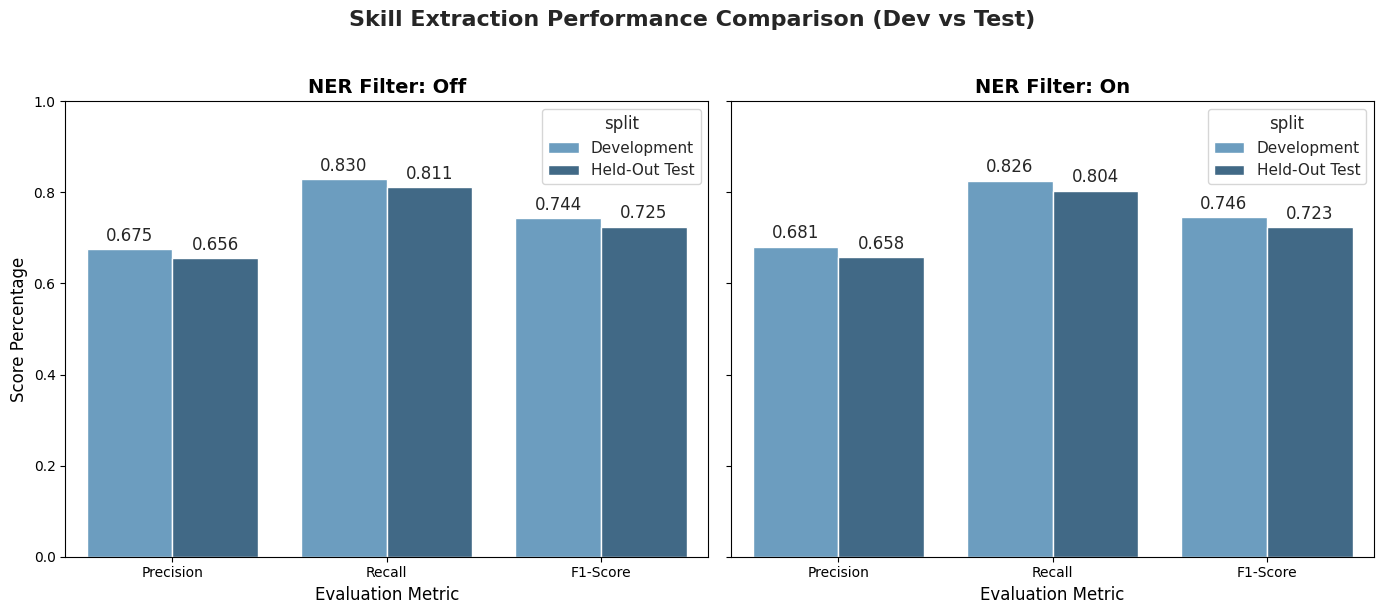

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Populate data based on the gold set evaluations in cell 60a3f845
performance_data = [
    # ner_filter = False
    {"ner_filter": "Off", "split": "Development", "Metric": "Precision", "Value": 0.675},
    {"ner_filter": "Off", "split": "Development", "Metric": "Recall", "Value": 0.830},
    {"ner_filter": "Off", "split": "Development", "Metric": "F1-Score", "Value": 0.744},
    {"ner_filter": "Off", "split": "Held-Out Test", "Metric": "Precision", "Value": 0.656},
    {"ner_filter": "Off", "split": "Held-Out Test", "Metric": "Recall", "Value": 0.811},
    {"ner_filter": "Off", "split": "Held-Out Test", "Metric": "F1-Score", "Value": 0.725},

    # ner_filter = True
    {"ner_filter": "On", "split": "Development", "Metric": "Precision", "Value": 0.681},
    {"ner_filter": "On", "split": "Development", "Metric": "Recall", "Value": 0.826},
    {"ner_filter": "On", "split": "Development", "Metric": "F1-Score", "Value": 0.746},
    {"ner_filter": "On", "split": "Held-Out Test", "Metric": "Precision", "Value": 0.658},
    {"ner_filter": "On", "split": "Held-Out Test", "Metric": "Recall", "Value": 0.804},
    {"ner_filter": "On", "split": "Held-Out Test", "Metric": "F1-Score", "Value": 0.723}
]

df_perf = pd.DataFrame(performance_data)

# Plot configuration
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
sns.set_theme(style="whitegrid")

for i, (ner_state, ax) in enumerate(zip(["Off", "On"], axes)):
    sub_df = df_perf[df_perf["ner_filter"] == ner_state]
    sns.barplot(
        data=sub_df,
        x="Metric",
        y="Value",
        hue="split",
        palette="Blues_d",
        ax=ax
    )
    ax.set_title(f"NER Filter: {ner_state}", fontsize=14, fontweight="bold")
    ax.set_ylim(0, 1.0)
    ax.set_xlabel("Evaluation Metric", fontsize=12)
    if i == 0:
        ax.set_ylabel("Score Percentage", fontsize=12)
    else:
        ax.set_ylabel("")

    # Add value annotations on top of the bars
    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f", padding=3)

plt.suptitle("Skill Extraction Performance Comparison (Dev vs Test)", fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

## 8. Extract the documents the gap analysis needs

Uses the selected `EXTRACTION_CFG`. Results are cached on Drive, so a re-run only processes new documents and an interrupted run resumes where it stopped.

- **Postings:** for each role below, up to `MAX_POSTINGS_PER_ROLE` postings whose **title** matches the pattern. Edit `ROLE_PATTERNS` (regular expressions, case-insensitive); the role names must match the roles you use in the gap gold file. Roles with fewer than ~30 matching postings give weak profiles, and the cell warns you.
- **Resumes:** every resume listed in `gap_gold.csv` (if it exists) plus `RESUME_SAMPLE` random resumes for the ESCO-linking sheet. If `gap_gold.csv` does not exist yet, section 12b extracts its resumes later. Set `EXTRACT_ALL_RESUMES = True` to do all of them (hours on CPU).
- **Linking sample:** `LINK_SAMPLE_POSTINGS` random postings.

Time guide from earlier runs on CPU: about 10 min per 100 postings and 13 min per 100 resumes with both models; the knowledge model alone is roughly half of that.

In [16]:
# ==============================================================================
# 8a. Restore the extraction configuration selected in section 7
# ==============================================================================
# Section 7a selects EXTRACTION_CFG, but only in the session where it runs. In a new session where section 7 was skipped,
# the notebook would silently fall back to DEFAULT_CFG, which has a different cache key and re-extracts every document.
# This cell reloads the configuration saved by section 7c. It is harmless in a session where 7a just ran.
_cfg_file = os.path.join(RESULTS_DIR, 'extraction_config.json')
if os.path.exists(_cfg_file):
    _saved = json.load(open(_cfg_file))['config']
    _saved['models'] = tuple(_saved['models'])
    EXTRACTION_CFG = _saved
    print("EXTRACTION_CFG restored from results/extraction_config.json:", EXTRACTION_CFG)
else:
    print("results/extraction_config.json not found: run sections 7a and 7c first. Using:", EXTRACTION_CFG)


EXTRACTION_CFG restored from results/extraction_config.json: {'models': ('knowledge',), 'tau': {'knowledge': 0.5}, 'min_score': 0.0, 'pos_filter': False, 'max_words': 6, 'gazetteer': True, 'rule_filter': False, 'ner_filter': False, 'tool_guard': True}


In [17]:
# v21: moved from the matching section. This changes EXTRACTION, so it must be set before the documents are extracted (section 8 onward),
# otherwise the gold resumes are extracted one way and live CVs another. The first run re-extracts once because the cache key changes.
# v22: the link-override edits that used to be here are in cell 9b-0, in one place.
EXTRACTION_CFG['ner_filter'] = True
print("Enabled NER filter in EXTRACTION_CFG.")


Enabled NER filter in EXTRACTION_CFG.


In [18]:
ROLES = [
    ('business development',    'business development manager', r'business develop|account executive|account manager|key account'),
    # ---- technology
    ('data scientist',          'data scientist',          r'data scientist|machine learning|\bml engineer|\bai engineer|applied scientist'),
    ('data engineer',           'data engineer',           r'data engineer|analytics engineer|\betl\b|big data'),
    ('data analyst',            'data analyst',            r'data analyst|business intelligence|\bbi (analyst|developer)|reporting analyst|analytics analyst'),
    ('devops engineer',         'devops engineer',         r'devops|site reliability|\bsre\b|cloud engineer|platform engineer|infrastructure engineer'),
    ('qa engineer',             'qa engineer',             r'\bqa\b|quality assurance|test engineer|software tester|\bsdet\b|test automation'),
    ('cybersecurity analyst',   'cybersecurity analyst',   r'cyber ?security|information security|security (analyst|engineer)|\bsoc analyst'),
    ('ux designer',             'ux designer',             r'\bux\b|\bui\b|user experience|product designer|interaction designer'),
    ('product manager',         'product manager',         r'product (manager|owner)'),
    ('project manager',         'project manager',         r'project manager|programme manager|program manager|scrum master|project coordinator'),
    ('business analyst',        'business analyst',        r'business analyst|systems analyst|requirements analyst'),
    ('it support', 'it support specialist',                r'it support|help ?desk|service desk|desktop support|technical support|it technician|it specialist|it analyst|systems? support|information technology (support|specialist)'),
    ('systems administrator',   'systems administrator',   r'system(s)? administrator|sysadmin|network (engineer|administrator)|it administrator'),
    ('software',                'software developer',      r'software|\bdevelopers?\b|programmer|full[- ]?stack|front[- ]?end|back[- ]?end'),
    # ---- finance, banking, risk
    ('bookkeeper',              'bookkeeper',              r'bookkeep|accounts? (payable|receivable)|payroll|accounting (clerk|assistant)'),
    ('auditor',                 'auditor',                 r'auditor|\baudit\b'),
    ('credit analyst',          'credit analyst',          r'credit (analyst|officer|manager)|loan officer|underwriter|relationship manager|banker|banking'),
    ('compliance officer',      'compliance officer',      r'compliance|risk (analyst|manager|officer)|regulatory|\baml\b|\bkyc\b'),
    ('financial analyst',       'financial analyst',       r'financial analyst|investment analyst|fp&a|finance'),
    ('accountant',              'accountant',              r'accountant|accounting'),
    # ---- people
    ('recruiter',               'recruiter',               r'recruit|talent acquisition|sourcer'),
    ('human resources',         'human resources',         r'human resources|\bhr\b|people (partner|operations)|talent'),
    # ---- commercial
    ('marketing',               'marketing specialist',    r'marketing|\bseo\b|social media|brand manager|content (marketer|strategist)'),
    ('customer service',        'customer service representative', r'customer (service|support|success)|client services|call cent(er|re)'),
    ('sales',                   'sales representative',    r'\bsales\b'),
    # ---- administration and operations
    ('administrative assistant','administrative assistant',r'administrative|executive assistant|office (manager|administrator|assistant)|secretary|receptionist|personal assistant'),
    ('operations manager',      'operations manager',      r'operations (manager|analyst|coordinator|supervisor)|general manager'),
    ('supply chain',            'supply chain analyst',    r'supply chain|procurement|purchasing|logistics (analyst|coordinator|manager)|\bbuyer\b'),
    # ---- professional services
    ('legal',                   'legal officer',           r'paralegal|legal (counsel|assistant|officer|advisor|secretary)|lawyer|attorney'),
    ('communications',          'communications officer',  r'public relations|communications? (manager|officer|specialist|coordinator)|copywriter|content writer|journalist|\beditor\b'),
    ('research analyst',        'research analyst',        r'research (analyst|associate|officer)|market research|policy analyst'),
    ('consultant',              'management consultant',   r'consultant|strategy (analyst|manager)'),
    ('graphic designer',        'graphic designer',        r'graphic design|visual design|multimedia'),
    # ---- engineering
    ('electrical engineer',     'electrical engineer',     r'electrical engineer'),
    ('mechanical engineer',     'mechanical engineer',     r'mechanical engineer'),
    ('civil engineer',          'civil engineer',          r'civil engineer'),
    # ---- education and programmes (the last two are common in NGO-heavy job markets; delete them if not relevant)
    ('teacher',                 'teacher',                 r'teacher|instructor|lecturer'),
    ('program officer',         'programme officer',       r'programm?e (officer|coordinator|manager|associate)|\bgrants?\b'),
    ('monitoring and evaluation','monitoring and evaluation officer', r'monitoring and evaluation|\bm&e\b|\bmeal\b'),
]
ROLE_PATTERNS = {
    'human resources':   r'human resources|\bhr\b|recruit|talent acquisition',
    'software':          r'software|developer|programmer',
    'accountant':        r'accountant|accounting',
    'sales':             r'\bsales\b',
    'financial analyst': r'financial analyst|finance',
    'teacher':           r'teacher|instructor',
}
ROLE_PATTERNS = {n: p for n, _, p in ROLES}
ROLE_QUERY    = {n: q for n, q, _ in ROLES}
_ROLE_RE      = [(n, re.compile(p, re.I)) for n, _, p in ROLES]

def role_of_title(title):
    """The one role a job title belongs to (first match in ROLES order), or None."""
    t = str(title or '')
    for name, rx in _ROLE_RE:
        if rx.search(t):
            return name
    return None

MAX_POSTINGS_PER_ROLE = 100
MIN_ROLE_POSTINGS     = 30      # a role with fewer matching postings gets no static profile (too noisy)
RESUME_SAMPLE = 200
LINK_SAMPLE_POSTINGS = 100
EXTRACT_ALL_RESUMES = False

print("Extraction config:", EXTRACTION_CFG)
RES_STORE, POST_STORE = DocSpanStore('resumes', EXTRACTION_CFG), DocSpanStore('postings', EXTRACTION_CFG)

has_text  = job_postings[POST_TEXT_COL].fillna('').str.len() > 200
_role_of  = job_postings['title'].fillna('').map(role_of_title)       # ONE role per posting, so profiles do not overlap

role_post_ids, skipped = {}, []
for role in ROLE_PATTERNS:
    pool = job_postings[has_text & (_role_of == role)]
    if len(pool) < MIN_ROLE_POSTINGS:
        skipped.append(role)
        print(f"  {role:26s} matching postings: {len(pool):5d} | SKIPPED (fewer than {MIN_ROLE_POSTINGS})")
        continue
    ids = pool['_jid'].sample(min(MAX_POSTINGS_PER_ROLE, len(pool)), random_state=0).tolist()
    role_post_ids[role] = ids
    print(f"  {role:26s} matching postings: {len(pool):5d} | extracting: {len(ids)}")
print(f"{len(role_post_ids)} roles kept, {len(skipped)} skipped; {int((_role_of.notna() & has_text).sum()):,} postings match some role")

link_post_ids = job_postings[has_text]['_jid'].sample(min(LINK_SAMPLE_POSTINGS, int(has_text.sum())), random_state=42).tolist()
all_post_ids = list(dict.fromkeys([i for v in role_post_ids.values() for i in v] + link_post_ids))

gap_resume_ids = []
_gp = find_gold('gap_gold')
if _gp:
    gap_resume_ids = pd.read_csv(_gp)['resume_id'].astype(str).unique().tolist()
    print(f"resumes listed in {os.path.basename(_gp)}: {len(gap_resume_ids)}")
else:
    print("no gap_gold.csv yet - once it exists in the annotation folder, run section 12b to extract its resumes")
if EXTRACT_ALL_RESUMES:
    all_res_ids = resumes['_rid'].tolist()
else:
    all_res_ids = list(dict.fromkeys(gap_resume_ids + resumes['_rid'].sample(min(RESUME_SAMPLE, len(resumes)), random_state=42).tolist()))
print(f"to extract: {len(all_post_ids)} postings, {len(all_res_ids)} resumes")

_tr = truncation_report([POST_TEXT.get(i, '') for i in all_post_ids[:150]] + [RES_TEXT.get(i, '') for i in all_res_ids[:150]])
print(f"units longer than {MAX_TOKENS} tokens: {_tr['over_limit']} of {_tr['units']} ({_tr['share']:.1%}), 95th percentile {_tr['p95_tokens']} tokens. "
      f"These are now scored in overlapping windows; v16 silently dropped everything after token {MAX_TOKENS} in each of them.")
POST_STORE.ensure(all_post_ids, lambda i: POST_TEXT.get(i, ''))
RES_STORE.ensure(all_res_ids,  lambda i: RES_TEXT.get(i, ''))

Extraction config: {'models': ('knowledge',), 'tau': {'knowledge': 0.5}, 'min_score': 0.0, 'pos_filter': False, 'max_words': 6, 'gazetteer': True, 'rule_filter': False, 'ner_filter': True, 'tool_guard': True}
[resumes] cache spans_v9_resumes_9bea45b9: 395 docs, 18,556 spans
[postings] cache spans_v9_postings_9bea45b9: 3562 docs, 133,947 spans
  business development       matching postings:  2321 | extracting: 100
  data scientist             matching postings:   373 | extracting: 100
  data engineer              matching postings:   444 | extracting: 100
  data analyst               matching postings:   422 | extracting: 100
  devops engineer            matching postings:   529 | extracting: 100
  qa engineer                matching postings:   361 | extracting: 100
  cybersecurity analyst      matching postings:   414 | extracting: 100
  ux designer                matching postings:   291 | extracting: 100
  product manager            matching postings:    57 | extracting: 57
  projec

## 9. Save the extraction outputs and check quality

In [19]:
sp_post, sp_res = POST_STORE.get(all_post_ids), RES_STORE.get(all_res_ids)
sp_post.to_parquet(os.path.join(EXTRACT_DIR, 'spans_postings.parquet'), index=False)
sp_res.to_parquet(os.path.join(EXTRACT_DIR, 'spans_resumes.parquet'), index=False)

# Create a JSON-serializable copy of the EXTRACTION_CFG dictionary
clean_cfg = json.loads(json.dumps(EXTRACTION_CFG, default=list))

manifest = {
    'notebook': '01_extraction', 'created': time.strftime('%Y-%m-%d %H:%M'),
    'config': clean_cfg, 'max_skill_words': EXTRACTION_CFG.get('max_words', MAX_SKILL_WORDS),
    'post_text_col': POST_TEXT_COL, 'res_text_col': RES_TEXT_COL,
    'role_patterns': ROLE_PATTERNS, 'role_posting_ids': role_post_ids,
    'link_sample_posting_ids': link_post_ids, 'resume_ids': all_res_ids, 'gap_gold_resume_ids': gap_resume_ids,
    'n_posting_spans': int(len(sp_post)), 'n_resume_spans': int(len(sp_res)),
}
json.dump(manifest, open(os.path.join(EXTRACT_DIR, 'extraction_manifest.json'), 'w'), indent=2)
print(f"saved to {EXTRACT_DIR}:\n  spans_postings.parquet  {len(sp_post):,} spans / {sp_post['doc_id'].nunique()} docs"
      f"\n  spans_resumes.parquet   {len(sp_res):,} spans / {sp_res['doc_id'].nunique()} docs\n  extraction_manifest.json")

for name, d in [('postings', sp_post), ('resumes', sp_res)]:
    per_doc = d.groupby('doc_id').size()
    n_words = d['skill_text'].str.split().str.len()
    print(f"\n--- {name} ---\nmentions {len(d):,} | docs with >=1: {d['doc_id'].nunique()} | per doc: median {per_doc.median():.0f}, mean {per_doc.mean():.1f}")
    print(f"span length (words): median {n_words.median():.0f}, 90th pct {n_words.quantile(.9):.0f}")
    print("by source:", d['src'].value_counts().to_dict())
    print("most frequent spans:", d['skill_text'].str.lower().value_counts().head(15).to_dict())
    display(d.sample(min(15, len(d)), random_state=1)[['skill_text', 'src', 'unit']].assign(unit=lambda x: x['unit'].str[:90]))

saved to /content/drive/MyDrive/SkillXray/data/processed/extracted:
  spans_postings.parquet  133,947 spans / 3552 docs
  spans_resumes.parquet   18,556 spans / 245 docs
  extraction_manifest.json

--- postings ---
mentions 133,947 | docs with >=1: 3552 | per doc: median 33, mean 37.7
span length (words): median 1, 90th pct 3
by source: {'knowledge': 100936, 'dict': 33011}
most frequent spans: {'communication': 2493, 'sales': 1716, 'lead': 1296, 'leadership': 1164, "bachelor's degree": 835, 'customer service': 830, 'experience': 806, 'accounting': 783, 'knowledge': 759, 'design': 712, 'hr': 670, 'data': 631, 'construction': 606, 'understanding': 583, 'payroll': 568}


,skill_text,src,unit
14963,algorithms,dict,Develop algorithms and models to solve specifi...
85092,Human Resources,dict,Vaco has partnered with a growing Software org...
112868,Nutrition,dict,RAW Nutrition.
20236,enterprise monitoring,knowledge,"Work directly with platform engineers, infrast..."
21622,tools,knowledge,"Leverage cybersecurity data, specifically vuln..."
67419,presentation,dict,"Strong communication, presentation, and projec..."
57467,Skills Network engineering,knowledge,Initial interview with team leader and departm...
117366,best practices,knowledge,Review the content of maintenance work package...
87322,workforce planning,knowledge,This includes workforce planning to ensure hea...
89711,Autism Spectrum Disorder,knowledge,Implements individualized treatment goals and ...



--- resumes ---
mentions 18,556 | docs with >=1: 245 | per doc: median 69, mean 75.7
span length (words): median 1, 90th pct 3
by source: {'knowledge': 13772, 'dict': 4784}
most frequent spans: {'sales': 538, 'customer service': 274, 'communication': 210, 'leadership': 174, 'accounting': 156, 'excel': 116, 'lead': 114, 'payroll': 112, 'database': 112, 'office': 94, 'project management': 93, 'hr': 86, 'information technology': 75, 'word': 69, 'call': 69}


,skill_text,src,unit
15495,modeling,knowledge,"MS Access, Microsoft Excel, MS Excel, MS Offic..."
5944,personnel,knowledge,Education BS : Early Childhood/Special Ed Ball...
7540,database management applications,knowledge,"to problems reported 2 years , Responded to cl..."
1421,trade,knowledge,Experience March 2003 to Current Finance Manag...
18072,Unity 3Ds,knowledge,based on vehicle velocity Unannounced Mobile R...
14932,Market Research Development,knowledge,skills & core competencies Presales and Implem...
5155,data management,knowledge,"Skills Active Directory, Automotive, computer ..."
16015,forms,knowledge,Prepared reports and correspondence: determine...
11624,ICD-9,knowledge,"Proficient in Microsoft Word, Excel, Power poi..."
10071,financial reporting,knowledge,Education STEVENS INSTITUTE OF TECHNOLOGY 2014...


## 9b. Standardise to ESCO and filter out non-skills

Every extracted span is either **mapped to one ESCO skill** (so the same skill always has the same name and identifier) or **rejected as not a skill**. Only accepted skills go forward.

| step | rule | outcome |
|---|---|---|
| 1 | stop words, one- or two-letter fragments, symbols, numbers (`of`, `making`, `lutter`, `$120,000`) | rejected: `junk` |
| 2 | your list in `data/esco/link_overrides.csv` (`DROP`; `MAP` to an exact ESCO label; or `KEEP` = a real tool/standard ESCO lacks, e.g. Pandas, accepted as a curated non-ESCO term under the name in `esco_label`, ignored when the span is already an exact ESCO label; an optional `field` column is not read) | rejected: `override_drop`, or mapped |
| 3 | the span (case, punctuation and plural ignored) equals an ESCO preferred or alternative label | **accepted, exact** |
| 4 | contains education / organisation words (`university`, `inc`, `certificate`, ...) | rejected: `not_skill_words` |
| 5 | SBERT similarity to the nearest ESCO term >= `LINK_THRESHOLD`, and it beats the best *different* skill by >= `LINK_MARGIN` | **accepted** |
| 6 | otherwise: a tool or term from your curated lists (`TOOLS`, `extra_terms.txt`) | accepted, **not in ESCO** (flagged) |
| 7 | otherwise | rejected: `below_threshold` or `ambiguous` |

Accepted spans are collapsed to **one row per document and ESCO skill**, with `esco_label` (the standard name), `esco_uri`, the highest similarity, the number of mentions and the original wordings (`surface_forms`).

`LINK_THRESHOLD` and `LINK_MARGIN` are read from `models/linker/linker_config.json`, which a linker-tuning step can write after tuning them on your linking annotations (`esco_linking_gold.csv`). Until that file exists, the fallback values below are used and the cell prints a warning. Set `KEEP_CURATED_NON_ESCO = False` to drop everything that is not in ESCO.

**Review the audit files.** `results/esco_audit.csv` lists rejected and accepted spans with their reasons. Rejections that are really skills belong in `extra_terms.txt` (or a `MAP` row in `link_overrides.csv`); accepted wrong links belong in `link_overrides.csv` as `DROP`.

**v17:** the accept rule is tuned in the new cell **9a-2** (below the definitions, above the run) on `esco_linking_gold.csv`, and two optional guards exist: `hub_beta` (down-weights ESCO labels that are close to everything) and `lexical_guard` (below `guard_hi`, a fuzzy link must share a content word with the ESCO label). They are used only when the tuning selects them. Rejections by the guard are recorded with the reason `no_lexical_support`.


In [20]:
import os
import re
import json
import torch
import numpy as np
import pandas as pd

try:
    from sentence_transformers import SentenceTransformer
except ImportError:
    get_ipython().system('pip install -q sentence-transformers')
    from sentence_transformers import SentenceTransformer

BASE_DIR = '/content/drive/MyDrive/SkillXray'
ESCO_DIR = os.path.join(BASE_DIR, 'data/esco')

if 'esco_skills' not in globals():
    esco_skills_path = os.path.join(ESCO_DIR, 'skills_en.csv')
    if os.path.exists(esco_skills_path):
        esco_skills = pd.read_csv(esco_skills_path)
    else:
        raise FileNotFoundError(f"ESCO skills file not found at {esco_skills_path}. Please make sure setup stage was completed.")

# ------------------------------------------------------------------ upgraded settings
SBERT_NAME = 'BAAI/bge-large-en-v1.5'
SBERT_DIR = os.path.join(BASE_DIR, 'models/sbert')
os.makedirs(SBERT_DIR, exist_ok=True)

# Namespace the cached embedding files with a sanitized slug of the upgraded model name
sanitized_sbert_name = re.sub(r'[^a-zA-Z0-9.-]', '_', SBERT_NAME)
ESCO_EMB_PATH = os.path.join(SBERT_DIR, f'esco_term_embeddings_{sanitized_sbert_name}.npy')
HUB_PATH = os.path.join(SBERT_DIR, f'esco_hubness_k10_{sanitized_sbert_name}.npy')

LINKER_CFG_PATH = os.path.join(BASE_DIR, 'models/linker/linker_config.json')
LINK_OVERRIDES_PATH = os.path.join(ESCO_DIR, 'link_overrides.csv')
NON_SKILL_PATTERN = r"\b(university|college|institute|school|academy|inc|llc|ltd|corp|corporation|company|certificate|diploma|bachelor|master|associate degree)\b"

LINK_THRESHOLD_FALLBACK, LINK_MARGIN_FALLBACK = 0.45, 0.01
LINK_THRESHOLD_OVERRIDE = 0.60
LINK_MARGIN_OVERRIDE = 0.05
KEEP_CURATED_NON_ESCO = True

HUB_K = 10
LEX_STOP_WORDS = {'of', 'and', 'the', 'for', 'in', 'to', 'with', 'a', 'an', 'on', 'at', 'by', 'use', 'using', 'perform', 'manage', 'apply',
                  'carry', 'out', 'ensure', 'conduct', 'provide', 'develop', 'create', 'work', 'skill', 'knowledge', 'experience', 'ability',
                  'basic', 'principles', 'technique'}
HUB_BETA, LEX_GUARD, GUARD_HI, LINK_MODE = 0.0, False, 0.85, 'sbert'
LINK_TUNED = False

if os.path.exists(LINKER_CFG_PATH):
    _cfg = json.load(open(LINKER_CFG_PATH))
    _g = lambda *keys, default=None: next((_cfg[k] for k in keys if k in _cfg), default)

    # Invalidate stale configuration if model names mismatch
    saved_sbert_model = _cfg.get('sbert_model', _cfg.get('sbert', ''))
    if saved_sbert_model != SBERT_NAME:
        print(f"[!] Warning: Saved linker configuration used model '{saved_sbert_model}', but SBERT_NAME is '{SBERT_NAME}'. Ignoring tuned configuration. Re-run cell 9a-2.")
        LINK_THRESHOLD, LINK_MARGIN = LINK_THRESHOLD_FALLBACK, LINK_MARGIN_FALLBACK
    else:
        LINK_THRESHOLD = float(_g('link_threshold', 'threshold', default=LINK_THRESHOLD_FALLBACK))
        LINK_MARGIN = float(_g('link_margin', 'margin', default=LINK_MARGIN_FALLBACK))
        LINK_TUNED = bool(_cfg.get('tuned_on_annotations', False))
        HUB_BETA = float(_g('hub_beta', default=0.0))
        LEX_GUARD = bool(_g('lexical_guard', default=False))
        GUARD_HI = float(_g('guard_hi', default=0.85))
        LINK_MODE = str(_g('link_mode', default='sbert'))
else:
    LINK_THRESHOLD, LINK_MARGIN = LINK_THRESHOLD_FALLBACK, LINK_MARGIN_FALLBACK

if not LINK_TUNED:
    if LINK_THRESHOLD_OVERRIDE is not None:
        LINK_THRESHOLD = float(LINK_THRESHOLD_OVERRIDE)
    if LINK_MARGIN_OVERRIDE is not None:
        LINK_MARGIN = float(LINK_MARGIN_OVERRIDE)

print(f"link rule ({LINK_MODE}, {'tuned' if LINK_TUNED else 'manual'}): score >= {LINK_THRESHOLD:.2f} and margin >= {LINK_MARGIN:.2f}, or exact ESCO label")

# ------------------------------------------------------------------ ESCO labels and descriptions
_alts = esco_skills['altLabels'] if 'altLabels' in esco_skills.columns else pd.Series([None] * len(esco_skills))
_descs = esco_skills['description'] if 'description' in esco_skills.columns else pd.Series([''] * len(esco_skills))
_terms = []
for uri, pref, alt, desc in zip(esco_skills['conceptUri'], esco_skills['preferredLabel'], _alts, _descs):
    if not isinstance(pref, str):
        continue
    d_text = str(desc).strip() if isinstance(desc, str) else ''
    _terms.append((pref, uri, pref, d_text))
    if isinstance(alt, str):
        _terms += [(a.strip(), uri, pref, d_text) for a in alt.split('\n') if a.strip()]

esco_terms_df = (pd.DataFrame(_terms, columns=['term', 'conceptUri', 'preferredLabel', 'description'])
                   .drop_duplicates(subset=['term']).reset_index(drop=True))

def _norm_key(s):
    words = re.sub(r"[^a-z0-9+#]+", " ", str(s).lower()).split()
    return " ".join(w[:-1] if len(w) > 3 and w.endswith("s") and not w.endswith("ss") else w for w in words)

EXACT = {}
for _i, _t in enumerate(esco_terms_df['term'].values):
    EXACT.setdefault(_norm_key(_t), _i)
URI_OF_LABEL = dict(zip(esco_skills['preferredLabel'], esco_skills['conceptUri']))
CURATED = {_norm_key(t): t for t in list(TOOLS) + list(EXTRA_TERMS)} if 'TOOLS' in globals() and 'EXTRA_TERMS' in globals() else {}
print(f"ESCO: {len(esco_skills):,} skills, {len(esco_terms_df):,} labels | curated tools/terms: {len(CURATED)}")

# ------------------------------------------------------------------ SBERT + embeddings
_DEV = 'cuda' if torch.cuda.is_available() else 'cpu'
sbert_model = SentenceTransformer(SBERT_NAME, device=_DEV)

enriched_texts = []
for t, d in zip(esco_terms_df['term'].values, esco_terms_df['description'].values):
    if d:
        enriched_texts.append(f"{t}: {d[:120]}")
    else:
        enriched_texts.append(str(t))

if os.path.exists(ESCO_EMB_PATH) and np.load(ESCO_EMB_PATH, mmap_mode='r').shape[0] == len(esco_terms_df):
    _E = np.load(ESCO_EMB_PATH).astype(np.float32); print("loaded cached ESCO embeddings", _E.shape)
else:
    _E = sbert_model.encode(enriched_texts, batch_size=128, show_progress_bar=True, convert_to_numpy=True).astype(np.float32)
    np.save(ESCO_EMB_PATH, _E); print("computed and cached enriched ESCO embeddings", _E.shape)

ESCO_EMB = _E / np.maximum(np.linalg.norm(_E, axis=1, keepdims=True), 1e-9)
_ESCO_T = None
_TOPK_CACHE = {}
K_RETRIEVE = 10

def esco_topk(texts, k=K_RETRIEVE, chunk=1024):
    global _ESCO_T
    texts = [str(t) for t in texts]
    k = min(k, K_RETRIEVE)
    uniq = [t for t in dict.fromkeys(texts)]
    new = [t for t in uniq if t not in _TOPK_CACHE]
    if new:
        q = sbert_model.encode(new, batch_size=128, normalize_embeddings=True, convert_to_numpy=True,
                               show_progress_bar=len(new) > 2000).astype(np.float32)
        if _ESCO_T is None:
            _ESCO_T = torch.from_numpy(ESCO_EMB).to(_DEV)
        for i in range(0, len(q), chunk):
            s, j = (torch.from_numpy(q[i:i + chunk]).to(_DEV) @ _ESCO_T.T).topk(K_RETRIEVE, dim=1)
            for t, sr, jr in zip(new[i:i + chunk], s.cpu().numpy(), j.cpu().numpy()):
                _TOPK_CACHE[t] = (sr, jr)
    sc = np.stack([_TOPK_CACHE[t][0][:k] for t in texts]) if texts else np.zeros((0, k), np.float32)
    ix = np.stack([_TOPK_CACHE[t][1][:k] for t in texts]) if texts else np.zeros((0, k), np.int64)
    return sc, ix

# ------------------------------------------------------------------ hubness correction
HUB_R = None
if os.path.exists(HUB_PATH):
    _h = np.load(HUB_PATH)
    if _h.shape[0] == len(esco_terms_df):
        HUB_R = _h.astype(np.float32)
HUB_R_MEAN = float(HUB_R.mean()) if HUB_R is not None else 0.0

def compute_hubness(span_texts, k=HUB_K, chunk=4096):
    global HUB_R, HUB_R_MEAN, _ESCO_T
    q = sbert_model.encode(list(span_texts), batch_size=256, normalize_embeddings=True, convert_to_numpy=True,
                           show_progress_bar=True).astype(np.float32)
    Q = torch.from_numpy(q).to(_DEV)
    if _ESCO_T is None:
        _ESCO_T = torch.from_numpy(ESCO_EMB).to(_DEV)
    kk = min(k, Q.shape[0])
    r = np.zeros(ESCO_EMB.shape[0], np.float32)
    for i in range(0, ESCO_EMB.shape[0], chunk):
        r[i:i + chunk] = (_ESCO_T[i:i + chunk] @ Q.T).topk(kk, dim=1).values.mean(1).cpu().numpy()
    r = pd.Series(r).groupby(esco_terms_df['conceptUri'].to_numpy()).transform('mean').to_numpy(np.float32)
    np.save(HUB_PATH, r)
    HUB_R, HUB_R_MEAN = r, float(r.mean())
    return r

def _stem(w):
    for suf in ('ments', 'ment', 'ing', 'ers', 'er', 'ions', 'ion', 'ed', 'ly', 'al', 'es', 's'):
        if w.endswith(suf) and len(w) - len(suf) >= 3:
            return w[:-len(suf)]
    return w

def _content_stems(s):
    return {_stem(w) for w in _norm_key(s).split() if w not in LEX_STOP_WORDS and len(w) > 2}

def lexically_related(span, matched_term, preferred_label):
    return bool(_content_stems(span) & (_content_stems(matched_term) | _content_stems(preferred_label)))

LINK_CFG = {'threshold': LINK_THRESHOLD, 'margin': LINK_MARGIN, 'hub_beta': HUB_BETA, 'lexical_guard': LEX_GUARD, 'guard_hi': GUARD_HI, 'link_mode': LINK_MODE}

# ------------------------------------------------------------------ rejection rules
STOP_WORDS = {"a", "an", "and", "or", "the", "of", "in", "on", "at", "to", "for", "with", "by", "from", "as", "is", "are", "was",
              "be", "been", "this", "that", "these", "those", "it", "its", "their", "our", "your", "we", "you", "they", "he",
              "she", "i", "not", "no", "yes", "making", "using", "used", "use", "work", "working", "worked", "etc",
              "including", "such", "also", "well", "new", "good", "strong"}
ALLOW_SHORT = {"c", "r", "go", "ai", "ml", "ui", "ux", "qa", "hr", "it", "bi", "c#", "c++", ".net", "sql", "aws", "gcp", "css", "php", "kra", "psv"}
NON_SKILL_RE = re.compile(NON_SKILL_PATTERN, re.I)

def is_junk(span):
    low = span.strip().lower()
    if not re.search(r"[A-Za-z]", span):
        return True
    if low in STOP_WORDS and span.strip() != "IT":
        return True
    if low == "it" and span.strip() != "IT":
        return True
    if len(low) < 3 and low not in ALLOW_SHORT:
        return True
    if low in ALLOW_SHORT:
        return "$" in span
    letters = sum(ch.isalpha() for ch in span)
    return "$" in span or letters < 0.5 * len(span)

if not os.path.exists(LINK_OVERRIDES_PATH):
    pd.DataFrame([('best practices', 'DROP', ''), ('knowledge', 'DROP', ''), ('data', 'DROP', ''), ('integrity', 'DROP', '')],
                 columns=['span', 'action', 'esco_label']).to_csv(LINK_OVERRIDES_PATH, index=False)
REQUIRED_DROPS = ['TS/SCI', 'TS/SCI w']
if os.path.exists(LINK_OVERRIDES_PATH):
    _ov = pd.read_csv(LINK_OVERRIDES_PATH, dtype=str).fillna('')
    _have = set(_ov['span'].str.strip().str.lower())
    _add = [{'span': s, 'action': 'DROP', 'esco_label': ''} for s in REQUIRED_DROPS if s.strip().lower() not in _have]
    if _add:
        pd.concat([_ov, pd.DataFrame(_add)], ignore_index=True).to_csv(LINK_OVERRIDES_PATH, index=False)

def load_overrides():
    ov = pd.read_csv(LINK_OVERRIDES_PATH, dtype=str).fillna('')
    ov.columns = [c.strip().lower() for c in ov.columns]
    return {_norm_key(r.span): (r.action.strip().upper(), r.esco_label.strip()) for r in ov.itertuples() if r.span.strip()}
LINK_OVERRIDES = load_overrides()
print(f"{len(LINK_OVERRIDES)} curated link overrides")

link rule (sbert, tuned): score >= 0.82 and margin >= 0.00, or exact ESCO label


ESCO: 13,960 skills, 99,676 labels | curated tools/terms: 752


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

loaded cached ESCO embeddings (99676, 1024)
452 curated link overrides


In [21]:
# ==============================================================================
# 9b-0. Curated link overrides: ONE place (v22; v21 edited link_overrides.csv in four cells, two of which disagreed on 'vs code')
# ==============================================================================
# Needs cell 9b (LINK_OVERRIDES_PATH, load_overrides, EXACT, _norm_key).
# Consolidation: Merged the rules from cell LLNgDhZY039z directly here.

WANTED_OVERRIDES = [
    ('pandas',             'KEEP', 'Pandas'),
    ('honours',            'DROP', ''),
    ('farmer',             'DROP', ''),
    ('vs code',            'MAP',  'integrated development environment software'),
    ('restful api design', 'MAP',  'design application interfaces'),
    ('led',                'MAP',  'lead others'),
    # Consolidated from Section 22 (LLNgDhZY039z)
    ('project management', 'MAP',  'project management principles'),
    ('project manager',    'MAP',  'project management principles'),
    ('banking',            'MAP',  'banking activities'),
    ('private banking',    'MAP',  'banking activities'),
    ('ms office',          'MAP',  'use microsoft office'),
    ('financial analysis', 'MAP',  'financial analysis'),
    ('filing',             'MAP',  'file documents'),
    ('data entry',         'KEEP', 'data entry'),
    ('call',               'DROP', ''),
    ('history',            'DROP', ''),
]

_cur = pd.read_csv(LINK_OVERRIDES_PATH, dtype=str).fillna('') if os.path.exists(LINK_OVERRIDES_PATH) else pd.DataFrame(columns=['span', 'action', 'esco_label'])
_cur.columns = [c.strip().lower() for c in _cur.columns]
_new = pd.DataFrame(WANTED_OVERRIDES, columns=['span', 'action', 'esco_label'])
_cur = _cur[~_cur['span'].str.strip().str.lower().isin(set(_new['span']))]          # the same span is never listed twice
pd.concat([_cur, _new], ignore_index=True).to_csv(LINK_OVERRIDES_PATH, index=False)
LINK_OVERRIDES = load_overrides()
if 'PROTECTED_EXTRA' in globals():
    PROTECTED_EXTRA.update(_load_protected_from_overrides())
_bad = [(s, l) for s, a, l in WANTED_OVERRIDES if a == 'MAP' and EXACT.get(_norm_key(l)) is None]
print(f"{len(LINK_OVERRIDES)} link overrides active. MAP targets that do not resolve to an ESCO label (those spans are rejected): {_bad}")

452 link overrides active. MAP targets that do not resolve to an ESCO label (those spans are rejected): []


### 9b-1. `standardise_spans` and `collapse_to_skills` (reconstructed)

**These two functions were missing from the notebook you uploaded** (both v18 versions): they are called in 9a-2, 9b, 12b, 13 and later, but nothing defined them, which is the `NameError`. This cell rewrites them from the rule table in the 9b description above and from how the rest of the notebook uses their output (columns `status`, `reason`, `esco_label`, `esco_uri`, `in_esco`, `similarity`, `margin`, `exact`; one row per document and ESCO skill after collapsing).

If you have the original cell (Colab: File > Revision history, or an earlier copy of the notebook), use that instead and delete this one. Small details such as how ties and the hubness correction are handled may differ from your original, so numbers from 9a-2 onward are only comparable with earlier runs if the original is restored.

In [22]:
# ==============================================================================
# 9b-1. standardise_spans and collapse_to_skills   (v22: ONE definition each; reconstructed in v21)
# ==============================================================================
# Needs the previous cell (EXACT, CURATED, LINK_OVERRIDES, LINK_CFG, esco_terms_df, esco_topk, HUB_R, lexically_related, is_junk, NON_SKILL_RE).
# Reads LINK_CFG / HUB_R at CALL time, so the tuning in 9a-2 (which rebinds them) takes effect without re-running this cell.
# Order of the rules is the table in section 9b: junk -> overrides -> exact ESCO label -> education/organisation words ->
# SBERT rule (or SBERT retrieval + cross-encoder rerank when link_mode == 'cross_encoder') -> curated non-ESCO term -> rejected.
from collections import defaultdict
SKILL_COLS = ['doc_id', 'esco_uri', 'esco_label', 'in_esco', 'similarity', 'exact', 'mentions', 'surface_forms']
_STD_COLS  = ['status', 'reason', 'esco_label', 'esco_uri', 'in_esco', 'similarity', 'margin', 'exact', 'matched_term']

RERANKER_NAME = 'BAAI/bge-reranker-large'
_RERANKER = None
def score_cross_encoder(pairs):
    """(context, ESCO label) pairs -> probability-like scores. The model is loaded on first use, so the default sbert mode never pays for it."""
    global _RERANKER
    if not pairs:
        return np.array([], dtype=np.float32)
    if _RERANKER is None:
        from sentence_transformers import CrossEncoder
        _RERANKER = CrossEncoder(RERANKER_NAME, device=_DEV)
    return 1.0 / (1.0 + np.exp(-_RERANKER.predict(pairs, batch_size=256, convert_to_numpy=True)))

def standardise_spans(spans, cfg=None):
    """
    The ONE linker (v22). Supports:
    - LINK_MODE = 'sbert' (Fast SBERT vector lookup with optional hubness correction)
    - LINK_MODE = 'cross_encoder' (Two-stage: Top-10 SBERT retrieval + Contextual Cross-Encoder joint-attention scoring)
    """
    c = {**LINK_CFG, **(cfg or {})}
    mode = c.get('link_mode', LINK_MODE)

    df = spans.reset_index(drop=True)
    df = df.drop(columns=[x for x in _STD_COLS if x in df.columns], errors='ignore')

    texts = df['skill_text'].astype(str).tolist()
    units = df['unit'].astype(str).tolist() if 'unit' in df.columns else [''] * len(df)

    P = esco_terms_df['preferredLabel'].to_numpy(dtype=object)
    U = esco_terms_df['conceptUri'].to_numpy(dtype=object)
    T = esco_terms_df['term'].to_numpy(dtype=object)

    def rej(reason, sim=0.0, margin=0.0):
        return ('rejected', reason, '', '', False, float(sim), float(margin), False, '')
    def acc(label, uri, in_esco, sim, margin, exact, term=''):
        return ('accepted', '', label, uri, bool(in_esco), float(sim), float(margin), bool(exact), term)

    out = {}
    need_idx = []
    need_texts = []
    need_units = []

    # Stage 0: Strict overrides, exact matches, and syntactic junk rejections
    for idx, (t, u_text) in enumerate(zip(texts, units)):
        key = _norm_key(t)
        if is_junk(t):
            out[idx] = rej('junk'); continue

        ov = LINK_OVERRIDES.get(key)
        j = EXACT.get(key)

        if ov and not (ov[0] == 'KEEP' and j is not None):
            action, lab = ov
            if action == 'DROP':
                out[idx] = rej('override_drop'); continue
            if action == 'MAP':
                jm = EXACT.get(_norm_key(lab))
                out[idx] = acc(P[jm], U[jm], True, 1.0, 1.0, False, lab) if jm is not None else rej('override_bad_map')
                continue
            if action == 'KEEP':
                if not KEEP_CURATED_NON_ESCO:
                    out[idx] = rej('not_in_esco'); continue
                name = lab or t
                out[idx] = acc(name, 'curated:' + _norm_key(name), False, 1.0, 1.0, False, name); continue

        if j is not None:
            out[idx] = acc(P[j], U[j], True, 1.0, 1.0, True, T[j]); continue

        if NON_SKILL_RE.search(t):
            out[idx] = rej('not_skill_words'); continue

        need_idx.append(idx)
        need_texts.append(t)
        need_units.append(u_text)

    if need_idx:
        # Retrieve top 10 potential candidates via bi-encoder indexing
        sc, ix = esco_topk(need_texts, k=K_RETRIEVE)

        if mode == 'cross_encoder':
            # Prep pairs for Stage-2 Joint Attention Cross-Encoder scoring
            rerank_pairs = []
            pair_mappings = []

            for local_i, (global_i, t, u_text) in enumerate(zip(need_idx, need_texts, need_units)):
                best_concepts = {}
                for k_idx in range(K_RETRIEVE):
                    jj = ix[local_i, k_idx]
                    concept_uri = U[jj]
                    raw_cosine = float(sc[local_i, k_idx])
                    if concept_uri not in best_concepts or raw_cosine > best_concepts[concept_uri]['cosine']:
                        best_concepts[concept_uri] = {
                            'label': P[jj],
                            'cosine': raw_cosine,
                            'term_idx': jj
                        }

                # Anchor cross-encoder query on target span with robust context fallbacks
                ctx = f"{t} (context: {u_text})" if (u_text and u_text.strip().lower() != t.strip().lower()) else t
                for concept_uri, info in best_concepts.items():
                    rerank_pairs.append((ctx, info['label']))
                    pair_mappings.append((global_i, concept_uri, info['label'], info['cosine'], info['term_idx']))

            # Joint scoring through the Cross-Encoder pipeline
            rerank_scores = score_cross_encoder(rerank_pairs)

            # Group scores back to global text items
            grouped_candidates = defaultdict(list)
            for score_val, mapping in zip(rerank_scores, pair_mappings):
                global_i, uri, label, cosine, term_idx = mapping
                grouped_candidates[global_i].append((score_val, cosine, uri, label, term_idx))

            for global_i in need_idx:
                candidates = sorted(grouped_candidates[global_i], reverse=True, key=lambda x: x[0])
                best_score, best_cosine, best_uri, best_label, best_term_idx = candidates[0]

                margin = best_score - candidates[1][0] if len(candidates) > 1 else best_score

                is_accepted = best_score >= c['threshold'] and margin >= c['margin']

                # Optional lexical validation guard
                if is_accepted and c.get('lexical_guard') and best_cosine < c.get('guard_hi', 0.85) and not lexically_related(texts[global_i], T[best_term_idx], best_label):
                    is_accepted = False

                if is_accepted:
                    out[global_i] = acc(best_label, best_uri, True, best_cosine, margin, False, T[best_term_idx])
                else:
                    t_original = texts[global_i]
                    key = _norm_key(t_original)
                    if KEEP_CURATED_NON_ESCO and key in CURATED:
                        name = CURATED[key]
                        out[global_i] = acc(name, 'curated:' + _norm_key(name), False, 1.0, margin, False, name)
                    else:
                        out[global_i] = rej('below_threshold', best_cosine, margin)

        else: # Standard SBERT mode with optional hubness correction
            hb = float(c.get('hub_beta', 0.0) or 0.0)
            use_hub = hb > 0 and HUB_R is not None
            for local_i, (global_i, t) in enumerate(zip(need_idx, need_texts)):
                srow, irow = sc[local_i], ix[local_i]
                adj = (srow - hb * (HUB_R[irow] - HUB_R_MEAN)) if use_hub else srow

                best_concepts = {}
                for a, r, jj in zip(adj, srow, irow):
                    u_uri = U[jj]
                    if u_uri not in best_concepts or a > best_concepts[u_uri][0]:
                        best_concepts[u_uri] = (float(a), float(r), int(jj))

                ranked = sorted(best_concepts.values(), reverse=True)
                a1, r1, j1 = ranked[0]
                margin = a1 - ranked[1][0] if len(ranked) > 1 else a1

                ok = a1 >= c['threshold'] and margin >= c['margin']
                guard_fail = False
                if ok and c.get('lexical_guard') and r1 < c.get('guard_hi', 0.85) and not lexically_related(t, T[j1], P[j1]):
                    ok, guard_fail = False, True

                if ok:
                    out[global_i] = acc(P[j1], U[j1], True, r1, margin, False, T[j1])
                else:
                    key = _norm_key(t)
                    if KEEP_CURATED_NON_ESCO and key in CURATED:
                        name = CURATED[key]
                        out[global_i] = acc(name, 'curated:' + _norm_key(name), False, 1.0, margin, False, name)
                    else:
                        reason = 'no_lexical_support' if guard_fail else ('ambiguous' if a1 >= c['threshold'] else 'below_threshold')
                        out[global_i] = rej(reason, r1, margin)

    # Formulate output DataFrame
    res_rows = [out[i] for i in range(len(df))]
    res = pd.DataFrame(res_rows, columns=_STD_COLS, index=df.index)
    res['in_esco'] = res['in_esco'].astype(bool)
    res['exact'] = res['exact'].astype(bool)
    return pd.concat([df, res], axis=1)

def collapse_to_skills(sp):
    """Accepted spans -> one row per (doc_id, esco_uri): standard name, highest similarity, number of mentions, original wordings."""
    acc = sp[sp['status'] == 'accepted']
    if acc.empty:
        return pd.DataFrame(columns=SKILL_COLS)
    g = (acc.assign(doc_id=acc['doc_id'].astype(str))
            .groupby(['doc_id', 'esco_uri'], sort=False)
            .agg(esco_label=('esco_label', 'first'), in_esco=('in_esco', 'first'), similarity=('similarity', 'max'),
                 exact=('exact', 'max'), mentions=('skill_text', 'size'),
                 surface_forms=('skill_text', lambda s: sorted({str(x) for x in s})))
            .reset_index())
    return g[SKILL_COLS]

print("standardise_spans (link_mode:", LINK_CFG.get('link_mode', 'sbert') + ") / collapse_to_skills defined.")

standardise_spans (link_mode: sbert) / collapse_to_skills defined.


### 9a-2. Tune the ESCO linker on `esco_linking_gold.csv`

Runs between the linker definitions above and the standardisation run below. It reads your linking annotations (any of the common column layouts; if none matches it prints the columns it found and writes a template), tunes the accept rule with a held-out split and paired bootstrap, and writes `models/linker/linker_config.json`. Chosen with F0.5, so precision counts twice as much as recall.

In [23]:
from collections import defaultdict
# ==============================================================================
# 9a-2. Tune the ESCO linker on esco_linking_gold.csv   (new in v17)
# ==============================================================================
# Until now the linker ran on guessed values (threshold 0.70, margin 0.03) although annotations for it already existed: nothing in the
# notebook read esco_linking_gold.csv. This cell tunes the accept rule on them, and tests two options that target the errors seen in
# the live run ('clearance' -> demining operations, 'design' -> think creatively):
#   hub_beta       lowers the score of labels that are close to everything (hubness correction)
#   lexical_guard  below guard_hi, a fuzzy link must share a content word with the ESCO label
# An option is adopted only when the tuning picks it. Results go to models/linker/linker_config.json; the next cell uses them.
LINK_FBETA      = 0.5     # F-beta used to choose the rule. 0.5 weights precision twice as much as recall, because a wrong link shows up
                          # as a wrong requirement or a false gap in front of the user, while a missed link only loses one skill.
# Capped threshold sweep at 0.82 to avoid collapsing into exact-match-only mode under imbalanced negatives
LINK_GRID = {'threshold': (0.60, 0.65, 0.70, 0.75, 0.78, 0.80, 0.82), 'margin': (0.0, 0.01, 0.02, 0.03),
             'hub_beta': (0.0, 0.5, 1.0), 'lexical_guard': (False, True), 'guard_hi': (0.85, 0.92)}
TUNE_CROSS_ENCODER = torch.cuda.is_available()     # Flip to True on GPU sessions to evaluate cross-encoder reranker performance
# Updated CE Grid to fit BAAI/bge-reranker-large probability distribution with tighter margins
LINK_GRID_CE = {'threshold': (0.35, 0.45, 0.55, 0.65, 0.75), 'margin': (0.0, 0.01, 0.02, 0.03)}
LINK_MIN_ROWS_FOR_SPLIT = 120
_NONE_WORDS = {'', 'none', 'nan', 'null', 'n/a', 'na', 'reject', 'rejected', 'not a skill', 'no', 'no match', 'no_match', 'drop', 'x', '-'}
_YES_WORDS = {'y', 'yes', 'true', '1', 'correct', 'ok', 'good', 'right'}
_NO_WORDS = {'n', 'no', 'false', '0', 'wrong', 'incorrect', 'bad'}

def _pick(df, names):
    low = {c.strip().lower(): c for c in df.columns}
    return next((low[n] for n in names if n in low), None)

def load_linking_gold(path):
    """Reads esco_linking_gold.csv whatever its exact column names. Returns rows
    {span, gold (canonical preferred label, lower-case, or None = should be rejected), certain (False when only 'this link is wrong' is known), bad}
    or None when the file has no usable annotation column."""
    g = pd.read_csv(path, dtype=str).fillna('')
    c_span = _pick(g, ['skill_text', 'span', 'surface', 'surface_form', 'mention', 'phrase', 'text'])
    c_gold = _pick(g, ['gold_label', 'gold_esco_label', 'correct_label', 'correct_esco_label', 'true_label', 'gold_skill', 'correct_skill', 'esco_gold', 'gold'])
    c_pred = _pick(g, ['esco_label', 'predicted_label', 'pred_label', 'linked_label', 'predicted', 'pred', 'candidate'])
    c_verd = _pick(g, ['is_correct', 'correct', 'link_correct', 'link_ok', 'ok', 'valid', 'verdict', 'judgement', 'judgment', 'gold_ok'])
    print(f"{os.path.basename(path)}: {len(g)} rows | columns: {list(g.columns)}")
    print(f"  detected -> span: {c_span} | gold label: {c_gold} | predicted label: {c_pred} | verdict: {c_verd}")
    if c_span is None or (c_gold is None and not (c_pred and c_verd)):
        return None
    pref_of = {t.lower(): p.lower() for t, p in zip(esco_terms_df['term'], esco_terms_df['preferredLabel'])}
    rows = []
    for _, r in g.iterrows():
        span = r[c_span].strip()
        if not span:
            continue
        if c_gold is not None:
            v = r[c_gold].strip()
            if v.lower() in _NONE_WORDS:
                rows.append({'span': span, 'gold': None, 'certain': True, 'bad': set()})
            else:
                rows.append({'span': span, 'gold': pref_of.get(v.lower(), v.lower()), 'certain': True, 'bad': set()})
        else:
            v, p = r[c_verd].strip().lower(), r[c_pred].strip().lower()
            p = pref_of.get(p, p)
            if v in _YES_WORDS and p:
                rows.append({'span': span, 'gold': p, 'certain': True, 'bad': set()})
            elif v in _NO_WORDS:
                rows.append({'span': span, 'gold': None, 'certain': False, 'bad': {p} if p else set()})
    return rows or None

def write_linking_template(n=300, seed=3):
    """Spans to annotate: the current linker's best candidates are listed, the annotator writes the correct ESCO label or NONE."""
    pool = pd.concat([POST_STORE.df['skill_text'], RES_STORE.df['skill_text']]).astype(str)
    pool = pool[~pool.map(is_junk)].drop_duplicates()
    spans = pool.sample(min(n, len(pool)), random_state=seed).tolist()
    sc, ix = esco_topk(spans, k=3)
    tm = esco_terms_df['preferredLabel'].to_numpy(dtype=object)
    tmpl = pd.DataFrame({'span': spans, **{f'candidate_{k + 1}': [f"{tm[ix[r, k]]}  ({sc[r, k]:.2f})" for r in range(len(spans))] for k in range(3)},
                         'gold_label': ''})
    path = os.path.join(ANNOT_DIR, 'esco_linking_gold_template.csv')
    if safe_write_csv(tmpl, path):
        print("wrote", path, "- fill 'gold_label' with the exact ESCO preferred label, or NONE when the span is not a skill / has no ESCO skill; "
              "save it as esco_linking_gold.csv and re-run this cell.")

def _fbeta(c, beta=LINK_FBETA):
    tp, fp, fn = float(c[..., 0]), float(c[..., 1]), float(c[..., 2])
    p, r = (tp / (tp + fp) if tp + fp else 0.0), (tp / (tp + fn) if tp + fn else 0.0)
    return (1 + beta ** 2) * p * r / (beta ** 2 * p + r) if p + r else 0.0

def link_row_counts(cfg, rows):
    """Per-row (tp, fp, fn) of the accept rule `cfg` against the annotations."""
    out = standardise_spans(pd.DataFrame({'skill_text': [r['span'] for r in rows]}), cfg)
    pred = [str(l).lower() if s == 'accepted' else None for s, l in zip(out['status'], out['esco_label'])]
    c = np.zeros((len(rows), 3), np.int32)
    for i, (p, r) in enumerate(zip(pred, rows)):
        if r['gold'] is not None:
            if p == r['gold']:
                c[i, 0] = 1
            else:
                c[i, 2] = 1
                c[i, 1] = int(p is not None)
        elif p is not None and (r['certain'] or p in r['bad']):
            c[i, 1] = 1
    return c

def _link_complexity(cfg):
    return int(cfg['hub_beta'] > 0) + int(cfg['lexical_guard']) + 2 * int(cfg.get('link_mode', 'sbert') == 'cross_encoder')

_gp = find_gold('esco_linking_gold')
LINK_ROWS = load_linking_gold(_gp) if _gp else None
if LINK_ROWS is None:
    print("\nNo usable linking annotations found." if _gp else "\nNo esco_linking_gold.csv found.")
    write_linking_template()
    print("The linker keeps its current values until annotations exist.")
else:
    n = len(LINK_ROWS)
    print(f"{n} annotated spans: {sum(r['gold'] is not None for r in LINK_ROWS)} linkable, {sum(r['gold'] is None for r in LINK_ROWS)} not linkable")
    split = n >= LINK_MIN_ROWS_FOR_SPLIT
    is_test = np.array([_is_test(r['span']) if split else False for r in LINK_ROWS])
    dev_rows = [r for r, t in zip(LINK_ROWS, is_test) if not t]
    test_rows = [r for r, t in zip(LINK_ROWS, is_test) if t]
    if not split:
        print(f"[!] only {n} rows (< {LINK_MIN_ROWS_FOR_SPLIT}): tuning on all of them, so there is no clean test score. Annotate more spans before trusting the numbers.")

    # Invalidate stale config dynamically if model parameters change
    if os.path.exists(LINKER_CFG_PATH):
        try:
            _meta = json.load(open(LINKER_CFG_PATH))
            saved_sbert = _meta.get('sbert_model', _meta.get('sbert', ''))
            if saved_sbert != SBERT_NAME or _meta.get('link_mode') != LINK_MODE:
                print(f"[!] Linker cache mismatch (saved model={saved_sbert}, current model={SBERT_NAME}). Invalidating legacy configuration...")
                shutil.move(LINKER_CFG_PATH, LINKER_CFG_PATH + '.bak')
        except Exception:
            pass

    # hubness statistics from the extracted corpus
    if HUB_R is None:
        print("computing hubness statistics from the extracted spans (once) ...")
        _pool = pd.concat([POST_STORE.df['skill_text'], RES_STORE.df['skill_text']]).astype(str)
        compute_hubness(_pool[~_pool.map(is_junk)].drop_duplicates().tolist())
    esco_topk([r['span'] for r in LINK_ROWS], k=K_RETRIEVE)

    grid = [{'link_mode': 'sbert', 'threshold': t, 'margin': m, 'hub_beta': h, 'lexical_guard': g, 'guard_hi': gh}
            for t in LINK_GRID['threshold'] for m in LINK_GRID['margin'] for h in LINK_GRID['hub_beta']
            for g in LINK_GRID['lexical_guard'] for gh in (LINK_GRID['guard_hi'] if g else (LINK_GRID['guard_hi'][0],))]
    if TUNE_CROSS_ENCODER:
        grid += [{'link_mode': 'cross_encoder', 'threshold': t, 'margin': m, 'hub_beta': 0.0, 'lexical_guard': False, 'guard_hi': 0.85}
                 for t in LINK_GRID_CE['threshold'] for m in LINK_GRID_CE['margin']]
    cur = {'link_mode': 'sbert', 'threshold': LINK_THRESHOLD, 'margin': LINK_MARGIN, 'hub_beta': 0.0, 'lexical_guard': False, 'guard_hi': GUARD_HI}
    print(f"evaluating {len(grid)} accept rules on {len(dev_rows)} development spans ...")
    counts = [link_row_counts(c, dev_rows) for c in tqdm(grid, desc='linker grid')]
    score = np.array([_fbeta(c.sum(0)) for c in counts])
    best_i = int(np.argmax(score))

    # paired bootstrap
    rng = np.random.RandomState(0)
    bi = rng.randint(0, len(dev_rows), (500, len(dev_rows)))
    bs = lambda c: np.array([_fbeta(x) for x in c[bi].sum(1)])
    top = [int(i) for i in np.argsort(-score)[:25]]
    ref = bs(counts[best_i])
    tied = [i for i in top if i == best_i or (score[best_i] - score[i]) <= (ref - bs(counts[i])).std(ddof=1)]
    chosen_i = min(tied, key=lambda i: (_link_complexity(grid[i]), -score[i]))
    CH = grid[chosen_i]

    cur_c = link_row_counts(cur, dev_rows)
    def _prf(c):
        s = c.sum(0); tp, fp, fn = int(s[0]), int(s[1]), int(s[2])
        return {'precision': tp / (tp + fp) if tp + fp else 0.0, 'recall': tp / (tp + fn) if tp + fn else 0.0, f'F{LINK_FBETA}': _fbeta(s)}
    table = pd.DataFrame([{'rule': 'current rule before tuning', **cur, **_prf(cur_c)},
                          {'rule': 'highest dev score', **grid[best_i], **_prf(counts[best_i])},
                          {'rule': 'SELECTED (simplest within 1 SE)', **CH, **_prf(counts[chosen_i])}]).round(3)
    print("\nDevelopment spans:"); display(table)

    test_report = None
    if len(test_rows):
        ct, cc = link_row_counts(CH, test_rows), link_row_counts(cur, test_rows)
        tb = np.random.RandomState(1).randint(0, len(test_rows), (500, len(test_rows)))
        d = np.array([_fbeta(x) for x in ct[tb].sum(1)]) - np.array([_fbeta(x) for x in cc[tb].sum(1)])
        test_report = {'selected': _prf(ct), 'v16_default': _prf(cc), 'delta_fbeta_95ci': [float(np.percentile(d, 2.5)), float(np.percentile(d, 97.5))]}
        print(f"HELD-OUT linking spans ({len(test_rows)}): selected {test_report['selected']} vs v16 default {test_report['v16_default']}")
        print(f"  paired difference in F{LINK_FBETA}: {_fbeta(ct.sum(0)) - _fbeta(cc.sum(0)):+.3f}  (95% interval {np.percentile(d, 2.5):+.3f} to {np.percentile(d, 97.5):+.3f})")

    os.makedirs(os.path.dirname(LINKER_CFG_PATH), exist_ok=True)
    json.dump({'link_mode': CH.get('link_mode', 'sbert'), 'link_threshold': CH['threshold'], 'link_margin': CH['margin'], 'hub_beta': CH['hub_beta'], 'hub_k': HUB_K,
               'lexical_guard': CH['lexical_guard'], 'guard_hi': CH['guard_hi'], 'tuned_on_annotations': True, 'fbeta': LINK_FBETA,
               'n_dev': len(dev_rows), 'n_test': len(test_rows), 'saved': time.strftime('%Y-%m-%d %H:%M'),
               'sbert_model': SBERT_NAME, 'dev': _prf(counts[chosen_i]), 'test': test_report}, open(LINKER_CFG_PATH, 'w'), indent=2)
    LINK_THRESHOLD, LINK_MARGIN, HUB_BETA, LEX_GUARD, GUARD_HI, LINK_TUNED = CH['threshold'], CH['margin'], CH['hub_beta'], CH['lexical_guard'], CH['guard_hi'], True
    LINK_MODE = CH.get('link_mode', 'sbert')
    LINK_CFG = {'threshold': LINK_THRESHOLD, 'margin': LINK_MARGIN, 'hub_beta': HUB_BETA, 'lexical_guard': LEX_GUARD, 'guard_hi': GUARD_HI, 'link_mode': LINK_MODE}
    print("\nsaved", LINKER_CFG_PATH, "-> the next cell uses:", LINK_CFG)

esco_linking_gold.csv: 150 rows | columns: ['link_id', 'source', 'skill_text', 'top1_label', 'top1_sim', 'top2_label', 'top3_label', 'label', 'gold_label']
  detected -> span: skill_text | gold label: gold_label | predicted label: None | verdict: None
150 annotated spans: 30 linkable, 120 not linkable
evaluating 272 accept rules on 98 development spans ...


linker grid:   0%|          | 0/272 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]


Development spans:


,rule,link_mode,threshold,margin,hub_beta,lexical_guard,guard_hi,precision,recall,F0.5
0,current rule before tuning,sbert,0.82,0.00,0.0,False,0.85,0.714,0.556,0.676
1,highest dev score,sbert,0.78,0.01,0.5,False,0.85,0.714,0.556,0.676
2,SELECTED (simplest within 1 SE),sbert,0.82,0.00,0.0,False,0.85,0.714,0.556,0.676


HELD-OUT linking spans (52): selected {'precision': 0.2857142857142857, 'recall': 0.16666666666666666, 'F0.5': 0.24999999999999997} vs v16 default {'precision': 0.2857142857142857, 'recall': 0.16666666666666666, 'F0.5': 0.24999999999999997}
  paired difference in F0.5: +0.000  (95% interval +0.000 to +0.000)

saved /content/drive/MyDrive/SkillXray/models/linker/linker_config.json -> the next cell uses: {'threshold': 0.82, 'margin': 0.0, 'hub_beta': 0.0, 'lexical_guard': False, 'guard_hi': 0.85, 'link_mode': 'sbert'}


In [24]:
# ------------------------------------------------------------------ run on the extracted documents
print("sanity:", [(t, r['esco_label'], round(float(r['similarity']), 2), r['status'], r['reason'])
                  for t, r in zip(['python programming', 'of', 'State University', 'team leadership'],
                                  standardise_spans(pd.DataFrame({'skill_text': ['python programming', 'of', 'State University', 'team leadership']}))
                                  .to_dict('records'))])
t0 = time.time()
esco_spans_post = standardise_spans(POST_STORE.get(all_post_ids))
esco_spans_res = standardise_spans(RES_STORE.get(all_res_ids))
print(f"standardised {len(esco_spans_post):,} posting spans and {len(esco_spans_res):,} resume spans in {(time.time() - t0) / 60:.1f} min")

esco_skills_post, esco_skills_res = collapse_to_skills(esco_spans_post), collapse_to_skills(esco_spans_res)
for nm, d in [('postings', esco_spans_post), ('resumes', esco_spans_res)]:
    print(f"\n--- {nm}: {len(d):,} spans -> {(d['status'] == 'accepted').mean():.0%} accepted ---")
    print("rejection reasons:", d.loc[d['status'] == 'rejected', 'reason'].value_counts().to_dict())
    print(f"accepted: exact ESCO label {(d['exact'] & (d['status'] == 'accepted')).mean():.0%} of all | not in ESCO (curated) "
          f"{((~d['in_esco']) & (d['status'] == 'accepted')).mean():.0%} of all")
for nm, s, k in [('postings', esco_skills_post, 'doc'), ('resumes', esco_skills_res, 'doc')]:
    per = s.groupby('doc_id').size()
    print(f"{nm}: skills per document after standardising: median {per.median():.0f}, mean {per.mean():.1f} ({len(s):,} rows, {s['esco_uri'].nunique():,} distinct skills)")

print("\nMost frequent standardised skills (resumes):")
display(esco_skills_res.groupby(['esco_label', 'in_esco']).agg(docs=('doc_id', 'nunique'), mean_sim=('similarity', 'mean'))
        .sort_values('docs', ascending=False).head(25).round(2).reset_index())
print("Most frequent REJECTED spans (resumes) - any real skills here?")
display(esco_spans_res[esco_spans_res['status'] == 'rejected'].assign(span=lambda d: d['skill_text'].str.lower())
        .groupby(['span', 'reason']).size().sort_values(ascending=False).head(25).rename('count').reset_index())


sanity: [('python programming', '', 0.76, 'rejected', 'below_threshold'), ('of', '', 0.0, 'rejected', 'junk'), ('State University', '', 0.0, 'rejected', 'not_skill_words'), ('team leadership', 'team leadership', 1.0, 'accepted', '')]


Batches:   0%|          | 0/281 [00:00<?, ?it/s]

Batches:   0%|          | 0/39 [00:00<?, ?it/s]

standardised 133,947 posting spans and 18,556 resume spans in 1.5 min

--- postings: 133,947 spans -> 40% accepted ---
rejection reasons: {'below_threshold': 71426, 'not_skill_words': 3486, 'override_drop': 3146, 'junk': 1924}
accepted: exact ESCO label 23% of all | not in ESCO (curated) 13% of all

--- resumes: 18,556 spans -> 42% accepted ---
rejection reasons: {'below_threshold': 9845, 'not_skill_words': 314, 'override_drop': 304, 'junk': 228}
accepted: exact ESCO label 22% of all | not in ESCO (curated) 16% of all
postings: skills per document after standardising: median 10, mean 11.2 (39,402 rows, 2,153 distinct skills)
resumes: skills per document after standardising: median 17, mean 18.3 (4,485 rows, 941 distinct skills)

Most frequent standardised skills (resumes):


,esco_label,in_esco,docs,mean_sim
0,communication,True,145,1.0
1,sales,False,128,1.0
2,customer service,True,125,1.0
3,leadership,False,82,1.0
4,lead others,True,68,1.0
5,project management principles,True,64,1.0
6,excel,False,64,1.0
7,accounting,True,64,1.0
8,Office,False,63,1.0
9,database,True,63,1.0


Most frequent REJECTED spans (resumes) - any real skills here?


,span,reason,count
0,call,override_drop,69
1,training,override_drop,64
2,marketing,below_threshold,43
3,history,override_drop,42
4,software,below_threshold,40
5,processes,below_threshold,39
6,reporting,below_threshold,38
7,experience,below_threshold,37
8,data,override_drop,36
9,documentation,below_threshold,35


In [26]:
# which override keys never fired?
all_keys = set(LINK_OVERRIDES)
fired = set(
    _norm_key(t)
    for df in (esco_spans_post, esco_spans_res)
    for t in df.loc[df['reason'] == 'override_drop', 'skill_text']
)
print(f"{len(all_keys)} override keys, {len(fired)} fired, {len(all_keys - fired)} never matched a span")
print("examples that never fired:", sorted(all_keys - fired)[:30])

452 override keys, 32 fired, 420 never matched a span
examples that never fired: ['401k', '504 plan', 'about us', 'accounting', 'accounting technique', 'active directory', 'adobe acrobat', 'adobe after effect', 'adobe creative cloud', 'adobe creative suite', 'adobe illustrator', 'adobe indesign', 'adobe lightroom', 'adobe photoshop', 'adobe premiere pro', 'adobe xd', 'adp', 'adword', 'after effect', 'agri tech', 'ahref', 'airflow', 'airtable', 'alteryx', 'amazon ec2', 'amazon redshift', 'amazon s3', 'amazon web service', 'anaplan', 'angular']


In [27]:
# surface forms the extractor produced, and whether an override fired
import pandas as pd

sp_all = pd.concat([esco_spans_post.assign(doc_type='posting'),
                    esco_spans_res.assign(doc_type='resume')], ignore_index=True)
sp_all['key'] = sp_all['skill_text'].astype(str).apply(_norm_key)

# which keys did the extractor produce?
produced_keys = set(sp_all['key'])
override_keys = set(LINK_OVERRIDES)

fired     = produced_keys & override_keys
not_fired = override_keys - produced_keys
not_covered = produced_keys - override_keys     # <-- THIS is the important set

print(f"overrides: {len(override_keys)}")
print(f"  fired (override key appears as a span): {len(fired)}")
print(f"  not fired (override key never appears): {len(not_fired)}")
print(f"distinct extracted span keys: {len(produced_keys)}")
print(f"  not covered by any override: {len(not_covered)}")

# what tool names DID the extractor produce?
tools_in_corpus = ['photoshop', 'illustrator', 'angular', 'react', 'node js', 'pandas',
                   'mongodb', 'docker', 'kubernetes', 'excel', 'tableau', 'airflow',
                   'ansible', 'jenkins', 'salesforce', 'jira', 'git', 'java', 'python']
for t in tools_in_corpus:
    hits = sp_all.loc[sp_all['key'].str.contains(t, regex=False), 'skill_text'].value_counts().head(3)
    if len(hits):
        print(f"  {t!r}: {hits.to_dict()}")
    else:
        print(f"  {t!r}: NOT in the corpus")

overrides: 452
  fired (override key appears as a span): 343
  not fired (override key never appears): 109
distinct extracted span keys: 40032
  not covered by any override: 39689
  'photoshop': {'Photoshop': 95, 'Adobe Photoshop': 20, 'Adobe Creative Suite Photoshop': 2}
  'illustrator': {'Illustrator': 86, 'Adobe Illustrator': 20, 'illustrator': 3}
  'angular': {'Angular': 42, 'Angular development experience': 1, 'Angular framework': 1}
  'react': {'React': 48, 'ReactJS': 12, 'React.js': 5}
  'node js': {'Node.js': 18, 'role.Node.js': 1, 'Node JS': 1}
  'pandas': NOT in the corpus
  'mongodb': {'MongoDB': 11, 'MongoDBApache Beam': 1, 'MongoDB queries': 1}
  'docker': {'Docker': 82, 'Docker Hub': 3, 'docker': 2}
  'kubernetes': NOT in the corpus
  'excel': {'Excel': 559, 'Microsoft Excel': 102, 'MS Excel': 47}
  'tableau': {'Tableau': 119, 'Tableau dashboards': 3, 'TABLEAU': 1}
  'airflow': {'Airflow': 19, 'Apache Airflow': 5, 'airflow': 4}
  'ansible': {'Ansible': 55, 'Ansible Automa

In [28]:
import pandas as pd

# Filter the combined corpus for spans not covered by any existing override rules
uncovered_spans = sp_all[sp_all['key'].isin(not_covered)].copy()

# Group and aggregate frequency across postings and resumes
uncovered_summary = (
    uncovered_spans.groupby(['skill_text', 'key'])
    .agg(
        total_mentions=('skill_text', 'size'),
        doc_type_distribution=('doc_type', lambda x: dict(x.value_counts())),
        top_source_component=('src', lambda x: x.value_counts().index[0] if len(x) else '')
    )
    .sort_values(by='total_mentions', ascending=False)
    .reset_index()
)

print(f"Total distinct uncovered span keys: {len(uncovered_summary):,}")
print("\n--- Top 30 Most Frequent Uncovered Spans (Candidates for Overrides) ---")
display(uncovered_summary.head(30))

Total distinct uncovered span keys: 45,862

--- Top 30 Most Frequent Uncovered Spans (Candidates for Overrides) ---


,skill_text,key,total_mentions,doc_type_distribution,top_source_component
0,communication,communication,2491,"{'posting': 2322, 'resume': 169}",dict
1,sales,sale,1582,"{'posting': 1223, 'resume': 359}",dict
2,leadership,leadership,1107,"{'posting': 1002, 'resume': 105}",dict
3,customer service,customer service,760,"{'posting': 596, 'resume': 164}",dict
4,lead,lead,712,"{'posting': 666, 'resume': 46}",dict
5,design,design,691,"{'posting': 654, 'resume': 37}",knowledge
6,Lead,lead,689,"{'posting': 628, 'resume': 61}",dict
7,HR,hr,661,"{'posting': 578, 'resume': 83}",dict
8,Sales,sale,646,"{'posting': 488, 'resume': 158}",dict
9,Bachelor's degree,bachelor s degree,584,"{'posting': 582, 'resume': 2}",knowledge


In [29]:
aud = pd.read_csv(os.path.join(RESULTS_DIR, 'esco_audit.csv'), dtype=str)
aud['similarity'] = pd.to_numeric(aud['similarity'], errors='coerce')

# accepted, in-ESCO, low-confidence -> suspicious links
sus = aud[(aud['status'] == 'accepted') & (aud['in_esco'] == 'True') & (aud['similarity'] < 0.85)]

# rank by (surface_form, wrong_esco_label) pair
pairs = (sus.groupby(['skill_text', 'esco_label'])
           .agg(hits=('skill_text','size'), mean_sim=('similarity','mean'))
           .reset_index()
           .sort_values('hits', ascending=False))

print(f"{len(pairs)} suspicious (surface, label) pairs")
print(pairs.head(50).to_string(index=False))

# save for editing
pairs.head(100).to_csv(os.path.join(RESULTS_DIR, 'suspect_links_to_override.csv'), index=False)

8 suspicious (surface, label) pairs
                                  skill_text                      esco_label  hits  mean_sim
advanced technology industrial manufacturing    apply advanced manufacturing     1     0.832
                     business process design  create business process models     1     0.828
             continuous process improvements   identify process improvements     1     0.821
                            data integration              integrate ICT data     1     0.822
              product construction standards construction product regulation     1     0.823
                   resource allocation plans        plan resource allocation     1     0.830
                    software defect tracking              software anomalies     1     0.822
                          talent acquisition            hire human resources     1     0.820


In [30]:
OUT = {'esco_spans_postings.parquet': esco_spans_post, 'esco_spans_resumes.parquet': esco_spans_res,
       'esco_skills_postings.parquet': esco_skills_post, 'esco_skills_resumes.parquet': esco_skills_res}
for fn, d in OUT.items():
    d = d.copy()
    if 'unit' in d.columns:
        d['unit'] = d['unit'].astype(str).str[:200]
    d.to_parquet(os.path.join(EXTRACT_DIR, fn), index=False)

# a review file: random rejected and accepted spans with the reason, for you to check by eye
_aud = pd.concat([esco_spans_post.assign(doc_type='posting'), esco_spans_res.assign(doc_type='resume')], ignore_index=True)
_aud = pd.concat([_aud[_aud['status'] == 'rejected'].sample(min(400, int((_aud['status'] == 'rejected').sum())), random_state=1),
                  _aud[_aud['status'] == 'accepted'].sample(min(300, int((_aud['status'] == 'accepted').sum())), random_state=1)])
_aud[['doc_type', 'skill_text', 'status', 'reason', 'esco_label', 'similarity', 'margin', 'exact', 'in_esco']].round(3).to_csv(
    os.path.join(RESULTS_DIR, 'esco_audit.csv'), index=False)

json.dump({'created': time.strftime('%Y-%m-%d %H:%M'), 'sbert': SBERT_NAME, 'link_threshold': LINK_THRESHOLD, 'link_margin': LINK_MARGIN,
           'tuned_on_annotations': LINK_TUNED, 'keep_curated_non_esco': KEEP_CURATED_NON_ESCO, 'non_skill_pattern': NON_SKILL_PATTERN,
           'n_overrides': len(LINK_OVERRIDES),
           'postings': {'spans': int(len(esco_spans_post)), 'accepted': int((esco_spans_post['status'] == 'accepted').sum()), 'skills': int(len(esco_skills_post))},
           'resumes': {'spans': int(len(esco_spans_res)), 'accepted': int((esco_spans_res['status'] == 'accepted').sum()), 'skills': int(len(esco_skills_res))}},
          open(os.path.join(EXTRACT_DIR, 'esco_standardisation_manifest.json'), 'w'), indent=2)
print("saved to", EXTRACT_DIR, ":", ", ".join(OUT), ", esco_standardisation_manifest.json\nreview file:", os.path.join(RESULTS_DIR, 'esco_audit.csv'))

saved to /content/drive/MyDrive/SkillXray/data/processed/extracted : esco_spans_postings.parquet, esco_spans_resumes.parquet, esco_skills_postings.parquet, esco_skills_resumes.parquet , esco_standardisation_manifest.json
review file: /content/drive/MyDrive/SkillXray/results/esco_audit.csv


In [32]:
# ==============================================================================
# 10. Role profiles
# ==============================================================================
import json
import numpy as np
import pandas as pd
from collections import defaultdict

MIN_ROLE_FREQ   = 0.10   # a skill is "required" when it appears in at least this share of the role's postings
MIN_ROLE_DOCS   = 3      # ... and in at least this many postings
MAX_ROLE_SKILLS = 40     # keep only the most frequent skills per role
PROFILE_WEIGHTING = 'tfidf_decay'     # 'freq' or 'tfidf_decay'
HALF_LIFE_DAYS = 30.0

PROFILE_BLOCKLIST_URIS = {
    'http://data.europa.eu/esco/skill/51c9118e-4a6c-486d-abed-5a43f104bb22',
    'http://data.europa.eu/esco/skill/7ce196c4-65c5-412e-ab4e-a1d2d3a4b5c6',
    'http://data.europa.eu/esco/skill/80c042de-bc1a-4d78-b266-35bc80ba3093',
    'http://data.europa.eu/esco/skill/3d427a49-4f85-42cd-8a92-62d4a34f41a1',
}
PROFILE_BLOCKLIST_LABELS = {'history', 'crafting', 'law enforcement', 'search engines'}

def _read_extracted(name):
    return pd.read_parquet(os.path.join(EXTRACT_DIR, name))

def _posting_decay():
    if 'job_postings' not in globals() or 'listed_time' not in job_postings.columns:
        return {}
    ref = job_postings[['_jid', 'listed_time']].dropna()
    if ref.empty:
        return {}
    lt = ref['listed_time']
    if pd.api.types.is_numeric_dtype(lt):
        t = pd.to_datetime(lt, unit='ms' if float(lt.median()) > 1e11 else 's', errors='coerce')
    else:
        t = pd.to_datetime(lt, errors='coerce')
    ok = t.notna()
    if not ok.any():
        return {}
    age = (t[ok].max() - t[ok]).dt.total_seconds() / 86400.0
    return dict(zip(ref.loc[ok, '_jid'].astype(str), np.exp(-np.log(2) * age / HALF_LIFE_DAYS)))

PROFILE_COLS = ['role', 'esco_uri', 'esco_label', 'in_esco', 'n_docs', 'freq', 'weight', 'n_postings']

def build_role_profiles(skills_df, role_ids, min_freq, min_docs, max_skills, weighting=None):
    weighting = weighting or PROFILE_WEIGHTING
    sk = skills_df.assign(doc_id=skills_df['doc_id'].astype(str))
    sk = sk[~sk['esco_uri'].isin(PROFILE_BLOCKLIST_URIS) & ~sk['esco_label'].astype(str).str.lower().isin(PROFILE_BLOCKLIST_LABELS)]
    decay = _posting_decay() if weighting == 'tfidf_decay' else {}
    per_role = {}
    for role, ids in role_ids.items():
        ids = [str(i) for i in dict.fromkeys(ids)]
        sub = sk[sk['doc_id'].isin(set(ids))] if ids else sk.iloc[0:0]
        if sub.empty:
            continue
        pairs = sub.drop_duplicates(['esco_uri', 'doc_id']).assign(w=lambda d: d['doc_id'].map(lambda x: decay.get(x, 1.0)))
        per_role[role] = (ids, float(sum(decay.get(i, 1.0) for i in ids)),
                          pairs.groupby('esco_uri').size().rename('n_docs'), pairs.groupby('esco_uri')['w'].sum(),
                          sub.drop_duplicates('esco_uri').set_index('esco_uri')[['esco_label', 'in_esco']])
    if not per_role:
        return pd.DataFrame(columns=PROFILE_COLS)
    n_roles, presence = len(per_role), defaultdict(int)
    for _ids, _tw, n_docs, _ws, _meta in per_role.values():
        for u in n_docs.index:
            presence[u] += 1
    rows = []
    for role, (ids, total_w, n_docs, wsum, meta) in per_role.items():
        prof = pd.concat([n_docs, meta], axis=1)
        prof['freq'] = wsum.reindex(prof.index) / total_w
        prof = prof[(prof['freq'] >= min_freq) & (prof['n_docs'] >= min_docs)]
        if prof.empty:
            continue
        if weighting == 'tfidf_decay':
            idf = np.log((1 + n_roles) / (1 + np.array([presence[u] for u in prof.index], dtype=float))) + 1
            prof['score'] = prof['freq'] * idf
        else:
            prof['score'] = prof['freq']
        prof = prof.sort_values(['score', 'n_docs'], ascending=False).head(max_skills)
        prof['weight'] = prof['score'] / prof['score'].sum()
        prof['n_postings'] = len(ids)
        prof.insert(0, 'role', role)
        rows.append(prof.rename_axis('esco_uri').reset_index())
    return pd.concat(rows, ignore_index=True)[PROFILE_COLS] if rows else pd.DataFrame(columns=PROFILE_COLS)

# Run the builder
ROLE_PROFILES = build_role_profiles(esco_skills_post, role_post_ids, MIN_ROLE_FREQ, MIN_ROLE_DOCS, MAX_ROLE_SKILLS)
ROLE_PROFILES.to_parquet(os.path.join(EXTRACT_DIR, 'role_profiles.parquet'), index=False)
PROFILE_OF = {role: df.reset_index(drop=True) for role, df in ROLE_PROFILES.groupby('role')}
PROFILE_OF_RAW = {role: df.copy() for role, df in PROFILE_OF.items()}

print(f"Rebuilt profiles for {len(PROFILE_OF)} roles using weighting {PROFILE_WEIGHTING}.")

Rebuilt profiles for 36 roles using weighting tfidf_decay.


## 10. Gap analysis: role profiles

Section 9b produced, for every posting and resume, a set of standardised ESCO skills. This section turns the postings into a **profile for each target role**: the skills that role requires, and how much each one matters.

- A skill is *required* for a role when it appears in at least `MIN_ROLE_FREQ` of that role's postings (and in at least `MIN_ROLE_DOCS` postings). Only the `MAX_ROLE_SKILLS` most frequent are kept.
- Each required skill gets a **weight** equal to its share of the total frequency, so a skill in 80% of postings counts for more than one in 12%. Weights sum to 1 per role.
- The profiles are saved to `data/processed/extracted/role_profiles.parquet`.

The inputs are read from the parquet files saved in section 9, so this section can be run in a fresh session without repeating the extraction.

In [33]:
# ==============================================================================
# 10. Role profiles   (v22: ONE builder. v21 redefined it, and rebuilt the profiles, after the matcher had been tuned)
# ==============================================================================
import json
import numpy as np
import pandas as pd
from collections import defaultdict

MIN_ROLE_FREQ   = 0.10   # a skill is "required" when it appears in at least this share of the role's postings
MIN_ROLE_DOCS   = 3      # ... and in at least this many postings
MAX_ROLE_SKILLS = 40     # keep only the most frequent skills per role
PROFILE_WEIGHTING = 'tfidf_decay'     # 'freq'        weight = share of postings (the v21 section-10 rule)
                                      # 'tfidf_decay' weight = posting share, time-decayed (half-life below), times an across-role IDF (the rule v21 finally used)
                                      # Choose it HERE, before section 11 draws the gold requirements and before anything is tuned.
HALF_LIFE_DAYS = 30.0
# Noisy homograph concepts seen in live profiles. The URIs were typed by hand: if a label is wrongly dropped or kept, check them against skills_en.csv.
PROFILE_BLOCKLIST_URIS = {
    'http://data.europa.eu/esco/skill/51c9118e-4a6c-486d-abed-5a43f104bb22',   # law enforcement
    'http://data.europa.eu/esco/skill/7ce196c4-65c5-412e-ab4e-a1d2d3a4b5c6',   # crafting
    'http://data.europa.eu/esco/skill/80c042de-bc1a-4d78-b266-35bc80ba3093',   # history
    'http://data.europa.eu/esco/skill/3d427a49-4f85-42cd-8a92-62d4a34f41a1',   # search engines
}
PROFILE_BLOCKLIST_LABELS = {'history', 'crafting', 'law enforcement', 'search engines'}     # the label filter is what does the work

def _read_extracted(name):
    return pd.read_parquet(os.path.join(EXTRACT_DIR, name))

def _posting_decay():
    """{posting id: 0.5 ** (age in days / HALF_LIFE_DAYS)} from job_postings['listed_time']; {} when there is no usable date."""
    if 'job_postings' not in globals() or 'listed_time' not in job_postings.columns:
        return {}
    ref = job_postings[['_jid', 'listed_time']].dropna()
    if ref.empty:
        return {}
    lt = ref['listed_time']
    if pd.api.types.is_numeric_dtype(lt):                          # epoch numbers: milliseconds or seconds
        t = pd.to_datetime(lt, unit='ms' if float(lt.median()) > 1e11 else 's', errors='coerce')
    else:
        t = pd.to_datetime(lt, errors='coerce')
    ok = t.notna()
    if not ok.any():
        return {}
    age = (t[ok].max() - t[ok]).dt.total_seconds() / 86400.0
    return dict(zip(ref.loc[ok, '_jid'].astype(str), np.exp(-np.log(2) * age / HALF_LIFE_DAYS)))

PROFILE_COLS = ['role', 'esco_uri', 'esco_label', 'in_esco', 'n_docs', 'freq', 'weight', 'n_postings']

def build_role_profiles(skills_df, role_ids, min_freq, min_docs, max_skills, weighting=None):
    """skills_df (doc_id, esco_uri, esco_label, in_esco) + {role: [posting ids]} -> one row per (role, required skill) with a weight that sums to 1 per role."""
    weighting = weighting or PROFILE_WEIGHTING
    sk = skills_df.assign(doc_id=skills_df['doc_id'].astype(str))
    sk = sk[~sk['esco_uri'].isin(PROFILE_BLOCKLIST_URIS) & ~sk['esco_label'].astype(str).str.lower().isin(PROFILE_BLOCKLIST_LABELS)]
    decay = _posting_decay() if weighting == 'tfidf_decay' else {}
    per_role = {}
    for role, ids in role_ids.items():
        ids = [str(i) for i in dict.fromkeys(ids)]
        sub = sk[sk['doc_id'].isin(set(ids))] if ids else sk.iloc[0:0]
        if sub.empty:
            continue
        pairs = sub.drop_duplicates(['esco_uri', 'doc_id']).assign(w=lambda d: d['doc_id'].map(lambda x: decay.get(x, 1.0)))
        per_role[role] = (ids, float(sum(decay.get(i, 1.0) for i in ids)),
                          pairs.groupby('esco_uri').size().rename('n_docs'), pairs.groupby('esco_uri')['w'].sum(),
                          sub.drop_duplicates('esco_uri').set_index('esco_uri')[['esco_label', 'in_esco']])
    if not per_role:
        return pd.DataFrame(columns=PROFILE_COLS)
    n_roles, presence = len(per_role), defaultdict(int)
    for _ids, _tw, n_docs, _ws, _meta in per_role.values():
        for u in n_docs.index:
            presence[u] += 1
    rows = []
    for role, (ids, total_w, n_docs, wsum, meta) in per_role.items():
        prof = pd.concat([n_docs, meta], axis=1)
        prof['freq'] = wsum.reindex(prof.index) / total_w
        prof = prof[(prof['freq'] >= min_freq) & (prof['n_docs'] >= min_docs)]
        if prof.empty:
            continue
        if weighting == 'tfidf_decay':
            idf = np.log((1 + n_roles) / (1 + np.array([presence[u] for u in prof.index], dtype=float))) + 1
            prof['score'] = prof['freq'] * idf
        else:
            prof['score'] = prof['freq']
        prof = prof.sort_values(['score', 'n_docs'], ascending=False).head(max_skills)
        prof['weight'] = prof['score'] / prof['score'].sum()
        prof['n_postings'] = len(ids)
        prof.insert(0, 'role', role)
        rows.append(prof.rename_axis('esco_uri').reset_index())
    return pd.concat(rows, ignore_index=True)[PROFILE_COLS] if rows else pd.DataFrame(columns=PROFILE_COLS)

if 'esco_skills_post' not in globals():
    esco_skills_post = _read_extracted('esco_skills_postings.parquet')
if 'esco_skills_res' not in globals():
    esco_skills_res = _read_extracted('esco_skills_resumes.parquet')
if 'role_post_ids' not in globals():
    with open(os.path.join(EXTRACT_DIR, 'extraction_manifest.json')) as _f:
        role_post_ids = json.load(_f)['role_posting_ids']
esco_skills_post = esco_skills_post.assign(doc_id=esco_skills_post['doc_id'].astype(str))
esco_skills_res = esco_skills_res.assign(doc_id=esco_skills_res['doc_id'].astype(str))

ROLE_PROFILES = build_role_profiles(esco_skills_post, role_post_ids, MIN_ROLE_FREQ, MIN_ROLE_DOCS, MAX_ROLE_SKILLS)
assert len(ROLE_PROFILES), "no role profile could be built - check that sections 8 and 9b ran"
ROLE_PROFILES.to_parquet(os.path.join(EXTRACT_DIR, 'role_profiles.parquet'), index=False)
PROFILE_OF = {role: df.reset_index(drop=True) for role, df in ROLE_PROFILES.groupby('role')}
PROFILE_OF_RAW = {role: df.copy() for role, df in PROFILE_OF.items()}       # before the 14h blocklist

print(f"weighting: {PROFILE_WEIGHTING}" + (f" (decay half-life {HALF_LIFE_DAYS:.0f} days, {len(_posting_decay()):,} dated postings)" if PROFILE_WEIGHTING == 'tfidf_decay' else ""))
for role in role_post_ids:
    if role not in PROFILE_OF:
        print(f"  {role:18s} NO PROFILE (too few postings with extracted skills)")
        continue
    p = PROFILE_OF[role]
    print(f"  {role:18s} postings: {int(p['n_postings'].iloc[0]):4d} | required skills: {len(p):2d} | top: " + ", ".join(p['esco_label'].head(5)))
_dom = ROLE_PROFILES[ROLE_PROFILES['weight'] > 0.15].sort_values('weight', ascending=False)
if len(_dom):
    print("\nDominant skills (weight > 0.15) - check that none is a wrong link:")
    display(_dom[['role', 'esco_label', 'freq', 'weight']])


weighting: tfidf_decay (decay half-life 30 days, 50,527 dated postings)
  business development postings:  100 | required skills: 19 | top: sales, communication, business development, presentations, telemarketing
  data scientist     postings:  100 | required skills: 35 | top: machine learning, Python (computer programming), data science, deep learning, PyTorch
  data engineer      postings:  100 | required skills: 40 | top: data engineering, Python (computer programming), SQL, data models, SPARK
  data analyst       postings:  100 | required skills: 32 | top: data analyst, SQL, Power BI, dashboards, statistics
  devops engineer    postings:  100 | required skills: 33 | top: DevOps, Terraform, Kubernetes, Docker, AWS
  qa engineer        postings:  100 | required skills: 14 | top: communication, Python (computer programming), tools for ICT test automation, electrical engineering, troubleshoot
  cybersecurity analyst postings:  100 | required skills: 26 | top: cyber security, SIEM, penet

,role,esco_label,freq,weight
640,legal,legal research,0.271716,0.387615
641,legal,communication,0.602359,0.266479
766,teacher,lesson plans,0.191361,0.258316
666,consultant,communication,0.642083,0.239247
744,civil engineer,civil engineering,0.680564,0.238473
576,sales,sales,0.980736,0.237667
767,teacher,communication,0.555858,0.213633
590,administrative assistant,communication,0.577331,0.210290
560,customer service,customer service,0.876754,0.189436
705,electrical engineer,electrical engineering,0.655051,0.164455


In [34]:
# ==============================================================================
# 12b. Extract and standardise the resumes of the new gold set
# ==============================================================================
assert 'standardise_spans' in globals(), "run section 9b first (it defines the ESCO linker)"
_gp = find_gold('gap_gold')
assert _gp, "gap_gold.csv not found in the annotation folder: finish section 12 first"
gap_resume_ids = pd.read_csv(_gp, dtype={'resume_id': str})['resume_id'].astype(str).unique().tolist()
_sheet = os.path.join(NEW_GOLD_DIR, 'resumes_for_annotation.csv') if 'NEW_GOLD_DIR' in globals() else None
if _sheet and os.path.exists(_sheet):
    _rs = pd.read_csv(_sheet, dtype=str).fillna('')
    for _rid_, _txt_ in zip(_rs['resume_id'], _rs['text']):
        if not RES_TEXT.get(_rid_):
            RES_TEXT[_rid_] = _txt_.strip()
_missing = [i for i in gap_resume_ids if i not in RES_TEXT]
assert not _missing, f"{len(_missing)} gold resume ids are not in the resume table, for example {_missing[:3]}"

_before = set(map(str, all_res_ids))
all_res_ids = list(dict.fromkeys(gap_resume_ids + [str(i) for i in all_res_ids]))
print(f"{len(gap_resume_ids)} gold resumes | {len(set(gap_resume_ids) - _before)} not extracted yet | {len(all_res_ids)} resumes in total")
RES_STORE.ensure(all_res_ids, lambda i: RES_TEXT.get(i, ''))

t0 = time.time()
sp_res = RES_STORE.get(all_res_ids)
esco_spans_res = standardise_spans(sp_res)
esco_skills_res = collapse_to_skills(esco_spans_res)
esco_skills_res = esco_skills_res.assign(doc_id=esco_skills_res['doc_id'].astype(str))
print(f"standardised {len(esco_spans_res):,} resume spans into {len(esco_skills_res):,} document-skill rows in {(time.time() - t0) / 60:.1f} min")

sp_res.to_parquet(os.path.join(EXTRACT_DIR, 'spans_resumes.parquet'), index=False)
for fn, d in {'esco_spans_resumes.parquet': esco_spans_res, 'esco_skills_resumes.parquet': esco_skills_res}.items():
    d = d.copy()
    if 'unit' in d.columns:
        d['unit'] = d['unit'].astype(str).str[:200]
    d.to_parquet(os.path.join(EXTRACT_DIR, fn), index=False)
_mp = os.path.join(EXTRACT_DIR, 'extraction_manifest.json')
if os.path.exists(_mp):
    _m = json.load(open(_mp))
    _m.update({'resume_ids': all_res_ids, 'gap_gold_resume_ids': gap_resume_ids, 'n_resume_spans': int(len(sp_res))})
    json.dump(_m, open(_mp, 'w'), indent=2)

_have = set(esco_skills_res['doc_id'])
_none = [i for i in gap_resume_ids if i not in _have]
print(f"gold resumes with at least one standardised skill: {len(gap_resume_ids) - len(_none)} of {len(gap_resume_ids)}" +
      (f" | WITHOUT any: {_none[:5]}" if _none else ""))
print("Next: sections 13 and 14.")

50 gold resumes | 0 not extracted yet | 245 resumes in total
[resumes] all documents already cached
standardised 18,556 resume spans into 4,485 document-skill rows in 0.0 min
gold resumes with at least one standardised skill: 50 of 50
Next: sections 13 and 14.


In [35]:
# Clear SBERT cache first to resolve dimension mismatch
_LABEL_EMB = {}
print('SBERT embedding cache cleared to resolve dimension mismatches.')

# Fallback definition for _to_bool to prevent NameError
def _to_bool(x):
    if pd.isna(x):
        return None
    s = str(x).strip().lower()
    if s in ('1', '1.0', 'true', 'yes', 'y', 'has', 'has_skill', 'present', 'covered'):
        return True
    if s in ('0', '0.0', 'false', 'no', 'n', 'missing', 'absent', 'gap', 'lacks'):
        return False
    return None

# Fallback definition for GAP_COLS to prevent NameError
GAP_COLS = {
    'resume': 'resume_id',
    'role': 'role',
    'uri': 'requirement_uri',
    'label': 'requirement_label',
    'has': 'gold_has_skill',
    'type': 'pair_type'
}

# Run evaluation on strict/lenient gold_has_skill
_gp = find_gold('gap_gold')
if not _gp:
    print('gap_gold.csv not found, skipping evaluation.')
else:
    gd = pd.read_csv(_gp)

    # Resolve column keys dynamically to prevent KeyError
    r_col = next((c for c in [GAP_COLS['resume'], 'resume_id', 'rid', 'ID'] if c in gd.columns), gd.columns[0])
    role_col = next((c for c in [GAP_COLS['role'], 'role', 'role_key'] if c in gd.columns), gd.columns[1])
    uri_col = next((c for c in [GAP_COLS['uri'], 'requirement_uri', 'uri'] if c in gd.columns), None)
    label_col = next((c for c in [GAP_COLS['label'], 'requirement_label', 'label'] if c in gd.columns), None)
    has_col = next((c for c in [GAP_COLS['has'], 'gold_has_skill', 'has'] if c in gd.columns), None)

    gd = gd.assign(rid=gd[r_col].astype(str),
                   role_key=gd[role_col].astype(str).str.strip().str.lower(),
                   req_uri=gd[uri_col].fillna('').astype(str) if uri_col else '',
                   req_label=gd[label_col].fillna('').astype(str) if label_col else '',
                   has=gd[has_col].map(_to_bool) if has_col else True)

    role_lookup = {r.lower(): r for r in PROFILE_OF}
    gd = gd[gd['has'].notna() & gd['role_key'].isin(role_lookup) & ((gd['req_label'] != '') | (gd['req_uri'] != ''))].copy()
    gd['has'] = gd['has'].astype(bool)
    gd['req_label'] = gd['req_label'].where(gd['req_label'] != '', gd['req_uri'])
    gd['role_key'] = gd['role_key'].map(role_lookup)
    gd['split'] = ['test' if _is_test(r) else 'dev' for r in gd['rid']]
    GAP_EVAL = gd.reset_index(drop=True)
    print(f'GAP_EVAL populated with {len(GAP_EVAL)} rows.')

SBERT embedding cache cleared to resolve dimension mismatches.
GAP_EVAL populated with 444 rows.


In [36]:
# ==============================================================================
# 13a. Embeddings and the ESCO graph
# ==============================================================================
from sklearn.feature_extraction.text import TfidfVectorizer

SBERT_MATCH = 0.75     # minimum SBERT similarity for a candidate skill to cover a required skill (tuned in section 14)
TFIDF_MATCH = 0.50     # same, for the TF-IDF baseline
GAP_CUTOFF  = 0.50     # a required skill is a gap when its credit is below this
ESCO_GRAPH_CREDIT = {'related': 0.40, 'sibling': 0.45}   # strictly below GAP_CUTOFF: they raise the index but the skill is still listed as a gap
assert max(ESCO_GRAPH_CREDIT.values()) < GAP_CUTOFF, 'graph credit >= GAP_CUTOFF would count related/sibling skills as covered'
METHODS = ('exact', 'tfidf', 'sbert', 'sbert_graph')

_LABEL_EMB = {}
def embed_labels(labels):
    """Unit-length SBERT vectors for skill labels, cached in memory."""
    new = [l for l in dict.fromkeys(labels) if l not in _LABEL_EMB]
    if new:
        vecs = sbert_model.encode(new, batch_size=128, normalize_embeddings=True, convert_to_numpy=True,
                                  show_progress_bar=len(new) > 2000).astype(np.float32)
        _LABEL_EMB.update(zip(new, vecs))
    if not labels:
        return np.zeros((0, sbert_model.get_sentence_embedding_dimension()), np.float32)
    return np.vstack([_LABEL_EMB[l] for l in labels])

_TFIDF = None
def _tfidf():
    global _TFIDF
    if _TFIDF is None:
        _TFIDF = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, stop_words='english').fit(
            esco_terms_df['term'].astype(str))
    return _TFIDF

def _col(df, *keys):
    return next((c for c in df.columns if all(k in c.lower() for k in keys)), None)

def load_esco_graph():
    """Related-skill links and skill-group (parent) links from the ESCO download; None when the files are missing."""
    rel_p = os.path.join(ESCO_DIR, 'skillSkillRelations_en.csv')
    br_p = os.path.join(ESCO_DIR, 'broaderRelationsSkillPillar_en.csv')
    if not (os.path.exists(rel_p) and os.path.exists(br_p)):
        print("ESCO graph files not found in", ESCO_DIR, "- sbert_graph will behave like sbert.\n"
              "  Download them with the ESCO CSV export (skillSkillRelations_en.csv, broaderRelationsSkillPillar_en.csv).")
        return None
    rel, br = pd.read_csv(rel_p, dtype=str), pd.read_csv(br_p, dtype=str)
    a, b = _col(rel, 'original'), _col(rel, 'related')
    child, parent = _col(br, 'concepturi'), _col(br, 'broaderuri')
    if None in (a, b, child, parent):
        print("ESCO graph files have unexpected columns:", list(rel.columns), list(br.columns), "- graph skipped.")
        return None
    related, parents, children = defaultdict(set), defaultdict(set), defaultdict(set)
    for u, v in zip(rel[a], rel[b]):
        related[u].add(v); related[v].add(u)
    for c, p in zip(br[child], br[parent]):
        parents[c].add(p); children[p].add(c)
    print(f"ESCO graph: {len(related):,} skills with related links, {len(parents):,} with a parent group")
    return {'related': related, 'parents': parents, 'children': children}

ESCO_GRAPH = load_esco_graph()

ESCO graph: 3,761 skills with related links, 14,575 with a parent group


In [37]:
# ==============================================================================
# 13b. Credit, Career Readiness Index and gap report
# ==============================================================================
EMPTY_SKILLS = pd.DataFrame(columns=['doc_id', 'esco_uri', 'esco_label', 'in_esco', 'similarity', 'exact', 'mentions', 'surface_forms'])
RES_SKILLS_BY_DOC = {k: v for k, v in esco_skills_res.groupby('doc_id')}

def role_credit(cand, prof, method, graph=None, sbert_match=None, tfidf_match=None):
    """Credit in [0, 1] for each required skill in `prof`, given a candidate's skills `cand`."""
    sbert_match = SBERT_MATCH if sbert_match is None else sbert_match
    tfidf_match = TFIDF_MATCH if tfidf_match is None else tfidf_match
    req_uris, req_labels = prof['esco_uri'].tolist(), prof['esco_label'].astype(str).tolist()
    cand_uris, cand_labels = set(cand['esco_uri']), cand['esco_label'].astype(str).tolist()
    credit = np.array([1.0 if u in cand_uris else 0.0 for u in req_uris])
    if method == 'exact' or not cand_labels or not req_labels:
        return credit
    if method == 'tfidf':
        v = _tfidf()
        sims = (v.transform(req_labels) @ v.transform(cand_labels).T).toarray().max(axis=1)
        soft = np.where(sims >= tfidf_match, sims, 0.0)
    elif method in ('sbert', 'sbert_graph'):
        sims = (embed_labels(req_labels) @ embed_labels(cand_labels).T).max(axis=1)
        soft = np.where(sims >= sbert_match, sims, 0.0)
    else:
        raise ValueError(f"unknown method {method!r}; use one of {METHODS}")
    credit = np.maximum(credit, soft)
    if method == 'sbert_graph' and graph is not None:
        credit = np.maximum(credit, [graph_credit(u, cand_uris, graph) for u in req_uris])
    return np.clip(credit, 0.0, 1.0)

def analyse_skills(cand, role, method='sbert_graph', profile=None):
    """Career Readiness Index and gap list for one candidate (a table of ESCO skills) and one role."""
    if profile is None and role not in PROFILE_OF:
        raise ValueError(f"no profile for role {role!r}; available: {sorted(PROFILE_OF)}")
    prof = PROFILE_OF[role] if profile is None else profile      # `profile` = a live/frozen profile from section 17
    credit = role_credit(cand, prof, method, ESCO_GRAPH)
    prof = prof.assign(credit=credit, covered=credit >= GAP_CUTOFF)
    return {'role': role, 'method': method,
            'cri': float(100 * np.dot(prof['credit'], prof['weight']) / prof['weight'].sum()),
            'n_required': len(prof), 'n_covered': int(prof['covered'].sum()),
            'covered': prof.loc[prof['covered'], ['esco_label', 'weight', 'credit']].sort_values('weight', ascending=False),
            'gaps': prof.loc[~prof['covered'], ['esco_label', 'weight', 'credit', 'freq']].sort_values('weight', ascending=False)}

def show_report(res, top=10):
    print(f"Role: {res['role']} | method: {res['method']} | Career Readiness Index: {res['cri']:.1f}/100 "
          f"| covers {res['n_covered']} of {res['n_required']} required skills")
    print(f"Top gaps (by importance):")
    for r in res['gaps'].head(top).itertuples():
        extra = f" (partial credit {r.credit:.2f})" if r.credit > 0 else ""
        print(f"  - {r.esco_label}  [in {r.freq:.0%} of postings]{extra}")

def skills_from_text(text, doc_id='live'):
    """Raw resume text -> standardised ESCO skills (runs the JobBERT extraction and the section 9b linker)."""
    spans = extract_docs([text], [doc_id], EXTRACTION_CFG)
    return collapse_to_skills(standardise_spans(spans)) if len(spans) else EMPTY_SKILLS

def run_gap_pipeline(resume_text, role, method='sbert_graph'):
    """Resume text + target role -> Career Readiness Index and gaps."""
    return analyse_skills(skills_from_text(resume_text), role, method)

print("roles available:", sorted(PROFILE_OF))

roles available: ['accountant', 'administrative assistant', 'auditor', 'bookkeeper', 'business analyst', 'business development', 'civil engineer', 'communications', 'compliance officer', 'consultant', 'credit analyst', 'customer service', 'cybersecurity analyst', 'data analyst', 'data engineer', 'data scientist', 'devops engineer', 'electrical engineer', 'financial analyst', 'graphic designer', 'human resources', 'it support', 'legal', 'marketing', 'mechanical engineer', 'operations manager', 'product manager', 'project manager', 'qa engineer', 'recruiter', 'sales', 'software', 'supply chain', 'systems administrator', 'teacher', 'ux designer']


In [38]:
# ==============================================================================
# 11. Build a NEW gap gold set: annotation sheets
# ==============================================================================
import ast, hashlib
from collections import Counter

NEW_GOLD_DIR      = os.path.join(ANNOT_DIR, 'gap_gold_v2')
N_PER_CAT         = 6                  # resumes per category (6 categories -> 36 resumes)
REQ_PER_PAIR      = {'match': 8, 'adjacent': 6, 'far': 3}
OVERLAP_PER_CAT   = 2                  # resumes per category that a second annotator also labels
RES_WORDS         = (200, 800)         # resumes an annotator can read in a minute or two
GENERIC_MIN_ROLES = 3                  # a skill in >= this many role profiles counts as generic and is left out
REQ_BLOCKLIST     = r"degree|bachelor|master|diploma|certificat|licen[cs]e|experience"
CAT_TO_ROLE = {'ACCOUNTANT': 'accountant', 'FINANCE': 'financial analyst', 'HR': 'human resources',
               'INFORMATION-TECHNOLOGY': 'software', 'SALES': 'sales', 'TEACHER': 'teacher'}
ADJACENT    = {'ACCOUNTANT': 'financial analyst', 'FINANCE': 'accountant'}                 # related field
FAR         = {'HR': 'software', 'INFORMATION-TECHNOLOGY': 'sales', 'SALES': 'teacher', 'TEACHER': 'accountant'}  # sanity pairs

# ---- 1. resumes: fresh (never in the old gold), readable length, balanced by category
old_ids = set(map(str, globals().get('gap_resume_ids', [])))
res = resumes.copy()
res['category'] = res['category'].astype(str).str.upper()
res['words'] = res['_rid'].map(lambda r: len(RES_TEXT.get(r, '').split()))
res = res[res['category'].isin(CAT_TO_ROLE) & res['words'].between(*RES_WORDS) & ~res['_rid'].isin(old_ids)]
for c in CAT_TO_ROLE:
    if (res['category'] == c).sum() < N_PER_CAT:
        print(f"[!] only {(res['category'] == c).sum()} usable resumes in {c}")
picked = pd.concat([g.sample(min(N_PER_CAT, len(g)), random_state=7) for _, g in res.groupby('category')])
overlap_ids = set(pd.concat([g.sample(min(OVERLAP_PER_CAT, len(g)), random_state=11)
                             for _, g in picked.groupby('category')])['_rid'])

# ---- 2. requirement pool from the CURRENT role profiles: role-specific skills only
prof = ROLE_PROFILES.copy()
n_roles = prof.groupby('esco_uri')['role'].nunique()
reuse = esco_skills.set_index('conceptUri')['reuseLevel'].to_dict() if 'reuseLevel' in esco_skills.columns else {}
if not reuse:
    print("[!] skills_en.csv has no reuseLevel column - generic skills are detected by role count only")
prof['generic'] = (prof['esco_uri'].map(reuse).fillna('').str.lower() == 'transversal') | (prof['esco_uri'].map(n_roles) >= GENERIC_MIN_ROLES)
prof['blocked'] = prof['esco_label'].astype(str).str.contains(REQ_BLOCKLIST, case=False, regex=True)
POOL = prof[prof['in_esco'].astype(bool) & ~prof['generic'] & ~prof['blocked']]
print(prof.groupby('role').agg(profile=('esco_uri', 'size'), generic=('generic', 'sum'), blocked=('blocked', 'sum'))
          .join(POOL.groupby('role').size().rename('in_pool')))

def _as_list(x):
    if isinstance(x, str):
        try: x = ast.literal_eval(x)
        except Exception: return [x]
    return [str(v) for v in list(x)]

def role_phrases(role):
    """The wording postings actually use for each skill of this role (what the requirement means)."""
    ids = set(map(str, role_post_ids[role]))
    sub = esco_skills_post[esco_skills_post['doc_id'].astype(str).isin(ids)]
    cnt = {}
    for u, f in zip(sub['esco_uri'], sub['surface_forms']):
        cnt.setdefault(u, Counter()).update(_as_list(f))
    return {u: [w for w, _ in c.most_common(3)] for u, c in cnt.items()}
PHRASES = {r: role_phrases(r) for r in POOL['role'].unique()}

def pick_requirements(role, k, seed):
    p = POOL[POOL['role'] == role]
    return p.sample(min(k, len(p)), weights=p['weight'] ** 0.5, random_state=seed) if len(p) else p

# ---- 3. pairs
row_data = []
for r in picked.rename(columns={'_rid': 'rid'}).itertuples():
    plan = [('match', CAT_TO_ROLE[r.category])]
    if r.category in ADJACENT: plan.append(('adjacent', ADJACENT[r.category]))
    elif r.category in FAR:    plan.append(('far', FAR[r.category]))
    for ptype, role in plan:
        seed = int(hashlib.md5(f"{r.rid}|{role}".encode()).hexdigest()[:8], 16)
        for q in pick_requirements(role, REQ_PER_PAIR[ptype], seed).itertuples():
            ph = PHRASES.get(role, {}).get(q.esco_uri, [])
            row_data.append({'resume_id': r.rid, 'category': r.category, 'role': role, 'pair_type': ptype,
                             'requirement_uri': q.esco_uri, 'requirement_label': q.esco_label,
                             'requirement_phrases': ' | '.join(ph), 'requirement_example_span': ph[0] if ph else '',
                             'requirement_share': round(float(q.freq), 4), 'requirement_weight': round(float(q.weight), 4),
                             'overlap': r.rid in overlap_ids, 'split': 'test' if _is_test(r.rid) else 'dev'})
KEY = pd.DataFrame(row_data)
KEY = KEY.sample(frac=1, random_state=3).sort_values('resume_id', kind='stable').reset_index(drop=True)
KEY.insert(0, 'pair_id', [f"v2-{i + 1:04d}" for i in range(len(KEY))])

ANN_COLS = ['pair_id', 'resume_id', 'requirement_label', 'requirement_phrases', 'evidence', 'quote', 'req_valid', 'notes']
SHEET = KEY[['pair_id', 'resume_id', 'requirement_label', 'requirement_phrases']].assign(evidence='', quote='', req_valid='', notes='')[ANN_COLS]
RES_SHEET = picked[['_rid', 'category']].rename(columns={'_rid': 'resume_id'}).assign(
    text=picked['_rid'].map(RES_TEXT).values)[['resume_id', 'text']]

os.makedirs(NEW_GOLD_DIR, exist_ok=True)
def _write_new(df, name):
    path = os.path.join(NEW_GOLD_DIR, name)
    if os.path.exists(path):
        print(f"  exists, not overwritten: {name}"); return
    df.to_csv(path, index=False); print(f"  wrote {name}: {len(df)} rows")

_write_new(RES_SHEET, 'resumes_for_annotation.csv')
_write_new(SHEET, 'annotation_A.csv')
_write_new(SHEET[SHEET['pair_id'].isin(KEY.loc[KEY['overlap'], 'pair_id'])], 'annotation_B.csv')
_write_new(KEY, 'gap_gold_v2_key.csv')

print(f"\n{picked['_rid'].nunique()} resumes | {len(KEY)} rows | split: {KEY.groupby('split')['resume_id'].nunique().to_dict()} resumes")

                          profile  generic  blocked  in_pool
role                                                        
accountant                     24       19        0      3.0
administrative assistant       11        8        0      2.0
auditor                        21       18        0      3.0
bookkeeper                     23       19        0      2.0
business analyst               24       23        0      1.0
business development           19       15        0      2.0
civil engineer                 22       17        0      5.0
communications                 19       14        0      4.0
compliance officer             19       18        0      NaN
consultant                     13       13        0      NaN
credit analyst                 23       17        0      5.0
customer service               16       14        0      2.0
cybersecurity analyst          26       16        0      6.0
data analyst                   32       22        0      6.0
data engineer           

## 11. Build a new gap gold set

The old `gap_gold.csv` had stale, partly mislinked requirements, showed annotators only a ~220-word excerpt, and was almost all "has" for in-field resumes, so it mostly measured whether a resume was in the right field. This section builds a replacement.

- **Fresh resumes:** 6 per category, none from the old gold, 200-800 words, shown to annotators in full (the text the model reads).
- **Current requirements:** drawn from the current `ROLE_PROFILES`, role-specific skills only (generic and ESCO `transversal` skills are left out), with the phrases postings actually use.
- **Pairs:** `match` (own field, 8 requirements), `adjacent` (related field, 6) and `far` (3, sanity check).
- **Blind and grounded:** annotators do not see the role, category or pair type, and must copy a quote from the resume as evidence. Labels are `explicit`, `implied` or `none`, so strict and lenient gold are both kept.
- **Quality control:** a second annotator labels 2 resumes per category. Section 12 measures kappa and lists the disagreements to adjudicate.

**Run order:** rename the old `gap_gold.csv` (for example to `gap_gold_v1_stale.csv`), run this section, label the sheets, then run sections 12 and 12b.

In [39]:
# ==============================================================================
# 11. Build a NEW gap gold set: annotation sheets (run after sections 8-10, in the same session)
# ==============================================================================
import ast, hashlib
from collections import Counter

NEW_GOLD_DIR      = os.path.join(ANNOT_DIR, 'gap_gold_v2')
N_PER_CAT         = 6                  # resumes per category (6 categories -> 36 resumes)
REQ_PER_PAIR      = {'match': 8, 'adjacent': 6, 'far': 3}
OVERLAP_PER_CAT   = 2                  # resumes per category that a second annotator also labels
RES_WORDS         = (200, 800)         # resumes an annotator can read in a minute or two
GENERIC_MIN_ROLES = 3                  # a skill in >= this many role profiles counts as generic and is left out
REQ_BLOCKLIST     = r"degree|bachelor|master|diploma|certificat|licen[cs]e|experience"
CAT_TO_ROLE = {'ACCOUNTANT': 'accountant', 'FINANCE': 'financial analyst', 'HR': 'human resources',
               'INFORMATION-TECHNOLOGY': 'software', 'SALES': 'sales', 'TEACHER': 'teacher'}
ADJACENT    = {'ACCOUNTANT': 'financial analyst', 'FINANCE': 'accountant'}                 # related field
FAR         = {'HR': 'software', 'INFORMATION-TECHNOLOGY': 'sales', 'SALES': 'teacher', 'TEACHER': 'accountant'}  # sanity pairs

# ---- 1. resumes: fresh (never in the old gold), readable length, balanced by category
old_ids = set(map(str, globals().get('gap_resume_ids', [])))
res = resumes.copy()
res['category'] = res['category'].astype(str).str.upper()
res['words'] = res['_rid'].map(lambda r: len(RES_TEXT.get(r, '').split()))
res = res[res['category'].isin(CAT_TO_ROLE) & res['words'].between(*RES_WORDS) & ~res['_rid'].isin(old_ids)]
for c in CAT_TO_ROLE:
    if (res['category'] == c).sum() < N_PER_CAT:
        print(f"[!] only {(res['category'] == c).sum()} usable resumes in {c}")
picked = pd.concat([g.sample(min(N_PER_CAT, len(g)), random_state=7) for _, g in res.groupby('category')])
overlap_ids = set(pd.concat([g.sample(min(OVERLAP_PER_CAT, len(g)), random_state=11)
                             for _, g in picked.groupby('category')])['_rid'])

# ---- 2. requirement pool from the CURRENT role profiles: role-specific skills only
prof = ROLE_PROFILES.copy()
n_roles = prof.groupby('esco_uri')['role'].nunique()
reuse = esco_skills.set_index('conceptUri')['reuseLevel'].to_dict() if 'reuseLevel' in esco_skills.columns else {}
if not reuse:
    print("[!] skills_en.csv has no reuseLevel column - generic skills are detected by role count only")
prof['generic'] = (prof['esco_uri'].map(reuse).fillna('').str.lower() == 'transversal') | (prof['esco_uri'].map(n_roles) >= GENERIC_MIN_ROLES)
prof['blocked'] = prof['esco_label'].astype(str).str.contains(REQ_BLOCKLIST, case=False, regex=True)
POOL = prof[prof['in_esco'].astype(bool) & ~prof['generic'] & ~prof['blocked']]
print(prof.groupby('role').agg(profile=('esco_uri', 'size'), generic=('generic', 'sum'), blocked=('blocked', 'sum'))
          .join(POOL.groupby('role').size().rename('in_pool')))

def _as_list(x):
    if isinstance(x, str):
        try: x = ast.literal_eval(x)
        except Exception: return [x]
    return [str(v) for v in list(x)]

def role_phrases(role):
    """The wording postings actually use for each skill of this role (what the requirement means)."""
    ids = set(map(str, role_post_ids[role]))
    sub = esco_skills_post[esco_skills_post['doc_id'].astype(str).isin(ids)]
    cnt = {}
    for u, f in zip(sub['esco_uri'], sub['surface_forms']):
        cnt.setdefault(u, Counter()).update(_as_list(f))
    return {u: [w for w, _ in c.most_common(3)] for u, c in cnt.items()}
PHRASES = {r: role_phrases(r) for r in POOL['role'].unique()}

def pick_requirements(role, k, seed):
    p = POOL[POOL['role'] == role]
    return p.sample(min(k, len(p)), weights=p['weight'] ** 0.5, random_state=seed) if len(p) else p

# ---- 3. pairs
rows = []
for r in picked.rename(columns={'_rid': 'rid'}).itertuples():
    plan = [('match', CAT_TO_ROLE[r.category])]
    if r.category in ADJACENT: plan.append(('adjacent', ADJACENT[r.category]))
    elif r.category in FAR:    plan.append(('far', FAR[r.category]))
    for ptype, role in plan:
        seed = int(hashlib.md5(f"{r.rid}|{role}".encode()).hexdigest()[:8], 16)
        for q in pick_requirements(role, REQ_PER_PAIR[ptype], seed).itertuples():
            ph = PHRASES.get(role, {}).get(q.esco_uri, [])
            rows.append({'resume_id': r.rid, 'category': r.category, 'role': role, 'pair_type': ptype,
                         'requirement_uri': q.esco_uri, 'requirement_label': q.esco_label,
                         'requirement_phrases': ' | '.join(ph), 'requirement_example_span': ph[0] if ph else '',
                         'requirement_share': round(float(q.freq), 4), 'requirement_weight': round(float(q.weight), 4),
                         'overlap': r.rid in overlap_ids, 'split': 'test' if _is_test(r.rid) else 'dev'})
KEY = pd.DataFrame(rows)
KEY = KEY.sample(frac=1, random_state=3).sort_values('resume_id', kind='stable').reset_index(drop=True)   # shuffled inside each resume
KEY.insert(0, 'pair_id', [f"v2-{i + 1:04d}" for i in range(len(KEY))])

ANN_COLS = ['pair_id', 'resume_id', 'requirement_label', 'requirement_phrases', 'evidence', 'quote', 'req_valid', 'notes']
SHEET = KEY[['pair_id', 'resume_id', 'requirement_label', 'requirement_phrases']].assign(evidence='', quote='', req_valid='', notes='')[ANN_COLS]
RES_SHEET = picked[['_rid', 'category']].rename(columns={'_rid': 'resume_id'}).assign(
    text=picked['_rid'].map(RES_TEXT).values)[['resume_id', 'text']]          # no category: annotators judge the text only

GUIDELINE = """# Gap gold v2: annotation guideline

You are judging what a resume SHOWS, not how good the candidate is.

For each row, read the resume text (resumes_for_annotation.csv, same resume_id) and the requirement (a skill, with the phrases job postings use for it).
Fill in four columns:

evidence   one of:
  explicit  the resume names the skill, a clear synonym, or describes doing exactly that task or using that tool.
            "Prepared monthly financial statements" is explicit for "prepare financial statements".
  implied   not named, but something the resume states (a job title, a duty, a tool) means a reasonable recruiter would credit it
            in a first screening. "Staff Accountant, month-end close" for "manage the general ledger".
  none      nothing in the resume supports it. Absence of evidence is none.
quote      the shortest phrase COPIED from the resume that supports your answer (required for explicit and implied, empty for none).
req_valid  y, or n if the requirement label does not match what the posting phrases say (a wrong ESCO link). Rows marked n are dropped.
notes      anything unclear. Optional.

Rules
1. Use only the resume text. Do not use what you know about the person, the category folder, or the job.
2. Do not credit a skill because it is common in the field ("they are a teacher, so they can manage a classroom") or because it is a general skill.
   If the resume does not say it, it is none, or implied only when a stated duty clearly requires it.
3. When unsure between explicit and implied, pick implied. When unsure between implied and none, pick none.
4. Work resume by resume: read it once, then label all of its rows. Aim for about 20 seconds per row.
5. Do not open the key file and do not discuss labels with the second annotator until both are done.
"""

os.makedirs(NEW_GOLD_DIR, exist_ok=True)
def _write_new(df, name):
    path = os.path.join(NEW_GOLD_DIR, name)
    if os.path.exists(path):
        print(f"  exists, not overwritten: {name}"); return
    df.to_csv(path, index=False); print(f"  wrote {name}: {len(df)} rows")
_write_new(RES_SHEET, 'resumes_for_annotation.csv')
_write_new(SHEET, 'annotation_A.csv')
_write_new(SHEET[SHEET['pair_id'].isin(KEY.loc[KEY['overlap'], 'pair_id'])], 'annotation_B.csv')
_write_new(KEY, 'gap_gold_v2_key.csv')
gp = os.path.join(NEW_GOLD_DIR, 'GUIDELINE.md')
if not os.path.exists(gp): open(gp, 'w').write(GUIDELINE)

print(f"\n{picked['_rid'].nunique()} resumes | {len(KEY)} rows | by pair type: {KEY['pair_type'].value_counts().to_dict()} | "
      f"second annotator labels {int(KEY['overlap'].sum())} rows ({len(overlap_ids)} resumes)")
print(f"split: {KEY.groupby('split')['resume_id'].nunique().to_dict()} resumes")
print("Give annotators: resumes_for_annotation.csv, GUIDELINE.md and their sheet. Keep gap_gold_v2_key.csv to yourself.")


                          profile  generic  blocked  in_pool
role                                                        
accountant                     24       19        0      3.0
administrative assistant       11        8        0      2.0
auditor                        21       18        0      3.0
bookkeeper                     23       19        0      2.0
business analyst               24       23        0      1.0
business development           19       15        0      2.0
civil engineer                 22       17        0      5.0
communications                 19       14        0      4.0
compliance officer             19       18        0      NaN
consultant                     13       13        0      NaN
credit analyst                 23       17        0      5.0
customer service               16       14        0      2.0
cybersecurity analyst          26       16        0      6.0
data analyst                   32       22        0      6.0
data engineer           

In [40]:
import os
import pandas as pd
import numpy as np
import hashlib

# Target total number of resumes (expanding from 36 to 50)
TARGET_TOTAL_RESUMES = 50
SEED = 101

# Path declarations
gold_v2_key_path = os.path.join(NEW_GOLD_DIR, 'gap_gold_v2_key.csv')
annotation_a_path = os.path.join(NEW_GOLD_DIR, 'annotation_A.csv')
annotation_b_path = os.path.join(NEW_GOLD_DIR, 'annotation_B.csv')
resumes_annot_path = os.path.join(NEW_GOLD_DIR, 'resumes_for_annotation.csv')

if not os.path.exists(gold_v2_key_path):
    print("[!] Please build the initial gap_gold_v2 sheets first using Section 11.")
else:
    # 1. Load existing key and sheets
    existing_key = pd.read_csv(gold_v2_key_path, dtype={'resume_id': str})
    existing_resumes = set(existing_key['resume_id'].unique())
    n_existing = len(existing_resumes)
    n_needed = TARGET_TOTAL_RESUMES - n_existing

    print(f"Current gold key has {n_existing} unique resumes across {len(existing_key)} pairs.")

    if n_needed <= 0:
        print("[*] Your gold set already has 50 or more resumes!")
    else:
        print(f"Sampling {n_needed} new resumes to reach target of {TARGET_TOTAL_RESUMES}...")

        # 2. Filter available resumes (exclude already selected ones)
        res_pool = resumes.copy()
        res_pool['category'] = res_pool['category'].astype(str).str.upper()
        res_pool['words'] = res_pool['_rid'].map(lambda r: len(RES_TEXT.get(r, '').split()))

        # Candidates must be in selected categories, match word counts, and not be in existing sets
        candidates = res_pool[
            res_pool['category'].isin(CAT_TO_ROLE) &
            res_pool['words'].between(*RES_WORDS) &
            ~res_pool['_rid'].isin(existing_resumes) &
            ~res_pool['_rid'].isin(globals().get('old_ids', set()))
        ]

        if len(candidates) < n_needed:
            print(f"[!] Warning: Only found {len(candidates)} candidates. Adjusting sample count.")
            n_needed = len(candidates)

        if n_needed > 0:
            # Sample new resumes evenly across categories if possible
            new_picked = candidates.sample(n_needed, random_state=SEED)
            new_picked_ids = set(new_picked['_rid'])

            # 3. Generate pairs for new resumes using the Section 11 matching logic
            new_rows = []
            for r in new_picked.rename(columns={'_rid': 'rid'}).itertuples():
                plan = [('match', CAT_TO_ROLE[r.category])]
                if r.category in ADJACENT:
                    plan.append(('adjacent', ADJACENT[r.category]))
                elif r.category in FAR:
                    plan.append(('far', FAR[r.category]))

                for ptype, role in plan:
                    seed = int(hashlib.md5(f"{r.rid}|{role}".encode()).hexdigest()[:8], 16)
                    for q in pick_requirements(role, REQ_PER_PAIR[ptype], seed).itertuples():
                        ph = PHRASES.get(role, {}).get(q.esco_uri, [])
                        new_rows.append({
                            'resume_id': r.rid,
                            'category': r.category,
                            'role': role,
                            'pair_type': ptype,
                            'requirement_uri': q.esco_uri,
                            'requirement_label': q.esco_label,
                            'requirement_phrases': ' | '.join(ph),
                            'requirement_example_span': ph[0] if ph else '',
                            'requirement_share': round(float(q.freq), 4),
                            'requirement_weight': round(float(q.weight), 4),
                            'overlap': False, # New expansion resumes can bypass overlap checks to speed up
                            'split': 'test' if _is_test(r.rid) else 'dev'
                        })

            new_key_df = pd.DataFrame(new_rows)
            # Shuffling pairs inside each resume
            new_key_df = new_key_df.sample(frac=1, random_state=SEED).sort_values('resume_id', kind='stable').reset_index(drop=True)

            # Stable IDs continuation
            max_pair_idx = int(existing_key['pair_id'].str.replace('v2-', '').max())
            new_key_df.insert(0, 'pair_id', [f"v2-{i + max_pair_idx + 1:04d}" for i in range(len(new_key_df))])

            # 4. Merge keys
            updated_key = pd.concat([existing_key, new_key_df], ignore_index=True)

            # 5. Build expansion lines for annotation_A
            new_sheet_df = new_key_df[['pair_id', 'resume_id', 'requirement_label', 'requirement_phrases']].assign(
                evidence='', quote='', req_valid='', notes=''
            )

            existing_a = pd.read_csv(annotation_a_path, dtype={'resume_id': str})
            updated_a = pd.concat([existing_a, new_sheet_df], ignore_index=True)

            # 6. Build expansion lines for resumes_for_annotation
            new_res_sheet = new_picked[['_rid', 'category']].rename(columns={'_rid': 'resume_id'}).assign(
                text=new_picked['_rid'].map(RES_TEXT).values
            )[['resume_id', 'text']]

            existing_res_sheet = pd.read_csv(resumes_annot_path, dtype={'resume_id': str})
            updated_res_sheet = pd.concat([existing_res_sheet, new_res_sheet], ignore_index=True)

            # Save everything back safely
            updated_key.to_csv(gold_v2_key_path, index=False)
            updated_a.to_csv(annotation_a_path, index=False)
            updated_res_sheet.to_csv(resumes_annot_path, index=False)

            print(f"\n[+] Successfully sampled {len(new_picked)} new resumes!")
            print(f"[+] Key file updated: total {len(updated_key)} rows across {updated_key['resume_id'].nunique()} unique resumes.")
            print(f"[+] Updated sheets written to {NEW_GOLD_DIR}.")
            print("[*] Proceed with hand annotations on the newly added rows at the bottom of 'annotation_A.csv'!")

Current gold key has 50 unique resumes across 503 pairs.
[*] Your gold set already has 50 or more resumes!


### Annotate by hand (nothing to run here)

1. Give the annotators `resumes_for_annotation.csv`, `GUIDELINE.md` and their sheet (`annotation_A.csv`, or `annotation_B.csv` for the second annotator) from `annotation/gap_gold_v2/`. Keep `gap_gold_v2_key.csv` to yourself.
2. Put the labelled sheets back in the same folder under the same names.
3. Continue with section 12.

## 12. Finalise the new gold

Checks both sheets (every row labelled, valid values, quotes found in the resume), reports Cohen's kappa on the double-annotated rows, writes `adjudication.csv` for disagreements, then writes `annotation/gap_gold.csv` in the format section 12 already reads. `GAP_LABEL` chooses whether `gold_has_skill` is strict (explicit only) or lenient (explicit or implied).

In [41]:
# ==============================================================================
# 12. Finalise the new gold: validate, measure agreement, adjudicate, write gap_gold.csv
# ==============================================================================
import re
from sklearn.metrics import cohen_kappa_score

GAP_LABEL = 'strict'        # 'strict': only "explicit" counts as has | 'lenient': "explicit" or "implied" counts as has
EVID = ('explicit', 'implied', 'none')

def _norm(s):
    return ' '.join(re.sub(r'[^a-z0-9+#.]+', ' ', str(s).lower()).split())

def load_sheet(name):
    d = pd.read_csv(os.path.join(NEW_GOLD_DIR, name), dtype=str).fillna('')
    for c in ('evidence', 'req_valid'):
        d[c] = d[c].str.strip().str.lower()
    return d

KEY = pd.read_csv(os.path.join(NEW_GOLD_DIR, 'gap_gold_v2_key.csv'), dtype={'resume_id': str})
A, B = load_sheet('annotation_A.csv'), load_sheet('annotation_B.csv')
A, B = A.assign(resume_id=A['resume_id'].astype(str)), B.assign(resume_id=B['resume_id'].astype(str))

def check_sheet(d, who):
    """Problems that must be fixed by the annotator before the sheet is usable."""
    probs = []
    todo = d[d['evidence'] == '']
    if len(todo): probs.append(f"{len(todo)} rows have no evidence yet")
    bad = d[(d['evidence'] != '') & ~d['evidence'].isin(EVID)]
    if len(bad): probs.append(f"{len(bad)} rows have an evidence value outside {EVID}: {bad['evidence'].unique().tolist()}")
    badv = d[(d['evidence'] != '') & ~d['req_valid'].isin(('y', 'n'))]
    if len(badv): probs.append(f"{len(badv)} labelled rows have req_valid not y/n")
    noq = d[d['evidence'].isin(('explicit', 'implied')) & (d['quote'].str.strip() == '')]
    if len(noq): probs.append(f"{len(noq)} explicit/implied rows have no quote")
    miss = [i for i, r in d[d['evidence'].isin(('explicit', 'implied')) & (d['quote'].str.strip() != '')].iterrows()
            if _norm(r['quote']) not in _norm(RES_TEXT.get(r['resume_id'], ''))]
    if miss: probs.append(f"{len(miss)} quotes are not found in the resume text (copy-paste exactly): pair_ids {d.loc[miss, 'pair_id'].head(8).tolist()}")
    print(f"annotator {who}: " + ("OK" if not probs else "; ".join(probs)))
    return not probs

okA = check_sheet(A, 'A')
okB = check_sheet(B, 'B')
if not (okA and okB):
    raise SystemExit("Fix the sheets above, then re-run this cell.")

# ---- agreement on the double-annotated rows
M = A.merge(B, on='pair_id', suffixes=('_A', '_B'))
if len(M):
    k3 = cohen_kappa_score(M['evidence_A'], M['evidence_B'])
    ks = cohen_kappa_score(M['evidence_A'] == 'explicit', M['evidence_B'] == 'explicit')
    kl = cohen_kappa_score(M['evidence_A'] != 'none', M['evidence_B'] != 'none')
    print(f"\nagreement on {len(M)} double-annotated rows: 3-class kappa {k3:.2f} | strict (explicit vs not) {ks:.2f} | "
          f"lenient (any evidence vs none) {kl:.2f} | raw agreement {(M['evidence_A'] == M['evidence_B']).mean():.0%}")
    print("kappa below ~0.6 means the guideline is not yet precise enough: revise it before labelling the rest.")
    print(pd.crosstab(M['evidence_A'], M['evidence_B'], rownames=['A'], colnames=['B']))

# ---- adjudication of disagreements (A and B differ, or either says the requirement is invalid)
adj_path = os.path.join(NEW_GOLD_DIR, 'adjudication.csv')
dis = M[(M['evidence_A'] != M['evidence_B']) | (M['req_valid_A'] != M['req_valid_B'])]
if len(dis) and not os.path.exists(adj_path):
    dis[['pair_id', 'requirement_label_A', 'evidence_A', 'quote_A', 'evidence_B', 'quote_B']].assign(final_evidence='').to_csv(adj_path, index=False)
    raise SystemExit(f"{len(dis)} disagreements written to adjudication.csv. Decide them together, fill final_evidence, re-run.")
final_ev = dict(zip(A['pair_id'], A['evidence']))
if len(dis):
    adj = pd.read_csv(adj_path, dtype=str).fillna('')
    adj['final_evidence'] = adj['final_evidence'].str.strip().str.lower()
    if (~adj['final_evidence'].isin(EVID)).any():
        raise SystemExit("adjudication.csv still has empty or invalid final_evidence rows.")
    final_ev.update(dict(zip(adj['pair_id'], adj['final_evidence'])))
agree = M[M['evidence_A'] == M['evidence_B']]
final_ev.update(dict(zip(agree['pair_id'], agree['evidence_A'])))
invalid = set(A.loc[A['req_valid'] == 'n', 'pair_id']) | set(B.loc[B['req_valid'] == 'n', 'pair_id'])

# ---- final table
G = KEY.assign(evidence_final=KEY['pair_id'].map(final_ev), resume_id=KEY['resume_id'].astype(str))
n_inv = int(G['pair_id'].isin(invalid).sum())
G = G[~G['pair_id'].isin(invalid)].copy()
G['gold_strict'] = (G['evidence_final'] == 'explicit').astype(int)
G['gold_lenient'] = (G['evidence_final'] != 'none').astype(int)
G['gold_has_skill'] = G['gold_strict'] if GAP_LABEL == 'strict' else G['gold_lenient']
G = G[['pair_id', 'resume_id', 'category', 'role', 'pair_type', 'requirement_uri', 'requirement_label', 'requirement_phrases',
       'requirement_example_span', 'requirement_share', 'requirement_weight', 'evidence_final', 'gold_strict', 'gold_lenient',
       'gold_has_skill', 'split']]
print(f"\n{len(G)} usable rows ({n_inv} dropped as invalid requirements: use them to fix the linker) | {G['resume_id'].nunique()} resumes")
print(f"label used for gold_has_skill: {GAP_LABEL} | evidence: {G['evidence_final'].value_counts().to_dict()}")
summ = G.groupby('pair_type').agg(rows=('gold_has_skill', 'size'), gap_rate=('gold_has_skill', lambda s: round(1 - s.mean(), 2)))
print(summ.to_string())
gaps = G.assign(gap=1 - G['gold_has_skill']).groupby('split')['gap'].sum().to_dict()
print(f"gold gaps by split: {gaps}  (aim for 30 or more in each; fewer means the scores will be noisy)")

if safe_write_csv(G, os.path.join(ANNOT_DIR, 'gap_gold.csv')):
    print("written to annotation/gap_gold.csv. Run section 12b next (it extracts these resumes), then sections 13 and 14.")
else:
    print("annotation/gap_gold.csv already exists: rename the old one (for example to gap_gold_v1_stale.csv) and re-run this cell.")


annotator A: OK
annotator B: OK

agreement on 144 double-annotated rows: 3-class kappa 0.85 | strict (explicit vs not) 0.87 | lenient (any evidence vs none) 0.93 | raw agreement 92%
kappa below ~0.6 means the guideline is not yet precise enough: revise it before labelling the rest.
B         explicit  implied  none
A                                
explicit        39        7     1
implied          0       12     1
none             0        3    81

444 usable rows (59 dropped as invalid requirements: use them to fix the linker) | 50 resumes
label used for gold_has_skill: strict | evidence: {'none': 230, 'explicit': 135, 'implied': 79}
           rows  gap_rate
pair_type                
adjacent     74      0.58
far          79      0.97
match       291      0.65
gold gaps by split: {'dev': 194, 'test': 115}  (aim for 30 or more in each; fewer means the scores will be noisy)
  not writing - already exists: /content/drive/MyDrive/SkillXray/data/annotation/gap_gold.csv
annotation/gap_gol

### 12b. Extract and standardise the gold resumes

Section 8 ran before `gap_gold.csv` existed, so its resumes have no extracted skills yet. This cell extracts only the new ones (the rest is cached), redoes the ESCO standardisation of the resume side and saves the files. Sections 13 and 14 read the result, so run it before them.

In [42]:
# ==============================================================================
# 12b. Extract and standardise the resumes of the new gold set
# ==============================================================================
# Section 8 ran before gap_gold.csv existed, so these resumes have no extracted skills yet.
# Only the new resumes are extracted (everything else is cached on Drive); the ESCO standardisation of the resume side is then redone.
# Needs section 9b to have run in this session (standardise_spans, collapse_to_skills).
assert 'standardise_spans' in globals(), "run section 9b first (it defines the ESCO linker)"
_gp = find_gold('gap_gold')
assert _gp, "gap_gold.csv not found in the annotation folder: finish section 12 first"
gap_resume_ids = pd.read_csv(_gp, dtype={'resume_id': str})['resume_id'].astype(str).unique().tolist()
_sheet = os.path.join(NEW_GOLD_DIR, 'resumes_for_annotation.csv') if 'NEW_GOLD_DIR' in globals() else None
if _sheet and os.path.exists(_sheet):      # v22 (was a separate patch cell): the annotators' sheet holds the exact text they labelled
    _rs = pd.read_csv(_sheet, dtype=str).fillna('')
    for _rid_, _txt_ in zip(_rs['resume_id'], _rs['text']):
        if not RES_TEXT.get(_rid_):
            RES_TEXT[_rid_] = _txt_.strip()
_missing = [i for i in gap_resume_ids if i not in RES_TEXT]
assert not _missing, f"{len(_missing)} gold resume ids are not in the resume table, for example {_missing[:3]}"

_before = set(map(str, all_res_ids))
all_res_ids = list(dict.fromkeys(gap_resume_ids + [str(i) for i in all_res_ids]))
print(f"{len(gap_resume_ids)} gold resumes | {len(set(gap_resume_ids) - _before)} not extracted yet | {len(all_res_ids)} resumes in total")
RES_STORE.ensure(all_res_ids, lambda i: RES_TEXT.get(i, ''))

t0 = time.time()
sp_res = RES_STORE.get(all_res_ids)
esco_spans_res = standardise_spans(sp_res)
esco_skills_res = collapse_to_skills(esco_spans_res)
esco_skills_res = esco_skills_res.assign(doc_id=esco_skills_res['doc_id'].astype(str))
print(f"standardised {len(esco_spans_res):,} resume spans into {len(esco_skills_res):,} document-skill rows in {(time.time() - t0) / 60:.1f} min")

# save, so a later session can start from the files (same names and format as sections 9 and 9b)
sp_res.to_parquet(os.path.join(EXTRACT_DIR, 'spans_resumes.parquet'), index=False)
for fn, d in {'esco_spans_resumes.parquet': esco_spans_res, 'esco_skills_resumes.parquet': esco_skills_res}.items():
    d = d.copy()
    if 'unit' in d.columns:
        d['unit'] = d['unit'].astype(str).str[:200]
    d.to_parquet(os.path.join(EXTRACT_DIR, fn), index=False)
_mp = os.path.join(EXTRACT_DIR, 'extraction_manifest.json')
if os.path.exists(_mp):
    _m = json.load(open(_mp))
    _m.update({'resume_ids': all_res_ids, 'gap_gold_resume_ids': gap_resume_ids, 'n_resume_spans': int(len(sp_res))})
    json.dump(_m, open(_mp, 'w'), indent=2)

_have = set(esco_skills_res['doc_id'])
_none = [i for i in gap_resume_ids if i not in _have]
print(f"gold resumes with at least one standardised skill: {len(gap_resume_ids) - len(_none)} of {len(gap_resume_ids)}" +
      (f" | WITHOUT any: {_none[:5]}" if _none else ""))
print("Next: sections 13 and 14.")


50 gold resumes | 0 not extracted yet | 245 resumes in total
[resumes] all documents already cached
standardised 18,556 resume spans into 4,485 document-skill rows in 0.0 min
gold resumes with at least one standardised skill: 50 of 50
Next: sections 13 and 14.


## 13. Gap analysis: matching a candidate to a role

For one resume and one role, every **required skill** receives a *credit* between 0 and 1: how well the candidate's skills cover it. Four ways of computing it are compared, from the simplest baseline to the full method:

| method | credit for a required skill |
|---|---|
| `exact` | 1 if the candidate has the same ESCO skill, else 0 (keyword-style baseline) |
| `tfidf` | best TF-IDF cosine between the skill's label and the candidate's skill labels, if >= `TFIDF_MATCH` (the proposal's baseline) |
| `sbert` | best Sentence-BERT cosine, if >= `SBERT_MATCH`, so differently-worded skills still count |
| `sbert_graph` | as `sbert`, plus **partial credit from the ESCO graph**: a related skill earns `0.45`, a skill in the same group earns `0.30` |

A required skill is reported as a **gap** when its credit is below `GAP_CUTOFF` (0.5). The **Career Readiness Index** is `100 x sum(weight x credit)` over the role's required skills, so a related-but-not-identical skill raises the index but is still listed as a gap (its partial credit is shown). The graph credits are below `GAP_CUTOFF` on purpose; set `ESCO_GRAPH_CREDIT['related']` to 0.5 or more if related skills should count as covered.

The graph needs two ESCO files in `data/esco/`: `skillSkillRelations_en.csv` and `broaderRelationsSkillPillar_en.csv`. If they are missing, `sbert_graph` falls back to `sbert` and the cell says so. This is a graph-distance version of the proposal's knowledge-graph step; trained graph embeddings could replace `graph_credit` later without changing anything else.

In [43]:
# ==============================================================================
# 13a. Embeddings and the ESCO graph
# ==============================================================================
from sklearn.feature_extraction.text import TfidfVectorizer

SBERT_MATCH = 0.75     # minimum SBERT similarity for a candidate skill to cover a required skill (tuned in section 14)
TFIDF_MATCH = 0.50     # same, for the TF-IDF baseline
GAP_CUTOFF  = 0.50     # a required skill is a gap when its credit is below this
ESCO_GRAPH_CREDIT = {'related': 0.40, 'sibling': 0.45}   # strictly below GAP_CUTOFF: they raise the index but the skill is still listed as a gap
assert max(ESCO_GRAPH_CREDIT.values()) < GAP_CUTOFF, 'graph credit >= GAP_CUTOFF would count related/sibling skills as covered'
METHODS = ('exact', 'tfidf', 'sbert', 'sbert_graph')

_LABEL_EMB = {}
def embed_labels(labels):
    """Unit-length SBERT vectors for skill labels, cached in memory."""
    new = [l for l in dict.fromkeys(labels) if l not in _LABEL_EMB]
    if new:
        vecs = sbert_model.encode(new, batch_size=128, normalize_embeddings=True, convert_to_numpy=True,
                                  show_progress_bar=len(new) > 2000).astype(np.float32)
        _LABEL_EMB.update(zip(new, vecs))
    if not labels:
        return np.zeros((0, sbert_model.get_sentence_embedding_dimension()), np.float32)
    return np.vstack([_LABEL_EMB[l] for l in labels])

_TFIDF = None
def _tfidf():
    global _TFIDF
    if _TFIDF is None:
        _TFIDF = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, stop_words='english').fit(
            esco_terms_df['term'].astype(str))
    return _TFIDF

def _col(df, *keys):
    return next((c for c in df.columns if all(k in c.lower() for k in keys)), None)

def load_esco_graph():
    """Related-skill links and skill-group (parent) links from the ESCO download; None when the files are missing."""
    rel_p = os.path.join(ESCO_DIR, 'skillSkillRelations_en.csv')
    br_p = os.path.join(ESCO_DIR, 'broaderRelationsSkillPillar_en.csv')
    if not (os.path.exists(rel_p) and os.path.exists(br_p)):
        print("ESCO graph files not found in", ESCO_DIR, "- sbert_graph will behave like sbert.\n"
              "  Download them with the ESCO CSV export (skillSkillRelations_en.csv, broaderRelationsSkillPillar_en.csv).")
        return None
    rel, br = pd.read_csv(rel_p, dtype=str), pd.read_csv(br_p, dtype=str)
    a, b = _col(rel, 'original'), _col(rel, 'related')
    child, parent = _col(br, 'concepturi'), _col(br, 'broaderuri')
    if None in (a, b, child, parent):
        print("ESCO graph files have unexpected columns:", list(rel.columns), list(br.columns), "- graph skipped.")
        return None
    related, parents, children = defaultdict(set), defaultdict(set), defaultdict(set)
    for u, v in zip(rel[a], rel[b]):
        related[u].add(v); related[v].add(u)
    for c, p in zip(br[child], br[parent]):
        parents[c].add(p); children[p].add(c)
    print(f"ESCO graph: {len(related):,} skills with related links, {len(parents):,} with a parent group")
    return {'related': related, 'parents': parents, 'children': children}

ESCO_GRAPH = load_esco_graph()

def graph_credit(uri, cand_uris, graph):
    """1 for the same skill, then the partial credits in ESCO_GRAPH_CREDIT for a related skill or a skill in the same group, else 0."""
    if graph is None:
        return 0.0
    if uri in cand_uris:
        return 1.0
    if graph['related'].get(uri, set()) & cand_uris:
        return ESCO_GRAPH_CREDIT['related']
    if any((graph['children'].get(p, set()) - {uri}) & cand_uris for p in graph['parents'].get(uri, ())):
        return ESCO_GRAPH_CREDIT['sibling']
    return 0.0


ESCO graph: 3,761 skills with related links, 14,575 with a parent group


In [44]:
# ==============================================================================
# 13b. Credit, Career Readiness Index and gap report
# ==============================================================================
EMPTY_SKILLS = pd.DataFrame(columns=['doc_id', 'esco_uri', 'esco_label', 'in_esco', 'similarity', 'exact', 'mentions', 'surface_forms'])
RES_SKILLS_BY_DOC = {k: v for k, v in esco_skills_res.groupby('doc_id')}

def role_credit(cand, prof, method, graph=None, sbert_match=None, tfidf_match=None):
    """Credit in [0, 1] for each required skill in `prof`, given a candidate's skills `cand`."""
    sbert_match = SBERT_MATCH if sbert_match is None else sbert_match
    tfidf_match = TFIDF_MATCH if tfidf_match is None else tfidf_match
    req_uris, req_labels = prof['esco_uri'].tolist(), prof['esco_label'].astype(str).tolist()
    cand_uris, cand_labels = set(cand['esco_uri']), cand['esco_label'].astype(str).tolist()
    credit = np.array([1.0 if u in cand_uris else 0.0 for u in req_uris])
    if method == 'exact' or not cand_labels or not req_labels:
        return credit
    if method == 'tfidf':
        v = _tfidf()
        sims = (v.transform(req_labels) @ v.transform(cand_labels).T).toarray().max(axis=1)
        soft = np.where(sims >= tfidf_match, sims, 0.0)
    elif method in ('sbert', 'sbert_graph'):
        sims = (embed_labels(req_labels) @ embed_labels(cand_labels).T).max(axis=1)
        soft = np.where(sims >= sbert_match, sims, 0.0)
    else:
        raise ValueError(f"unknown method {method!r}; use one of {METHODS}")
    credit = np.maximum(credit, soft)
    if method == 'sbert_graph' and graph is not None:
        credit = np.maximum(credit, [graph_credit(u, cand_uris, graph) for u in req_uris])
    return np.clip(credit, 0.0, 1.0)

def analyse_skills(cand, role, method='sbert_graph', profile=None):
    """Career Readiness Index and gap list for one candidate (a table of ESCO skills) and one role."""
    if profile is None and role not in PROFILE_OF:
        raise ValueError(f"no profile for role {role!r}; available: {sorted(PROFILE_OF)}")
    prof = PROFILE_OF[role] if profile is None else profile      # `profile` = a live/frozen profile from section 17
    credit = role_credit(cand, prof, method, ESCO_GRAPH)
    prof = prof.assign(credit=credit, covered=credit >= GAP_CUTOFF)
    return {'role': role, 'method': method,
            'cri': float(100 * np.dot(prof['credit'], prof['weight']) / prof['weight'].sum()),
            'n_required': len(prof), 'n_covered': int(prof['covered'].sum()),
            'covered': prof.loc[prof['covered'], ['esco_label', 'weight', 'credit']].sort_values('weight', ascending=False),
            'gaps': prof.loc[~prof['covered'], ['esco_label', 'weight', 'credit', 'freq']].sort_values('weight', ascending=False)}

def show_report(res, top=10):
    print(f"Role: {res['role']} | method: {res['method']} | Career Readiness Index: {res['cri']:.1f}/100 "
          f"| covers {res['n_covered']} of {res['n_required']} required skills")
    print(f"Top gaps (by importance):")
    for r in res['gaps'].head(top).itertuples():
        extra = f" (partial credit {r.credit:.2f})" if r.credit > 0 else ""
        print(f"  - {r.esco_label}  [in {r.freq:.0%} of postings]{extra}")

def skills_from_text(text, doc_id='live'):
    """Raw resume text -> standardised ESCO skills (runs the JobBERT extraction and the section 9b linker)."""
    spans = extract_docs([text], [doc_id], EXTRACTION_CFG)
    return collapse_to_skills(standardise_spans(spans)) if len(spans) else EMPTY_SKILLS

def run_gap_pipeline(resume_text, role, method='sbert_graph'):
    """Resume text + target role -> Career Readiness Index and gaps."""
    return analyse_skills(skills_from_text(resume_text), role, method)

print("roles available:", sorted(PROFILE_OF))


roles available: ['accountant', 'administrative assistant', 'auditor', 'bookkeeper', 'business analyst', 'business development', 'civil engineer', 'communications', 'compliance officer', 'consultant', 'credit analyst', 'customer service', 'cybersecurity analyst', 'data analyst', 'data engineer', 'data scientist', 'devops engineer', 'electrical engineer', 'financial analyst', 'graphic designer', 'human resources', 'it support', 'legal', 'marketing', 'mechanical engineer', 'operations manager', 'product manager', 'project manager', 'qa engineer', 'recruiter', 'sales', 'software', 'supply chain', 'systems administrator', 'teacher', 'ux designer']


In [45]:
import re
import pandas as pd

def strip_sections(text):
    """Removes common hobbies, interests, and non-professional sections from CV text
    without greedily eating into subsequent professional sections."""
    if not isinstance(text, str):
        return ""

    lines = text.splitlines()
    cleaned_lines = []
    discarding = False

    # Define pattern to catch non-professional headers at the start of a line
    header_start_pat = re.compile(r"^\s*(?:hobbies|interests|leisure|personal details|sports|activities|extracurriculars?)\b", re.I)
    # Define stop pattern indicating return to professional content
    professional_header_pat = re.compile(r"^\s*(?:experience|employment|work|history|education|skills|projects|certifications?)\b", re.I)

    for line in lines:
        if header_start_pat.match(line):
            discarding = True
            continue
        if discarding and professional_header_pat.match(line):
            discarding = False

        if not discarding:
            cleaned_lines.append(line)

    return "\n".join(cleaned_lines)

def drop_learning(text):
    """Removes lines or sentences indicating active learning/studying,
    while carefully protecting 'machine learning' and 'deep learning'."""
    if not isinstance(text, str):
        return ""

    sentences = re.split(r'(?<=[.!?])\s+', text)
    filtered = []

    # Use negative lookbehinds to prevent matching "machine learning" or "deep learning"
    learning_pat = re.compile(r"(?<!\bmachine\s)(?<!\bdeep\s)\b(?:learning|aspiring|studying|currently learning|online course|no experience|no practical experience)\b", re.I)

    for sent in sentences:
        if not learning_pat.search(sent):
            filtered.append(sent)
    return " ".join(filtered)

print("Updated strip_sections and drop_learning with robust, non-destructive matching rules.")

Updated strip_sections and drop_learning with robust, non-destructive matching rules.


## 14. Evaluate the gap analysis on `gap_gold.csv`

`gap_gold.csv` has one row per **resume, role and requirement**, with a yes/no label (`gold_has_skill`): does this resume show this required skill? The gap analysis is scored as a binary classification of each requirement.

- A requirement is predicted **covered** when its credit (section 13) is at least `GAP_CUTOFF`, otherwise it is predicted a **gap**.
- Reported: precision, recall and F1 for the **gap** class (the one that matters for career advice), F1 for the has-skill class, and accuracy.
- Resumes are split into **development** and **test** by `resume_id`, using the same stable hash as the extraction gold set. `SBERT_MATCH` and `TFIDF_MATCH` are chosen on the development pairs only (best macro-F1 over both classes); test is then scored once.
- Floors to beat: `all_gaps` (predict every requirement is missing) and `all_has` (predict every requirement is present).
- With few annotated resumes the test part is small, so the same scores are also reported over **all pairs**, and broken down by `pair_type` so you can see which kind of pair the method gets wrong.
- Because the graph credits are below `GAP_CUTOFF`, `sbert_graph` and `sbert` give identical gap decisions here; the graph only changes the readiness index.

In [46]:
# ==============================================================================
# 14. Evaluation against gap_gold.csv
# ==============================================================================
# One row per (resume, role, requirement); label = does the resume show that requirement?
GAP_COLS = {'resume': 'resume_id', 'role': 'role', 'uri': 'requirement_uri', 'label': 'requirement_label',
            'has': 'gold_has_skill', 'type': 'pair_type'}
SWEEP = {'tfidf': (0.3, 0.4, 0.5, 0.6, 0.7), 'sbert': (0.65, 0.70, 0.75, 0.80, 0.85), 'sbert_graph': (0.65, 0.70, 0.75, 0.80, 0.85)}

def _to_bool(x):
    if pd.isna(x):
        return None
    s = str(x).strip().lower()
    if s in ('1', '1.0', 'true', 'yes', 'y', 'has', 'has_skill', 'present', 'covered'):
        return True
    if s in ('0', '0.0', 'false', 'no', 'n', 'missing', 'absent', 'gap', 'lacks'):
        return False
    return None

GAP_EVAL = None
_gp = find_gold('gap_gold')
if not _gp:
    print("no gap_gold.csv found in", ANNOT_DIR, "- skipping evaluation.")
else:
    gd = pd.read_csv(_gp)
    absent = [v for k, v in GAP_COLS.items() if k != 'type' and v not in gd.columns]
    if absent:
        print(f"gap_gold.csv is missing the columns {absent}. Found: {list(gd.columns)}\nEdit GAP_COLS at the top of this cell.")
    else:
        raw_labels = gd[GAP_COLS['has']].value_counts(dropna=False).to_dict()
        gd = gd.assign(rid=gd[GAP_COLS['resume']].astype(str), role_key=gd[GAP_COLS['role']].astype(str).str.strip().str.lower(),
                       req_uri=gd[GAP_COLS['uri']].fillna('').astype(str), req_label=gd[GAP_COLS['label']].fillna('').astype(str),
                       has=gd[GAP_COLS['has']].map(_to_bool))
        print(f"label column {GAP_COLS['has']!r}: {raw_labels}  ->  unreadable rows: {int(gd['has'].isna().sum())}")
        role_lookup = {r.lower(): r for r in PROFILE_OF}
        unknown = sorted(set(gd['role_key']) - set(role_lookup))
        if unknown:
            print("roles with no role profile (dropped):", unknown, "| profiles exist for:", sorted(PROFILE_OF))
        gd = gd[gd['has'].notna() & gd['role_key'].isin(role_lookup) & ((gd['req_label'] != '') | (gd['req_uri'] != ''))].copy()
        gd['has'] = gd['has'].astype(bool)
        gd['req_label'] = gd['req_label'].where(gd['req_label'] != '', gd['req_uri'])
        gd['role_key'] = gd['role_key'].map(role_lookup)
        gd['split'] = ['test' if _is_test(r) else 'dev' for r in gd['rid']]
        n_noskills = gd.loc[~gd['rid'].isin(RES_SKILLS_BY_DOC), 'rid'].nunique()
        if n_noskills:
            print(f"[!] {n_noskills} annotated resumes have no extracted skills (everything is predicted a gap). Run section 12b (it extracts the gold resumes).")
        GAP_EVAL = gd.reset_index(drop=True)
        print(f"{len(GAP_EVAL)} annotated requirements | {GAP_EVAL['rid'].nunique()} resumes | roles: {GAP_EVAL['role_key'].value_counts().to_dict()}")
        print(f"gold: {int((~GAP_EVAL['has']).sum())} gaps, {int(GAP_EVAL['has'].sum())} has-skill | split (rows): {GAP_EVAL['split'].value_counts().to_dict()} "
              f"| split (resumes): {GAP_EVAL.groupby('split')['rid'].nunique().to_dict()}")
        if GAP_COLS['type'] in GAP_EVAL.columns:
            print("pair types:", GAP_EVAL[GAP_COLS['type']].value_counts().to_dict())

def credits_for(df, method, thr=None):
    """Credit of each annotated requirement against its own resume's extracted skills."""
    kw = {'tfidf_match': thr} if method == 'tfidf' else ({'sbert_match': thr} if method in ('sbert', 'sbert_graph') else {})
    out = pd.Series(0.0, index=df.index)
    for rid, g in df.groupby('rid'):
        req = pd.DataFrame({'esco_uri': g['req_uri'].values, 'esco_label': g['req_label'].values})
        out.loc[g.index] = role_credit(RES_SKILLS_BY_DOC.get(rid, EMPTY_SKILLS), req, method, ESCO_GRAPH, **kw)
    return out

def binary_scores(has, credit):
    """Gap = positive class. `has` are the gold labels, `credit` the predicted credit per requirement."""
    has, covered = np.asarray(has, bool), np.asarray(credit) >= GAP_CUTOFF
    tp, fp = int((~covered & ~has).sum()), int((~covered & has).sum())     # predicted gap: right / wrong
    fn, tn = int((covered & ~has).sum()), int((covered & has).sum())       # predicted covered: wrong / right
    div = lambda a, b: a / b if b else 0.0
    gp, gr = div(tp, tp + fp), div(tp, tp + fn)
    hp, hr = div(tn, tn + fn), div(tn, tn + fp)
    gf, hf = div(2 * gp * gr, gp + gr), div(2 * hp * hr, hp + hr)
    return {'n': len(has), 'gap_precision': round(gp, 3), 'gap_recall': round(gr, 3), 'gap_f1': round(gf, 3),
            'has_f1': round(hf, 3), 'macro_f1': round((gf + hf) / 2, 3), 'accuracy': round(div(tp + tn, len(has)), 3)}

def score_method(df, method, thr=None):
    if method == 'all_gaps':
        credit = np.zeros(len(df))
    elif method == 'all_has':
        credit = np.ones(len(df))
    else:
        credit = credits_for(df, method, thr).values
    return {'method': method, 'threshold': thr, **binary_scores(df['has'].values, credit)}

BEST_THR = {}
if GAP_EVAL is not None and len(GAP_EVAL):
    dev, test = GAP_EVAL[GAP_EVAL['split'] == 'dev'], GAP_EVAL[GAP_EVAL['split'] == 'test']
    if dev['rid'].nunique() < 8 or len(dev) < 60:
        print(f"[!] only {len(dev)} development rows from {dev['rid'].nunique()} resumes - treat the tuned thresholds as rough.")

    sweep_rows = [score_method(dev, 'all_gaps'), score_method(dev, 'all_has'), score_method(dev, 'exact')]
    sweep_rows += [score_method(dev, m, t) for m, grid in SWEEP.items() for t in grid]
    sweep = pd.DataFrame(sweep_rows)
    sweep.to_csv(os.path.join(RESULTS_DIR, 'gap_threshold_sweep_dev.csv'), index=False)
    for m in SWEEP:
        sub = sweep[sweep['method'] == m]
        BEST_THR[m] = float(sub.loc[sub['macro_f1'].idxmax(), 'threshold'])
    print("\nDEVELOPMENT sweep (gap = positive class):"); display(sweep)
    print("chosen thresholds:", BEST_THR)
    if 'sbert_graph' in BEST_THR: SBERT_MATCH = BEST_THR['sbert_graph']
    if 'tfidf' in BEST_THR: TFIDF_MATCH = BEST_THR['tfidf']

    def final_table(df):
        rows = [score_method(df, 'all_gaps'), score_method(df, 'all_has'), score_method(df, 'exact')]
        return pd.DataFrame(rows + [score_method(df, m, BEST_THR[m]) for m in SWEEP])

    if len(test):
        t = final_table(test); t.to_csv(os.path.join(RESULTS_DIR, 'gap_eval_test.csv'), index=False)
        print(f"\nHELD-OUT TEST ({len(test)} requirements, {test['rid'].nunique()} resumes, {int((~test['has']).sum())} gold gaps):"); display(t)
    a = final_table(GAP_EVAL); a.to_csv(os.path.join(RESULTS_DIR, 'gap_eval_all_pairs.csv'), index=False)
    print(f"\nALL PAIRS ({len(GAP_EVAL)} requirements; thresholds tuned on the development part, so slightly optimistic):"); display(a)

    if GAP_COLS['type'] in GAP_EVAL.columns:
        best = 'sbert' if 'sbert' in BEST_THR else 'exact'
        credit = pd.Series(credits_for(GAP_EVAL, best, BEST_THR.get(best)).values, index=GAP_EVAL.index)
        by_type = pd.DataFrame([{'pair_type': k, **binary_scores(g['has'].values, credit.loc[g.index].values)}
                                for k, g in GAP_EVAL.groupby(GAP_COLS['type'])])
        by_type.to_csv(os.path.join(RESULTS_DIR, 'gap_eval_by_pair_type.csv'), index=False)
        print(f"\nBY PAIR TYPE ({best}, threshold {BEST_THR.get(best)}):"); display(by_type)


label column 'gold_has_skill': {0: 309, 1: 135}  ->  unreadable rows: 0
444 annotated requirements | 50 resumes | roles: {'accountant': 116, 'financial analyst': 84, 'teacher': 74, 'software': 63, 'sales': 62, 'human resources': 45}
gold: 309 gaps, 135 has-skill | split (rows): {'dev': 278, 'test': 166} | split (resumes): {'dev': 28, 'test': 22}
pair types: {'match': 291, 'far': 79, 'adjacent': 74}

DEVELOPMENT sweep (gap = positive class):


,method,threshold,n,gap_precision,gap_recall,gap_f1,has_f1,macro_f1,accuracy
0,all_gaps,NaN,278,0.698,1.000,0.822,0.000,0.411,0.698
1,all_has,NaN,278,0.000,0.000,0.000,0.464,0.232,0.302
2,exact,NaN,278,0.788,0.995,0.879,0.547,0.713,0.809
3,tfidf,0.30,278,0.832,0.943,0.884,0.662,0.773,0.827
4,tfidf,0.40,278,0.832,0.943,0.884,0.662,0.773,0.827
5,tfidf,0.50,278,0.832,0.943,0.884,0.662,0.773,0.827
6,tfidf,0.60,278,0.815,0.954,0.879,0.622,0.751,0.817
7,tfidf,0.70,278,0.803,0.969,0.879,0.594,0.736,0.813
8,sbert,0.65,278,0.947,0.366,0.528,0.557,0.543,0.543
9,sbert,0.70,278,0.875,0.577,0.696,0.581,0.638,0.647


chosen thresholds: {'tfidf': 0.3, 'sbert': 0.8, 'sbert_graph': 0.8}

HELD-OUT TEST (166 requirements, 22 resumes, 115 gold gaps):


,method,threshold,n,gap_precision,gap_recall,gap_f1,has_f1,macro_f1,accuracy
0,all_gaps,NaN,166,0.693,1.000,0.819,0.000,0.409,0.693
1,all_has,NaN,166,0.000,0.000,0.000,0.470,0.235,0.307
2,exact,NaN,166,0.778,0.974,0.865,0.521,0.693,0.789
3,tfidf,0.3,166,0.826,0.948,0.883,0.659,0.771,0.825
4,sbert,0.8,166,0.836,0.930,0.881,0.674,0.777,0.825
5,sbert_graph,0.8,166,0.836,0.930,0.881,0.674,0.777,0.825



ALL PAIRS (444 requirements; thresholds tuned on the development part, so slightly optimistic):


,method,threshold,n,gap_precision,gap_recall,gap_f1,has_f1,macro_f1,accuracy
0,all_gaps,NaN,444,0.696,1.000,0.821,0.000,0.410,0.696
1,all_has,NaN,444,0.000,0.000,0.000,0.466,0.233,0.304
2,exact,NaN,444,0.784,0.987,0.874,0.537,0.705,0.802
3,tfidf,0.3,444,0.830,0.945,0.884,0.661,0.772,0.827
4,sbert,0.8,444,0.850,0.932,0.889,0.700,0.794,0.838
5,sbert_graph,0.8,444,0.850,0.932,0.889,0.700,0.794,0.838



BY PAIR TYPE (sbert, threshold 0.8):


,pair_type,n,gap_precision,gap_recall,gap_f1,has_f1,macro_f1,accuracy
0,adjacent,74,0.765,0.907,0.830,0.704,0.767,0.784
1,far,79,0.975,1.000,0.987,0.000,0.494,0.975
2,match,291,0.823,0.910,0.864,0.707,0.785,0.814


### 14b. Score every resume, save the results, and try the pipeline

Computes the Career Readiness Index for every extracted resume against every role with all four methods, and saves it to `results/readiness_scores.csv`. The gap list of the final method (`sbert_graph`, or `sbert` when the ESCO graph is missing) is saved to `data/processed/extracted/gap_results.parquet`. The last lines run the whole pipeline on one resume's raw text.

In [47]:
# ==============================================================================
# 14b. Batch scoring, saving, and a live pipeline run
# ==============================================================================
FINAL_METHOD = 'sbert_graph' if ESCO_GRAPH is not None else 'sbert'

score_rows, gap_rows = [], []
for rid, cand in tqdm(RES_SKILLS_BY_DOC.items(), desc='scoring resumes'):
    for role in PROFILE_OF:
        for method in METHODS:
            res = analyse_skills(cand, role, method)
            score_rows.append({'resume_id': rid, 'role': role, 'method': method, 'cri': round(res['cri'], 2),
                               'n_required': res['n_required'], 'n_gaps': len(res['gaps'])})
            if method == FINAL_METHOD:
                gap_rows += [{'resume_id': rid, 'role': role, 'esco_label': g.esco_label, 'weight': g.weight, 'credit': g.credit}
                             for g in res['gaps'].itertuples()]
scores = pd.DataFrame(score_rows)
scores.to_csv(os.path.join(RESULTS_DIR, 'readiness_scores.csv'), index=False)
pd.DataFrame(gap_rows).to_parquet(os.path.join(EXTRACT_DIR, 'gap_results.parquet'), index=False)
print(f"saved {len(scores):,} readiness scores and {len(gap_rows):,} gap rows (method: {FINAL_METHOD})")
display(scores[scores['method'] == FINAL_METHOD].groupby('role')['cri'].describe().round(1))

# live run: raw resume text + target role -> readiness index and gaps (runs JobBERT, so it takes a few seconds)
demo_id = next(iter(RES_SKILLS_BY_DOC))
demo_role = sorted(PROFILE_OF)[0]
print(f"\nDemo: resume {demo_id} -> role {demo_role!r}")
show_report(run_gap_pipeline(RES_TEXT[demo_id], demo_role, FINAL_METHOD))


scoring resumes:   0%|          | 0/245 [00:00<?, ?it/s]

saved 35,280 readiness scores and 157,544 gap rows (method: sbert_graph)


,count,mean,std,min,25%,50%,75%,max
role,,,,,,,,
accountant,245.0,24.0,15.9,0.0,12.4,20.4,32.0,78.2
administrative assistant,245.0,36.0,19.0,0.0,21.3,39.9,48.8,84.6
auditor,245.0,28.1,14.6,0.0,19.4,27.1,37.0,66.9
bookkeeper,245.0,24.7,15.5,0.0,13.9,21.8,32.8,76.6
business analyst,245.0,29.4,12.9,0.0,21.7,30.6,37.7,59.5
business development,245.0,31.5,15.3,0.0,21.9,30.8,42.5,71.2
civil engineer,245.0,15.5,11.7,0.0,8.4,13.9,18.4,75.9
communications,245.0,25.8,13.9,0.0,14.4,27.1,33.6,69.0
compliance officer,245.0,32.2,14.9,0.0,22.6,32.6,44.1,72.4



Demo: resume 10186968 -> role 'accountant'
Role: accountant | method: sbert_graph | Career Readiness Index: 50.8/100 | covers 10 of 24 required skills
Top gaps (by importance):
  - prepare financial statements  [in 45% of postings]
  - communication  [in 51% of postings]
  - GAAP  [in 16% of postings]
  - accounting department processes  [in 10% of postings] (partial credit 0.45)
  - tax returns  [in 11% of postings]
  - financial analysis  [in 13% of postings] (partial credit 0.45)
  - payroll  [in 17% of postings]
  - economics  [in 13% of postings]
  - budgeting  [in 13% of postings]
  - Word  [in 16% of postings]


### 14c. Diagnosis: why does the model call a skill a gap when the annotator says the resume has it?

Runs on the requirements the annotator marked *has-skill* but the current method (`sbert`) calls a gap, and sorts each into one cause:

1. the requirement's wording appears in the resume text, so extraction and the lexical match both missed it;
2. a similar span was extracted but linked to a *different* ESCO skill;
3. a similar span was extracted but the linker *rejected* it;
4. nothing close was extracted, so either extraction missed it or the label is generous (for example an implied skill).

The counts tell you which fix is worth building. The full list is saved to `results/gap_false_gaps.csv`.

In [48]:
# ==============================================================================
# 14c. Diagnosis: why is a requirement the annotator marked "has" predicted as a gap?
# ==============================================================================
# Needs sections 8-14b to have run in this session (esco_spans_res, GAP_EVAL, BEST_THR, RES_TEXT ...).
import re

DIAG_THR = BEST_THR.get('sbert', SBERT_MATCH)      # threshold of the current best method
SPAN_SIM = 0.65                                    # a raw span this similar to the requirement counts as "near"
EXCLUDE  = {'junk', 'not_skill_words', 'override_drop'}   # rejected for being obviously not a skill: never evidence

_sp = esco_spans_res.assign(doc_id=esco_spans_res['doc_id'].astype(str))
_sp['skill_text'] = _sp['skill_text'].astype(str).str.strip()
SPANS_BY_DOC = {k: v.drop_duplicates('skill_text') for k, v in _sp.groupby('doc_id')}

def phrase_in_text(phrase, text):
    """Whole-phrase match, case-insensitive, tolerating a plural 's'."""
    p = re.escape(str(phrase).lower().strip())
    return bool(p) and re.search(r'(?<!\w)' + p + r's?(?!\w)', text) is not None

def diagnose_false_gaps(df, thr):
    """Requirements the annotator says the resume HAS, but the current method calls a gap. Why?"""
    credit = credits_for(df, 'sbert', thr)
    fg = df[df['has'].values & (credit.values < GAP_CUTOFF)]
    rows = []
    for rid, g in fg.groupby('rid'):
        sp = SPANS_BY_DOC.get(rid)
        usable = sp[~sp['reason'].isin(EXCLUDE)] if sp is not None and len(sp) else None
        text = RES_TEXT.get(rid, '').lower()
        if usable is not None and len(usable):
            span_txt = usable['skill_text'].tolist()
            E = embed_labels([s.lower() for s in span_txt])
        else:
            span_txt, E = [], None
        for r in g.itertuples():
            best, bsim, bstat, breason = '', 0.0, '', ''
            if E is not None:
                sims = E @ embed_labels([r.req_label])[0]
                j = int(np.argmax(sims)); best, bsim = span_txt[j], float(sims[j])
                bstat, breason = str(usable.iloc[j]['status']), str(usable.iloc[j]['reason'])
            if phrase_in_text(r.req_label, text):
                cause = '1 label appears in the resume text (extraction/lexical miss)'
            elif bsim >= SPAN_SIM and bstat == 'accepted':
                cause = '2 similar span was linked to a DIFFERENT ESCO skill'
            elif bsim >= SPAN_SIM:
                cause = '3 similar span was extracted but REJECTED by the linker'
            else:
                cause = '4 nothing close (extraction miss, or the label is generous)'
            rows.append({'rid': rid, 'pair_type': getattr(r, 'pair_type', ''), 'requirement': r.req_label,
                         'cause': cause, 'best_span': best, 'span_sim': round(bsim, 2),
                         'span_status': bstat, 'span_reason': breason})
    return pd.DataFrame(rows), len(df), int(df['has'].sum())

diag, n_rows, n_has = diagnose_false_gaps(GAP_EVAL, DIAG_THR)
print(f"{len(diag)} of {n_has} has-skill requirements are called gaps by the current method (threshold {DIAG_THR}).")
if len(diag):
    print("\ncause of the false gaps:")
    display(diag.groupby(['cause']).size().rename('n').to_frame())
    if 'pair_type' in diag.columns and diag['pair_type'].astype(str).str.len().any():
        display(pd.crosstab(diag['cause'], diag['pair_type']))
    diag.sort_values(['cause', 'span_sim'], ascending=[True, False]).to_csv(os.path.join(RESULTS_DIR, 'gap_false_gaps.csv'), index=False)
    print("\nsample (saved in full to results/gap_false_gaps.csv):")
    display(diag.sort_values(['cause', 'span_sim'], ascending=[True, False]).groupby('cause').head(8).reset_index(drop=True))


51 of 135 has-skill requirements are called gaps by the current method (threshold 0.8).

cause of the false gaps:


,n
cause,
1 label appears in the resume text (extraction/lexical miss),1
2 similar span was linked to a DIFFERENT ESCO skill,18
3 similar span was extracted but REJECTED by the linker,27
"4 nothing close (extraction miss, or the label is generous)",5


pair_type,adjacent,far,match
cause,,,
1 label appears in the resume text (extraction/lexical miss),0,0,1
2 similar span was linked to a DIFFERENT ESCO skill,5,1,12
3 similar span was extracted but REJECTED by the linker,6,1,20
"4 nothing close (extraction miss, or the label is generous)",1,0,4



sample (saved in full to results/gap_false_gaps.csv):


,rid,pair_type,requirement,cause,best_span,span_sim,span_status,span_reason
0,29297973,match,company policies,1 label appears in the resume text (extraction...,policies,0.84,rejected,below_threshold
1,21763056,match,perform balance sheet operations,2 similar span was linked to a DIFFERENT ESCO ...,balance sheet,0.86,accepted,
2,19446337,adjacent,financial forecasting,2 similar span was linked to a DIFFERENT ESCO ...,financial analysis,0.79,accepted,
3,28086303,match,instructional strategies,2 similar span was linked to a DIFFERENT ESCO ...,Lesson planning,0.79,accepted,
4,79376680,match,sales argumentation,2 similar span was linked to a DIFFERENT ESCO ...,sales strategy,0.76,accepted,
5,21794875,match,use accounting systems,2 similar span was linked to a DIFFERENT ESCO ...,accounting controls,0.75,accepted,
6,15224503,adjacent,use accounting systems,2 similar span was linked to a DIFFERENT ESCO ...,accounting,0.74,accepted,
7,21763056,match,use accounting systems,2 similar span was linked to a DIFFERENT ESCO ...,accounting,0.74,accepted,
8,24703009,match,use accounting systems,2 similar span was linked to a DIFFERENT ESCO ...,accounting,0.74,accepted,
9,27914096,match,financial forecasting,3 similar span was extracted but REJECTED by t...,financial forecasts,0.91,rejected,below_threshold


### 14d. Candidate-side evidence, compared with resume-grouped cross-validation

Tries matching a requirement against more of what the resume offers: all extracted spans (not just linked ones), the ESCO label and alternative labels as whole phrases in the text, and the resume's sentences. Thresholds are chosen inside each training fold and scored on the held-out resumes, then pooled. The 95% interval is a bootstrap over resumes, and `P(beats all_has)` is the share of bootstrap samples where the method's macro-F1 is above the predict-everything-covered floor.

This uses all 18 annotated resumes for tuning, so the earlier held-out test is no longer clean. Annotate a fresh set of resumes before reporting a final number.

In [49]:
# ==============================================================================
# 14d. Better candidate-side evidence, evaluated with resume-grouped cross-validation
# ==============================================================================
# Every method gives each (resume, requirement) one score in [0, 1]; "covered" when score >= threshold.
#   exact         same ESCO skill was linked                       (keyword baseline, as before)
#   sbert_linked  best SBERT match against the LINKED ESCO labels  (the current method)
#   sbert_spans   best SBERT match against ALL usable extracted spans, linked or not
#   lexical       the ESCO label or an alternative label occurs in the resume text
#   sent_sbert    best SBERT match against the resume's sentences
#   combo         max(exact, lexical, sbert_spans)
#   combo_sent    max(combo, sent_sbert)
THR_GRID = np.round(np.arange(0.50, 0.96, 0.05), 2)
N_FOLDS, N_BOOT = 6, 500

_t = esco_terms_df.assign(term=esco_terms_df['term'].astype(str).str.lower().str.strip())
ALT_BY_URI = {u: [x for x in g['term'].unique() if len(x) >= 4] for u, g in _t.groupby('conceptUri')}

def _maxsim(R, E):
    return np.zeros(len(R)) if E.shape[0] == 0 else (R @ E.T).max(axis=1)

def evidence_scores(df):
    cols = ('exact', 'sbert_linked', 'sbert_spans', 'lexical', 'sent_sbert')
    out = {c: pd.Series(0.0, index=df.index) for c in cols}
    for rid, g in tqdm(df.groupby('rid'), desc='scoring evidence'):
        cand = RES_SKILLS_BY_DOC.get(rid, EMPTY_SKILLS)
        linked_uris, linked = set(cand['esco_uri']), cand['esco_label'].astype(str).tolist()
        sp = SPANS_BY_DOC.get(rid)
        raw = [] if sp is None else sp.loc[~sp['reason'].isin(EXCLUDE), 'skill_text'].str.lower().tolist()
        span_labels = list(dict.fromkeys(linked + raw))
        units = [u for u in split_units(RES_TEXT.get(rid, '')) if 3 <= len(u.split()) <= 60]
        text = RES_TEXT.get(rid, '').lower()
        R = embed_labels(g['req_label'].tolist())
        out['sbert_linked'].loc[g.index] = _maxsim(R, embed_labels(linked))
        out['sbert_spans'].loc[g.index] = _maxsim(R, embed_labels(span_labels))
        out['sent_sbert'].loc[g.index] = _maxsim(R, embed_labels(units))
        for i, r in zip(g.index, g.itertuples()):
            out['exact'].loc[i] = float(r.req_uri in linked_uris)
            terms = ALT_BY_URI.get(r.req_uri, []) + [r.req_label]
            out['lexical'].loc[i] = float(any(phrase_in_text(t, text) for t in terms))
    S = pd.DataFrame(out)
    S['combo'] = S[['exact', 'lexical', 'sbert_spans']].max(axis=1)
    S['combo_sent'] = S[['combo', 'sent_sbert']].max(axis=1)
    return S

def _macro(has, score, thr):
    return binary_scores(has, (score >= thr).astype(float))['macro_f1']

def oof_predictions(has, rids, score, seed=0):
    """Resume-grouped k-fold: pick the threshold on the training folds, predict the held-out fold."""
    ur = np.array(sorted(set(rids))); np.random.RandomState(seed).shuffle(ur)
    pred, chosen = np.zeros(len(has), bool), []
    for f in np.array_split(ur, min(N_FOLDS, len(ur))):
        te = np.isin(rids, f); tr = ~te
        t = max(THR_GRID, key=lambda x: (_macro(has[tr], score[tr], x), x))
        pred[te] = score[te] >= t; chosen.append(float(t))
    return pred, chosen

SC = evidence_scores(GAP_EVAL)
has, rids = GAP_EVAL['has'].values, GAP_EVAL['rid'].values
rows_of = {r: np.where(rids == r)[0] for r in set(rids)}
rng = np.random.RandomState(1)
boots = [np.concatenate([rows_of[r] for r in rng.choice(list(rows_of), len(rows_of))]) for _ in range(N_BOOT)]
allhas_boot = np.array([binary_scores(has[b], np.ones(len(b)))['macro_f1'] for b in boots])

table, PRED = [], {}
for m in SC.columns:
    pred, chosen = oof_predictions(has, rids, SC[m].values)
    PRED[m] = pred
    s = binary_scores(has, pred.astype(float))
    bm = np.array([binary_scores(has[b], pred[b].astype(float))['macro_f1'] for b in boots])
    table.append({'method': m, **{k: s[k] for k in ('gap_precision', 'gap_recall', 'gap_f1', 'has_f1', 'macro_f1', 'accuracy')},
                  'macro_f1_95ci': f"{np.percentile(bm, 2.5):.2f}-{np.percentile(bm, 97.5):.2f}",
                  'P(beats all_has)': round(float((bm > allhas_boot).mean()), 2), 'thresholds': chosen})
base = [{'method': 'all_has', **{k: v for k, v in binary_scores(has, np.ones(len(has))).items() if k != 'n'},
         'macro_f1_95ci': f"{np.percentile(allhas_boot, 2.5):.2f}-{np.percentile(allhas_boot, 97.5):.2f}", 'P(beats all_has)': None, 'thresholds': None},
        {'method': 'all_gaps', **{k: v for k, v in binary_scores(has, np.zeros(len(has))).items() if k != 'n'},
         'macro_f1_95ci': None, 'P(beats all_has)': None, 'thresholds': None}]
CV_TABLE = pd.DataFrame(base + table)
CV_TABLE.to_csv(os.path.join(RESULTS_DIR, 'gap_cv_methods.csv'), index=False)
print(f"{len(GAP_EVAL)} requirements, {len(rows_of)} resumes, {int((~GAP_EVAL['has']).sum())} gold gaps | {N_FOLDS}-fold grouped CV, "
      f"thresholds chosen inside each training fold | CI = bootstrap over resumes")
display(CV_TABLE)

if GAP_COLS['type'] in GAP_EVAL.columns:
    best = max(table, key=lambda r: r['macro_f1'])['method']
    bt = pd.DataFrame([{'pair_type': k, **binary_scores(g['has'].values, PRED[best][g.index].astype(float))}
                       for k, g in GAP_EVAL.groupby(GAP_COLS['type'])])
    print(f"\nBY PAIR TYPE for the best method by macro-F1: {best}"); display(bt)


scoring evidence:   0%|          | 0/50 [00:00<?, ?it/s]

444 requirements, 50 resumes, 309 gold gaps | 6-fold grouped CV, thresholds chosen inside each training fold | CI = bootstrap over resumes


,method,gap_precision,gap_recall,gap_f1,has_f1,macro_f1,accuracy,macro_f1_95ci,P(beats all_has),thresholds
0,all_has,0.000,0.000,0.000,0.466,0.233,0.304,0.19-0.27,NaN,None
1,all_gaps,0.696,1.000,0.821,0.000,0.410,0.696,None,NaN,None
2,exact,0.784,0.987,0.874,0.537,0.705,0.802,0.65-0.76,1.0,"[0.95, 0.95, 0.95, 0.95, 0.95, 0.95]"
3,sbert_linked,0.850,0.932,0.889,0.700,0.794,0.838,0.76-0.83,1.0,"[0.8, 0.8, 0.8, 0.8, 0.8, 0.8]"
4,sbert_spans,0.864,0.887,0.875,0.702,0.789,0.824,0.75-0.83,1.0,"[0.8, 0.8, 0.8, 0.8, 0.8, 0.8]"
5,lexical,0.782,0.987,0.873,0.529,0.701,0.800,0.65-0.75,1.0,"[0.95, 0.95, 0.95, 0.95, 0.95, 0.95]"
6,sent_sbert,0.908,0.673,0.773,0.651,0.712,0.725,0.65-0.77,1.0,"[0.6, 0.6, 0.6, 0.6, 0.6, 0.6]"
7,combo,0.866,0.880,0.873,0.702,0.788,0.822,0.75-0.83,1.0,"[0.8, 0.8, 0.8, 0.8, 0.8, 0.8]"
8,combo_sent,0.866,0.880,0.873,0.702,0.788,0.822,0.75-0.83,1.0,"[0.8, 0.8, 0.8, 0.8, 0.8, 0.8]"



BY PAIR TYPE for the best method by macro-F1: sbert_linked


,pair_type,n,gap_precision,gap_recall,gap_f1,has_f1,macro_f1,accuracy
0,adjacent,74,0.765,0.907,0.830,0.704,0.767,0.784
1,far,79,0.975,1.000,0.987,0.000,0.494,0.975
2,match,291,0.823,0.910,0.864,0.707,0.785,0.814


### 14e. Threshold-free check and per-requirement normalisation

In 14d every SBERT method picked the lowest threshold in the grid (0.5), so the best threshold lies outside it. This section removes that limit: thresholds come from each score's own quantiles. It also reports AUC, which does not depend on a threshold, overall and separately for `match` and `mismatch` pairs.

It adds two per-requirement normalisations of the SBERT similarity: the percentile (`spans_pct`) and z-score (`spans_z`) of this resume's similarity among all extracted resumes. A generic requirement is close to every resume and a specific one only to some, so the raw similarity is not comparable across requirements.

In [50]:
# ==============================================================================
# 14e. Threshold-free check (AUC) and per-requirement normalisation
# ==============================================================================
# Needs 14c/14d to have run (SC, boots, allhas_boot, has, rids, SPANS_BY_DOC, _maxsim, _macro, EXCLUDE).
from sklearn.metrics import roc_auc_score

# Background: how close is a typical resume (all extracted resumes, not only the annotated ones) to each requirement?
# A requirement like "communication" is close to almost every resume; "recruit personnel" only to HR resumes.
REQ_LABELS = sorted(GAP_EVAL['req_label'].unique())
RQ = embed_labels(REQ_LABELS)

def resume_evidence(rid):
    cand = RES_SKILLS_BY_DOC.get(rid, EMPTY_SKILLS)
    sp = SPANS_BY_DOC.get(rid)
    raw = [] if sp is None else sp.loc[~sp['reason'].isin(EXCLUDE), 'skill_text'].str.lower().tolist()
    return embed_labels(list(dict.fromkeys(cand['esco_label'].astype(str).tolist() + raw)))

BG_RIDS = sorted(set(SPANS_BY_DOC) | set(RES_SKILLS_BY_DOC))
BG = np.vstack([_maxsim(RQ, resume_evidence(r)) for r in tqdm(BG_RIDS, desc='background')])   # resumes x requirements
jreq = GAP_EVAL['req_label'].map({l: i for i, l in enumerate(REQ_LABELS)}).values
sim = SC['sbert_spans'].values
SC2 = pd.DataFrame({
    'sbert_linked': SC['sbert_linked'].values,
    'sbert_spans':  sim,
    'spans_pct':    np.array([(BG[:, j] <= s).mean() for j, s in zip(jreq, sim)]),                 # percentile among all resumes
    'spans_z':      np.array([(s - BG[:, j].mean()) / (BG[:, j].std() + 1e-6) for j, s in zip(jreq, sim)]),
})

def oof_quantile(has, rids, score, seed=0):
    """Same grouped CV as 14d, but the threshold grid comes from the score's own quantiles, so it cannot hit an arbitrary edge."""
    ur = np.array(sorted(set(rids))); np.random.RandomState(seed).shuffle(ur)
    pred, chosen = np.zeros(len(has), bool), []
    for f in np.array_split(ur, min(N_FOLDS, len(ur))):
        te = np.isin(rids, f); tr = ~te
        grid = np.unique(np.quantile(score[tr], np.linspace(0.05, 0.95, 19)))
        t = max(grid, key=lambda x: (_macro(has[tr], score[tr], x), x))
        pred[te] = score[te] >= t; chosen.append(round(float(t), 3))
    return pred, chosen

def safe_auc(y, s):
    return roc_auc_score(y, s) if 0 < y.sum() < len(y) else np.nan

ptype = GAP_EVAL[GAP_COLS['type']].values if GAP_COLS['type'] in GAP_EVAL.columns else np.array([''] * len(GAP_EVAL))
rows, PRED2 = [], {}
for m in SC2.columns:
    s = SC2[m].values
    pred, chosen = oof_quantile(has, rids, s); PRED2[m] = pred
    sc = binary_scores(has, pred.astype(float))
    bm = np.array([binary_scores(has[b], pred[b].astype(float))['macro_f1'] for b in boots])
    ba = np.array([safe_auc(has[b], s[b]) for b in boots])
    rows.append({'method': m, 'AUC': round(safe_auc(has, s), 3),
                 'AUC_95ci': f"{np.nanpercentile(ba, 2.5):.2f}-{np.nanpercentile(ba, 97.5):.2f}",
                 'AUC_match': round(safe_auc(has[ptype == 'match'], s[ptype == 'match']), 3),
                 'AUC_mismatch': round(safe_auc(has[ptype == 'mismatch'], s[ptype == 'mismatch']), 3),
                 **{k: sc[k] for k in ('gap_precision', 'gap_recall', 'gap_f1', 'macro_f1')},
                 'macro_f1_95ci': f"{np.percentile(bm, 2.5):.2f}-{np.percentile(bm, 97.5):.2f}",
                 'P(beats all_has)': round(float((bm > allhas_boot).mean()), 2),
                 'pred_gap_rate': round(float(1 - pred.mean()), 2), 'thresholds': chosen})
T2 = pd.DataFrame(rows)
T2.to_csv(os.path.join(RESULTS_DIR, 'gap_cv_normalised.csv'), index=False)
print(f"gold gap rate: {1 - has.mean():.2f} | AUC 0.5 = no signal, 1.0 = perfect | thresholds are quantile-based, grouped CV")
display(T2)


background:   0%|          | 0/245 [00:00<?, ?it/s]

gold gap rate: 0.70 | AUC 0.5 = no signal, 1.0 = perfect | thresholds are quantile-based, grouped CV


,method,AUC,AUC_95ci,AUC_match,AUC_mismatch,gap_precision,gap_recall,gap_f1,macro_f1,macro_f1_95ci,P(beats all_has),pred_gap_rate,thresholds
0,sbert_linked,0.847,0.80-0.89,0.834,NaN,0.851,0.942,0.894,0.801,0.76-0.84,1.0,0.77,"[0.831, 0.786, 0.831, 0.789, 0.831, 0.786]"
1,sbert_spans,0.878,0.83-0.91,0.872,NaN,0.870,0.932,0.900,0.821,0.79-0.86,1.0,0.75,"[0.805, 0.819, 0.805, 0.831, 0.806, 0.831]"
2,spans_pct,0.880,0.83-0.92,0.862,NaN,0.857,0.835,0.846,0.754,0.70-0.81,1.0,0.68,"[0.872, 0.944, 0.934, 0.918, 0.886, 0.939]"
3,spans_z,0.883,0.84-0.92,0.868,NaN,0.887,0.867,0.877,0.803,0.76-0.84,1.0,0.68,"[1.079, 1.131, 1.133, 1.009, 1.009, 1.614]"


### 14f. Is `sbert_spans` really better than `exact`? Phrase-aware matching

On the new gold the keyword baseline (`exact`) is already strong, and the best soft method (`sbert_spans`) beats it by a small margin whose bootstrap intervals overlap. This cell tests that properly with a **paired** bootstrap over resumes, on `match` and `adjacent` pairs only (`far` pairs are 98% gaps by construction). It also tries matching the **phrases postings actually use** for each requirement, not only the ESCO label, because the remaining false gaps in 14c are near-misses such as "HR policies" against "company policies".

In [51]:
# ==============================================================================
# 14f. Is sbert_spans really better than exact? Phrase-aware matching, on match + adjacent pairs
# ==============================================================================
# Needs 14d and 14e to have run (SC, oof_quantile, _maxsim, SPANS_BY_DOC, EXCLUDE).
# 'far' pairs are left out: they are 98% gaps by construction and only inflate the scores.
# The question per method: macro-F1 and AUC with a bootstrap over resumes, and the PAIRED difference to the keyword baseline.
from sklearn.metrics import roc_auc_score

assert 'requirement_phrases' in GAP_EVAL.columns, "gap_gold.csv has no requirement_phrases column"
M = (GAP_EVAL[GAP_COLS['type']].values != 'far') if GAP_COLS['type'] in GAP_EVAL.columns else np.ones(len(GAP_EVAL), bool)
has_m, rids_m = GAP_EVAL['has'].values[M], GAP_EVAL['rid'].values[M]

# similarity between the words postings actually use for the requirement and everything extracted from the resume
s_phr = np.zeros(len(GAP_EVAL))
for rid, g in tqdm(GAP_EVAL.groupby('rid'), desc='phrase similarity'):
    cand = RES_SKILLS_BY_DOC.get(rid, EMPTY_SKILLS)
    sp = SPANS_BY_DOC.get(rid)
    raw = [] if sp is None else sp.loc[~sp['reason'].isin(EXCLUDE), 'skill_text'].str.lower().tolist()
    E = embed_labels(list(dict.fromkeys(cand['esco_label'].astype(str).tolist() + raw)))
    for i, p in zip(g.index, g['requirement_phrases'].fillna('')):
        P = [x.strip().lower() for x in str(p).split('|') if x.strip()]
        s_phr[i] = float(_maxsim(embed_labels(P), E).max()) if P else 0.0

S3 = pd.DataFrame({'exact': SC['exact'].values, 'sbert_linked': SC['sbert_linked'].values,
                   'spans_label': SC['sbert_spans'].values, 'spans_phrases': s_phr})
S3['spans_label_or_phrases'] = S3[['spans_label', 'spans_phrases']].max(axis=1)

rng = np.random.RandomState(5)
rows_m = {r: np.where(rids_m == r)[0] for r in set(rids_m)}
boots_m = [np.concatenate([rows_m[r] for r in rng.choice(list(rows_m), len(rows_m))]) for _ in range(N_BOOT)]

def _f1(pred, b): return binary_scores(has_m[b], pred[b].astype(float))['macro_f1']
PRED3, BM, out = {}, {}, []
for m in S3.columns:
    s = S3[m].values[M]
    pred, chosen = oof_quantile(has_m, rids_m, s); PRED3[m] = pred
    sc = binary_scores(has_m, pred.astype(float))
    BM[m] = np.array([_f1(pred, b) for b in boots_m])
    ba = np.array([roc_auc_score(has_m[b], s[b]) if 0 < has_m[b].sum() < len(b) else np.nan for b in boots_m])
    out.append({'method': m, 'AUC': round(roc_auc_score(has_m, s), 3), 'AUC_95ci': f"{np.nanpercentile(ba, 2.5):.2f}-{np.nanpercentile(ba, 97.5):.2f}",
                **{k: sc[k] for k in ('gap_precision', 'gap_recall', 'gap_f1', 'has_f1', 'macro_f1')},
                'macro_f1_95ci': f"{np.percentile(BM[m], 2.5):.2f}-{np.percentile(BM[m], 97.5):.2f}"})
T4 = pd.DataFrame(out)
print(f"{int(M.sum())} requirements on match + adjacent pairs, {len(rows_m)} resumes, {int((~has_m).sum())} gold gaps")
display(T4)

def paired(a, b):
    d = BM[a] - BM[b]
    return {'method': a, 'vs': b, 'mean_diff_macro_f1': round(float(d.mean()), 3),
            'diff_95ci': f"{np.percentile(d, 2.5):+.3f} to {np.percentile(d, 97.5):+.3f}", 'P(diff > 0)': round(float((d > 0).mean()), 2)}
T5 = pd.DataFrame([paired(a, 'exact') for a in ('sbert_linked', 'spans_label', 'spans_phrases', 'spans_label_or_phrases')] +
                  [paired(a, 'spans_label') for a in ('spans_phrases', 'spans_label_or_phrases')])
print("\nPAIRED differences in macro-F1 (bootstrap over resumes; a 95% interval that excludes 0 is a real difference):")
display(T5)
T4.to_csv(os.path.join(RESULTS_DIR, 'gap_cv_phrases.csv'), index=False); T5.to_csv(os.path.join(RESULTS_DIR, 'gap_paired_diffs.csv'), index=False)


phrase similarity:   0%|          | 0/50 [00:00<?, ?it/s]

365 requirements on match + adjacent pairs, 50 resumes, 232 gold gaps


,method,AUC,AUC_95ci,gap_precision,gap_recall,gap_f1,has_f1,macro_f1,macro_f1_95ci
0,exact,0.683,0.64-0.72,0.735,0.983,0.841,0.543,0.692,0.63-0.74
1,sbert_linked,0.820,0.77-0.86,0.814,0.922,0.865,0.715,0.790,0.75-0.83
2,spans_label,0.857,0.81-0.90,0.836,0.922,0.877,0.752,0.815,0.77-0.85
3,spans_phrases,0.887,0.85-0.92,0.893,0.897,0.895,0.815,0.855,0.82-0.89
4,spans_label_or_phrases,0.888,0.85-0.92,0.893,0.897,0.895,0.815,0.855,0.82-0.89



PAIRED differences in macro-F1 (bootstrap over resumes; a 95% interval that excludes 0 is a real difference):


,method,vs,mean_diff_macro_f1,diff_95ci,P(diff > 0)
0,sbert_linked,exact,0.098,+0.055 to +0.144,1.0
1,spans_label,exact,0.122,+0.078 to +0.173,1.0
2,spans_phrases,exact,0.163,+0.108 to +0.222,1.0
3,spans_label_or_phrases,exact,0.162,+0.104 to +0.222,1.0
4,spans_phrases,spans_label,0.040,+0.015 to +0.068,1.0
5,spans_label_or_phrases,spans_label,0.040,+0.012 to +0.067,1.0


### 14g. Should ESCO graph links count as coverage?

A live test with a real CV listed umbrella skills such as `computer programming`, `database`, `software frameworks` and `web services` as gaps, although the CV names Python and Java, MySQL and MongoDB, React and Django, and RESTful APIs. `sbert_graph` gives those links only 0.30 credit, below the gap cutoff. This cell uses the gold to measure how often a graph link means the resume really has the skill, and tests coverage rules with a paired bootstrap.

In [52]:
# ==============================================================================
# 14g. Should ESCO graph links count as coverage? (umbrella skills: Python -> computer programming)
# ==============================================================================
# Needs 14d and 14f to have run (SC, M, has_m, boots_m) and section 13a (ESCO_GRAPH, graph_credit).
# A live test showed "computer programming", "database", "software frameworks" and "web services" listed as gaps for a CV that names
# Python/Java, MySQL/MongoDB, React/Django and RESTful APIs. sbert_graph gives these only 0.30 (same-group) credit, below the gap cutoff.
# Here the gold decides whether a graph link is evidence of coverage.
THR_SPANS = 0.75                                   # the threshold 14d chose in every fold
assert ESCO_GRAPH is not None, "ESCO graph files are missing: nothing to test"

cand_uris = {r: set(RES_SKILLS_BY_DOC.get(r, EMPTY_SKILLS)['esco_uri']) for r in GAP_EVAL['rid'].unique()}
gc = np.array([graph_credit(u, cand_uris[r], ESCO_GRAPH) for u, r in zip(GAP_EVAL['req_uri'], GAP_EVAL['rid'])])
rel, sib = ESCO_GRAPH_CREDIT['related'], ESCO_GRAPH_CREDIT['sibling']
cls = np.select([gc >= 1.0, gc == rel, gc == sib], ['same skill', 'related skill', 'same group (sibling)'], 'no link')
spans = SC['spans_label'].values if 'spans_label' in SC.columns else SC['sbert_spans'].values
base = spans >= THR_SPANS

# 1. among requirements the SBERT-on-spans rule calls a gap, how often does the gold say the resume has the skill, by graph link?
nc = M & ~base
T6 = (pd.DataFrame({'graph link': cls[nc], 'has': GAP_EVAL['has'].values[nc]})
      .groupby('graph link')['has'].agg(rows='size', gold_has_rate='mean').round(2))
print("requirements called gaps by sbert_spans, split by their ESCO graph link to the resume (match + adjacent pairs):")
display(T6)

# 2. coverage rules, paired against sbert_spans
RULES = {'sbert_spans (0.75)': base,
         '+ related skill covers': base | (cls == 'related skill'),
         '+ related and same group cover': base | (gc > 0)}
f1 = lambda cov, b: binary_scores(has_m[b], cov[M][b].astype(float))['macro_f1']
ref = np.array([f1(base, b) for b in boots_m])
rows = []
for name, cov in RULES.items():
    sc = binary_scores(has_m, cov[M].astype(float))
    bm = np.array([f1(cov, b) for b in boots_m]); d = bm - ref
    rows.append({'rule': name, **{k: sc[k] for k in ('gap_precision', 'gap_recall', 'gap_f1', 'has_f1', 'macro_f1')},
                 'diff_vs_sbert_spans': f"{d.mean():+.3f} ({np.percentile(d, 2.5):+.3f} to {np.percentile(d, 97.5):+.3f})",
                 'rows_flipped_to_covered': int((cov[M] & ~base[M]).sum())})
T7 = pd.DataFrame(rows)
display(T7)
T6.to_csv(os.path.join(RESULTS_DIR, 'gap_graph_link_has_rate.csv')); T7.to_csv(os.path.join(RESULTS_DIR, 'gap_graph_rules.csv'), index=False)
print("A link class whose gold_has_rate is well above 0.5 is evidence of coverage; give it full credit. A rule is adopted only if its interval excludes 0 on the plus side.")


requirements called gaps by sbert_spans, split by their ESCO graph link to the resume (match + adjacent pairs):


,rows,gold_has_rate
graph link,,
no link,138,0.14
same group (sibling),54,0.13


,rule,gap_precision,gap_recall,gap_f1,has_f1,macro_f1,diff_vs_sbert_spans,rows_flipped_to_covered
0,sbert_spans (0.75),0.865,0.716,0.783,0.699,0.741,+0.000 (+0.000 to +0.000),0
1,+ related skill covers,0.865,0.716,0.783,0.699,0.741,+0.000 (+0.000 to +0.000),0
2,+ related and same group cover,0.862,0.513,0.643,0.633,0.638,-0.101 (-0.156 to -0.050),54


A link class whose gold_has_rate is well above 0.5 is evidence of coverage; give it full credit. A rule is adopted only if its interval excludes 0 on the plus side.


### 14h. Audit the role profiles and build a requirement blocklist

Wrong ESCO links in the role profiles (`dies`, `industrial engineering`, `architectural design` for a software role) show up to users as gaps. This cell collects every requirement the annotators marked invalid, writes an audit sheet of all role-profile requirements with the phrases postings use, and removes flagged or marked requirements from `PROFILE_OF`.

In [55]:
# ==============================================================================
# 14h. Audit the role profiles and build a requirement blocklist
# ==============================================================================
# A live test listed "industrial engineering", "dies" and "architectural design" as gaps for a software role. They are wrong ESCO links
# (annotators marked such requirements req_valid = n). This cell (1) collects every requirement the annotators flagged, (2) writes an audit
# sheet of ALL role-profile requirements with the phrases postings use, for you to mark ok = n where the link is wrong, and (3) removes the
# flagged and marked requirements from the role profiles used by the pipeline.
APPLY_BLOCKLIST = True
AUDIT_PATH = os.path.join(RESULTS_DIR, 'role_profile_audit.csv')

_key = pd.read_csv(os.path.join(NEW_GOLD_DIR, 'gap_gold_v2_key.csv'), dtype=str)[['pair_id', 'requirement_uri', 'requirement_label']]
_bad = pd.concat([pd.read_csv(os.path.join(NEW_GOLD_DIR, f), dtype=str).fillna('').query("req_valid.str.strip().str.lower() == 'n'", engine='python')[['pair_id']]
                  for f in ('annotation_A.csv', 'annotation_B.csv')]).drop_duplicates()
FLAGGED = _key.merge(_bad, on='pair_id').groupby(['requirement_uri', 'requirement_label']).size().rename('times_flagged').reset_index()
print(f"{len(FLAGGED)} distinct requirements were marked invalid by an annotator:")
display(FLAGGED.sort_values('times_flagged', ascending=False)[['requirement_label', 'times_flagged']])

if not os.path.exists(AUDIT_PATH):
    PH_ALL = {r: role_phrases(r) for r in ROLE_PROFILES['role'].unique()}
    AUD = ROLE_PROFILES[['role', 'esco_uri', 'esco_label', 'freq', 'weight']].copy()
    AUD['phrases'] = [' | '.join(PH_ALL[r].get(u, [])) for r, u in zip(AUD['role'], AUD['esco_uri'])]
    AUD['flagged_in_gold'] = AUD['esco_uri'].isin(FLAGGED['requirement_uri'])
    AUD['ok'] = ''
    AUD.sort_values(['role', 'weight'], ascending=[True, False]).to_csv(AUDIT_PATH, index=False)
    print(f"\nwrote {AUDIT_PATH} ({len(AUD)} rows). Open it, read label against phrases, and put n in the ok column where the label means something "
          f"different from the phrases (y where a flagged row is actually fine). Save it back to the same place and re-run this cell.")

_aud = pd.read_csv(AUDIT_PATH, dtype=str).fillna('')
if 'ok' not in _aud.columns:
    _aud['ok'] = ''
_aud['ok'] = _aud['ok'].str.strip().str.lower()

# Fix: Safely initialize flagged_in_gold if missing in loaded CSV schema
if 'flagged_in_gold' not in _aud.columns:
    _aud['flagged_in_gold'] = _aud['esco_uri'].isin(FLAGGED['requirement_uri']).astype(str)

_flag = _aud['flagged_in_gold'].str.lower().isin(('true', '1'))
BLOCK = set(_aud.loc[(_aud['ok'] == 'n') | (_flag & (_aud['ok'] != 'y')), 'esco_uri'])
print(f"\nblocklist: {len(BLOCK)} requirements ({int((_aud['ok'] == 'n').sum())} marked n in the audit, the rest flagged by annotators and not cleared)")
pd.DataFrame({'esco_uri': sorted(BLOCK)}).to_csv(os.path.join(RESULTS_DIR, 'requirement_blocklist.csv'), index=False)

if APPLY_BLOCKLIST:
    PROFILE_OF_RAW = globals().get('PROFILE_OF_RAW', PROFILE_OF)
    clean = {}
    for role, p in PROFILE_OF_RAW.items():
        q = p[~p['esco_uri'].isin(BLOCK)].copy()
        q['weight'] = q['weight'] / q['weight'].sum()
        clean[role] = q
        print(f"  {role:18s} {len(p)} -> {len(q)} required skills")
    PROFILE_OF = clean
    print("PROFILE_OF now excludes the blocklist (the original is kept in PROFILE_OF_RAW).")
    pd.concat([p.assign(role=r) if 'role' not in p.columns else p for r, p in PROFILE_OF.items()], ignore_index=True).to_parquet(
        os.path.join(EXTRACT_DIR, 'role_profiles.parquet'), index=False)

18 distinct requirements were marked invalid by an annotator:


,requirement_label,times_flagged
6,trademarks,10
7,academic English,9
14,Computer Assisted Language Learning,9
5,project commissioning,6
16,Source (digital game creation systems),6
13,industrial engineering,4
15,carry out statistical forecasts,3
9,dies,2
1,labour legislation,1
0,accounting department processes,1



blocklist: 11 requirements (0 marked n in the audit, the rest flagged by annotators and not cleared)
  accountant         24 -> 22 required skills
  administrative assistant 11 -> 11 required skills
  auditor            21 -> 20 required skills
  bookkeeper         23 -> 22 required skills
  business analyst   24 -> 24 required skills
  business development 19 -> 18 required skills
  civil engineer     22 -> 22 required skills
  communications     19 -> 18 required skills
  compliance officer 19 -> 19 required skills
  consultant         13 -> 13 required skills
  credit analyst     23 -> 23 required skills
  customer service   16 -> 16 required skills
  cybersecurity analyst 26 -> 26 required skills
  data analyst       32 -> 31 required skills
  data engineer      40 -> 40 required skills
  data scientist     35 -> 34 required skills
  devops engineer    33 -> 32 required skills
  electrical engineer 18 -> 18 required skills
  financial analyst  25 -> 24 required skills
  graphic de

In [56]:
import re
UMBRELLA = {
    # software
    'computer programming': ['python', 'java', 'javascript', 'typescript', 'c++', 'c#', 'php', 'ruby', 'kotlin', 'swift', 'dart', 'scala', 'rust', '!Go', 'programming'],
    'software frameworks': ['!React', 'angular', 'vue', 'django', 'flask', 'spring', 'springboot', 'express.js', 'laravel', 'flutter', '.net', 'rails', 'next.js', 'bootstrap', 'jquery', 'framework'],
    'database': ['mysql', 'postgresql', 'postgres', 'mongodb', 'sqlite', 'oracle', 'firebase', 'redis', 'dynamodb', 'mariadb', 'sql server', 'nosql', 'database'],
    'web services': ['rest', 'restful', 'graphql', 'soap', 'microservice', 'web service', 'api'],
    'cloud technologies': ['aws', 'azure', 'gcp', 'google cloud', 'firebase', 'heroku', 'cloud'],
    'devops': ['docker', 'kubernetes', 'jenkins', 'ci/cd', 'terraform', 'ansible', 'github actions', 'gitlab', 'devops'],
    'implement front-end website design': ['html', 'css', '!React', 'angular', 'vue', 'front-end', 'frontend', 'front end', 'bootstrap', 'tailwind'],
    'data models': ['data model', 'data modeling', 'data modelling', 'er diagram', 'schema design', 'database design'],
    'use software design patterns': ['design pattern', 'mvc', 'singleton'],
    'systems development life-cycle': ['sdlc', 'software development lifecycle', 'software development life cycle', 'development lifecycle', 'project lifecycle'],
    # new additions based on user feedback
    'use markup languages': ['html', 'xml', 'xhtml', 'markdown', 'markup'],
    'use scripting programming': ['bash', 'powershell', 'shell', 'sh', 'scripting', 'python', 'perl', 'ruby'],
    'perform software unit testing': ['jest', 'pytest', 'junit', 'mocha', 'unittest', 'unit testing', 'testing'],
    'integrated development environment software': ['vs code', 'visual studio', 'pycharm', 'intellij', 'eclipse', 'ide'],
    # accounting, sales, HR
    'use accounting systems': ['quickbooks', 'sap', 'oracle financials', 'sage', 'xero', 'peoplesoft', 'netsuite', 'great plains', 'accounting software'],
    'use spreadsheets software': ['excel', 'google sheets', 'spreadsheet'],
    'use microsoft office': ['microsoft word', 'powerpoint', 'outlook', 'ms office', 'microsoft office', 'office suite'],
    'customer relationship management': ['salesforce', 'hubspot', 'zoho', 'dynamics 365', 'crm'],
    'human resource management': ['hris', 'adp', 'workday', 'human resource'],
    'electronic communication': ['email', 'e-mail', 'outlook'],
}
_UM = {k: [(t[1:], True) if t.startswith('!') else (t, False) for t in v] for k, v in UMBRELLA.items()}

def umbrella_hit(req_label, text):
    """The first child term of the requirement's umbrella found in the text, or None. Whole words, plural 's' tolerated."""
    for term, case in _UM.get(str(req_label).strip().lower(), ()):
        if re.search(r'(?<![A-Za-z0-9])' + re.escape(term) + r's?(?![A-Za-z0-9])', text, 0 if case else re.I):
            return term
    return None

hits = [umbrella_hit(l, RES_TEXT.get(r, '')) for l, r in zip(GAP_EVAL['req_label'], GAP_EVAL['rid'])]
um = np.array([h is not None for h in hits])
spans = SC['spans_label'].values if 'spans_label' in SC.columns else SC['sbert_spans'].values
base = spans >= 0.75
cov_um = base | um

f1 = lambda cov, b: binary_scores(has_m[b], cov[M][b].astype(float))['macro_f1']
ref = np.array([f1(base, b) for b in boots_m]); bm = np.array([f1(cov_um, b) for b in boots_m]); d = bm - ref
rows = []
for name, cov in (('sbert_spans (0.75)', base), ('+ umbrella map', cov_um)):
    sc = binary_scores(has_m, cov[M].astype(float))
    rows.append({'rule': name, **{k: sc[k] for k in ('gap_precision', 'gap_recall', 'gap_f1', 'has_f1', 'macro_f1')}})
T8 = pd.DataFrame(rows); T8['diff_vs_sbert_spans'] = ['', f"{d.mean():+.3f} ({np.percentile(d, 2.5):+.3f} to {np.percentile(d, 97.5):+.3f})"]
print(f"umbrella map: {int(um[M].sum())} of {int(M.sum())} requirements (match + adjacent) have a child term in the resume; "
      f"{int((um & ~base)[M].sum())} of them were gaps before")
display(T8)

flip = M & um & ~base                                       # rows the umbrella map changes from gap to covered
F = GAP_EVAL.loc[flip, ['rid', 'req_label', 'has']].assign(term=[h for h, f in zip(hits, flip) if f])
print(f"\nrows flipped to covered: {len(F)}; the gold agrees with the flip (has = True) in {F['has'].mean():.0%} of them")
print("flips the gold DISAGREES with (the map is too generous here; fix or remove the term):")
display(F[~F['has']].reset_index(drop=True))
print("\nflips the gold agrees with, by requirement:")
display(F[F['has']].groupby('req_label').size().rename('n').to_frame())
T8.to_csv(os.path.join(RESULTS_DIR, 'gap_umbrella_rule.csv'), index=False)
print("Adopt the map only if the paired interval is above 0 or the flips are almost all confirmed by the gold; then port UMBRELLA to the backend.")

umbrella map: 13 of 365 requirements (match + adjacent) have a child term in the resume; 5 of them were gaps before


,rule,gap_precision,gap_recall,gap_f1,has_f1,macro_f1,diff_vs_sbert_spans
0,sbert_spans (0.75),0.865,0.716,0.783,0.699,0.741,
1,+ umbrella map,0.877,0.707,0.783,0.707,0.745,+0.004 (-0.008 to +0.017)



rows flipped to covered: 5; the gold agrees with the flip (has = True) in 60% of them
flips the gold DISAGREES with (the map is too generous here; fix or remove the term):


,rid,req_label,has,term
0,66832845,cloud technologies,False,azure
1,80053367,use accounting systems,False,sap



flips the gold agrees with, by requirement:


,n
req_label,
use accounting systems,2
use markup languages,1


Adopt the map only if the paired interval is above 0 or the flips are almost all confirmed by the gold; then port UMBRELLA to the backend.


## 14i. Scalable matching upgrade: taxonomy inheritance, context windows, z-score scaling

Three changes to how a required skill is judged covered, each testable alone and together on `gap_gold.csv`. Run after 14h (it uses `PROFILE_OF`, `SPANS_BY_DOC`, `EXCLUDE`, `M`, `boots_m` from 14c to 14f).

| option | change | what it fixes |
|---|---|---|
| **A. Taxonomy inheritance** (16a) | a candidate skill covers every ESCO ancestor of it, up to `INHERIT_MAX_DEPTH` levels; broad top-level groups are excluded by `INHERIT_MAX_DESC` | false gaps on umbrella skills (Python covers *computer programming*) without hand-maintaining the `UMBRELLA` list |
| **B. Context windows** (16b) | requirement is also compared with whole resume sentences and neighbouring-sentence pairs, not only extracted spans | skills shown by an action ("led a team of 6") that no span captures |
| **C. Z-score scaling** (16c) | similarity is converted to a z-score against the mean and std of that requirement over the whole resume database; statistics are cached and saved to JSON | one threshold meant two things: generic requirements fire for everyone, specific ones for few |

16d evaluates every combination with resume-grouped CV and a paired bootstrap against the 14d baseline, so a change is adopted only if its interval is above 0. 16e packages the winner as `match_v2` / `run_v2`, which also says *why* each skill counted as covered, and saves the configuration and statistics for the backend.

In [57]:
# ==============================================================================
# 16a. Option A - taxonomy inheritance: a skill the candidate has also covers its ESCO ancestors
# ==============================================================================
# Needs: section 13a (ESCO_GRAPH), 13b (RES_SKILLS_BY_DOC, EMPTY_SKILLS), 14c (SPANS_BY_DOC, EXCLUDE), PROFILE_OF.
# 14g measured graph links as *partial* credit and 14h hand-wrote an UMBRELLA word list. Here coverage flows up the real ESCO
# hierarchy instead: if the resume has any skill BELOW a required skill, the required (umbrella) skill is covered. It is directional:
# Python covers "computer programming", but "computer programming" does not cover Python.
INHERIT_MAX_DEPTH   = 2      # levels below the required skill that still count as "inside" it
INHERIT_MAX_DESC    = 150    # a node with more descendants than this is a top-level group ("working with computers"): one child must not cover it
USE_UMBRELLA_FALLBACK = True # also accept the hand-written UMBRELLA map from 14h where the graph has no children for that skill

def build_descendants(graph, max_depth=INHERIT_MAX_DEPTH, max_desc=INHERIT_MAX_DESC):
    """uri -> frozenset of descendant URIs up to max_depth levels. Nodes that are too broad are left out on purpose."""
    out = {}
    for node in graph['children']:
        seen, frontier = set(), {node}
        for _ in range(max_depth):
            nxt = set().union(*(graph['children'].get(n, set()) for n in frontier)) - seen - {node}
            seen |= nxt
            frontier = nxt
            if not frontier:
                break
        if 0 < len(seen) <= max_desc:
            out[node] = frozenset(seen)
    return out

DESC = build_descendants(ESCO_GRAPH) if ESCO_GRAPH is not None else {}

def inherited_cover(uri, cand_uris, cand_df=None, desc=None):
    """(covered, via_uri): True when the candidate has this skill itself, or a CONFIDENTLY linked narrower skill below it in the ESCO hierarchy.
    v22: the confidence gate (exact label or similarity >= 0.85) lives here; v21 patched it in later, under a different signature."""
    desc = DESC if desc is None else desc
    if uri in cand_uris:
        return True, uri
    if cand_df is not None and not cand_df.empty:
        valid = set(cand_df[(cand_df['exact'] == True) | (cand_df['similarity'] >= 0.85)]['esco_uri'])
    else:
        valid = cand_uris
    hit = desc.get(uri, frozenset()) & valid
    return (True, sorted(hit)[0]) if hit else (False, None)

def umbrella_term(req_label, text):
    """Fallback to the 14h word list (None when that cell has not been run)."""
    fn = globals().get('umbrella_hit')
    return fn(req_label, text) if (USE_UMBRELLA_FALLBACK and fn is not None) else None

if DESC:
    print(f"descendant map: {len(DESC):,} ESCO skills can be covered by a narrower skill (depth <= {INHERIT_MAX_DEPTH}, <= {INHERIT_MAX_DESC} descendants)")
    for _role, _p in PROFILE_OF.items():
        print(f"  {_role:18s} {int(_p['esco_uri'].isin(DESC).sum()):3d} of {len(_p)} required skills are umbrella skills in the graph")
    print("If a role shows 0 here, the ESCO files did not link your umbrella skills; the UMBRELLA fallback then does the work.")
else:
    print("ESCO graph missing: Option A falls back to exact matches plus the UMBRELLA word list only.")

descendant map: 2,803 ESCO skills can be covered by a narrower skill (depth <= 2, <= 150 descendants)
  accountant           2 of 22 required skills are umbrella skills in the graph
  administrative assistant   1 of 11 required skills are umbrella skills in the graph
  auditor              5 of 20 required skills are umbrella skills in the graph
  bookkeeper           2 of 22 required skills are umbrella skills in the graph
  business analyst     7 of 24 required skills are umbrella skills in the graph
  business development   3 of 18 required skills are umbrella skills in the graph
  civil engineer       6 of 22 required skills are umbrella skills in the graph
  communications       5 of 18 required skills are umbrella skills in the graph
  compliance officer   3 of 19 required skills are umbrella skills in the graph
  consultant           2 of 13 required skills are umbrella skills in the graph
  credit analyst       4 of 23 required skills are umbrella skills in the graph
  customer

In [58]:
# ==============================================================================
# 16b. Option B - context windows: match the requirement against sentences, not only extracted spans
# ==============================================================================
# Needs: split_units (section 6), embed_labels (13a), RES_SKILLS_BY_DOC, SPANS_BY_DOC, EXCLUDE, RES_TEXT.
# An isolated span ("team", "stakeholders") loses the verb that makes it a skill ("led a team of 6", "presented to stakeholders").
# A window is one resume sentence/bullet or two neighbouring ones. It is embedded whole and compared with the requirement label.
CTX_MAX_WORDS = 60

def context_windows(text, max_words=CTX_MAX_WORDS):
    """Sentences/bullets of the resume plus every pair of neighbouring ones (lower-cased, de-duplicated)."""
    units = [u for u in split_units(text) if 3 <= len(u.split()) <= max_words]
    pairs = [units[i] + ' ' + units[i + 1] for i in range(len(units) - 1)
             if len(units[i].split()) + len(units[i + 1].split()) <= 2 * max_words]
    return list(dict.fromkeys(w.lower() for w in units + pairs))

def span_labels_of(cand, sp):
    """Everything extracted from one resume that can count as evidence: linked ESCO labels plus usable raw spans."""
    linked = cand['esco_label'].astype(str).tolist()
    raw = [] if sp is None else sp.loc[~sp['reason'].isin(EXCLUDE), 'skill_text'].astype(str).str.lower().tolist()
    return list(dict.fromkeys(linked + raw))

def _maxsim(R, E):
    return np.zeros(len(R)) if E.shape[0] == 0 else (R @ E.T).max(axis=1)

def evidence_of_resume(rid):
    """(span embeddings, window embeddings) of a stored resume."""
    cand, sp = RES_SKILLS_BY_DOC.get(rid, EMPTY_SKILLS), SPANS_BY_DOC.get(rid)
    return embed_labels(span_labels_of(cand, sp)), embed_labels(context_windows(RES_TEXT.get(rid, '')))

_ex = next(iter(RES_SKILLS_BY_DOC))
print(f"example resume {_ex}: {len(span_labels_of(RES_SKILLS_BY_DOC[_ex], SPANS_BY_DOC.get(_ex)))} span labels, "
      f"{len(context_windows(RES_TEXT.get(_ex, '')))} context windows")

example resume 10186968: 33 span labels, 69 context windows


In [59]:
# ==============================================================================
# 16c. Option C - z-score scaling of every similarity against the whole resume database
# ==============================================================================
# Needs 16b. A generic requirement ("communication") is close to nearly every resume, a specific one ("Kubernetes") to few. One fixed
# threshold treats them the same. For each requirement we learn mean and std of the best similarity over the background resumes, and
# compare z = (sim - mean) / std instead. The statistics are computed once, cached, and saved to JSON, so a backend only needs the JSON.
Z_SD_FLOOR = 0.03     # a requirement every resume matches equally would otherwise get a huge z from tiny noise
Z_CLIP     = (-5.0, 10.0)
MIN_BG     = 30       # fewer background resumes than this and the statistics are not trustworthy

class NormStats:
    def __init__(self, evidence_list=None, floor=Z_SD_FLOOR):
        self.E = [e for e in (evidence_list or []) if e.shape[0] > 0]    # resumes with no evidence would drag the mean down
        self.floor, self.s = floor, {}
    def ensure(self, labels):
        new = [l for l in dict.fromkeys(labels) if l not in self.s]
        if not new:
            return
        if not self.E:
            raise KeyError(f"no statistics for {len(new)} requirement(s), e.g. {new[:3]}; rebuild with background resumes (NormStats(evidence))")
        R = embed_labels(new)
        M = np.vstack([_maxsim(R, E) for E in self.E])                    # background resumes x new requirements
        for l, a, b in zip(new, M.mean(axis=0), M.std(axis=0)):
            self.s[l] = (float(a), float(max(b, self.floor)))
    def z(self, labels, sims):
        labels = list(labels)
        self.ensure(labels)
        return np.clip(np.array([(x - self.s[l][0]) / self.s[l][1] for l, x in zip(labels, sims)]), *Z_CLIP)
    def save(self, path):
        json.dump({'floor': self.floor, 'stats': self.s}, open(path, 'w'))
    @classmethod
    def load(cls, path):
        d = json.load(open(path)); ns = cls([], d['floor']); ns.s = {k: tuple(v) for k, v in d['stats'].items()}
        return ns

GOLD_RIDS = set(GAP_EVAL['rid']) if GAP_EVAL is not None else set()
BG_ALL = sorted(set(RES_SKILLS_BY_DOC) | set(SPANS_BY_DOC))
BG_V2 = [r for r in BG_ALL if r not in GOLD_RIDS]          # keep the annotated resumes out of their own background
if len(BG_V2) < MIN_BG:
    print(f"[!] only {len(BG_V2)} background resumes outside the gold set; using all {len(BG_ALL)} (z-scores are then slightly optimistic)")
    BG_V2 = BG_ALL
BG_EVID = [evidence_of_resume(r) for r in tqdm(BG_V2, desc='background evidence')]
NS_SPANS = NormStats([e[0] for e in BG_EVID])
NS_WIN   = NormStats([e[1] for e in BG_EVID])

_labels = set(p for pr in PROFILE_OF.values() for p in pr['esco_label'].astype(str))
if GAP_EVAL is not None:
    _labels |= set(GAP_EVAL['req_label'])
for _ns in (NS_SPANS, NS_WIN):
    _ns.ensure(sorted(_labels))
NS_SPANS.save(os.path.join(RESULTS_DIR, 'matching_v2_stats_spans.json'))
NS_WIN.save(os.path.join(RESULTS_DIR, 'matching_v2_stats_windows.json'))
_sd = np.array([v[1] for v in NS_SPANS.s.values()])
print(f"statistics for {len(_labels)} requirements from {len(NS_SPANS.E)} background resumes (spans) and {len(NS_WIN.E)} (windows)")
print(f"spread of the per-requirement std (spans): median {np.median(_sd):.3f}, min {_sd.min():.3f}, max {_sd.max():.3f}")

background evidence:   0%|          | 0/195 [00:00<?, ?it/s]

statistics for 286 requirements from 195 background resumes (spans) and 194 (windows)
spread of the per-requirement std (spans): median 0.066, min 0.030, max 0.158


In [60]:
# ==============================================================================
# 16c-2. The deployed matcher, defined BEFORE the evaluation (v21)
# ==============================================================================
# Before v21 these definitions came after 16d, so 16d tuned the threshold with the plain inherited_cover, no phrase-aware score and no
# certificate gate, while run_v2 used the gated version. Evaluation and deployment now share the same rules and helper functions.
import re
def _phrase_list(ph, n=6):
    """role_phrases() gives lists; the 14f audit table stores 'a | b' strings. Accept both."""
    ph = ph.split('|') if isinstance(ph, str) else list(ph or [])
    return [str(x).strip().lower() for x in ph if str(x).strip()][:n]

CERT_LINE_RE = re.compile(r'\b(cert|diploma|degree|bachelor|master|education)\b')
def _is_cert_text(text):
    return bool(CERT_LINE_RE.search(str(text).lower()))

# Evidence floor: a closest span below this similarity is shown as nothing / as the posting wording, not as a "match".
# 0.60 is a judgement call from one CV table (Cisco for CI/CD = 0.34 is noise; 'aws ai' for AWS = 0.71 is a useful near miss). Tune it.
EVIDENCE_MIN_SIM = 0.60

def _posting_phrases(role, prof=None):
    """{esco_uri: [phrases job postings use]} for a role, or {} when the phrase tables were never built in this session."""
    g = globals()
    for name in ('PH_ALL', 'PHRASES'):
        d = g.get(name)
        if isinstance(d, dict) and role in d:
            return d[role]
    try:
        return role_phrases(role)
    except Exception:
        return {}

def _shown_evidence(span, sim, phrases, floor=None):
    """Show the closest CV span only when it is close; otherwise say so and show how postings word the requirement."""
    floor = EVIDENCE_MIN_SIM if floor is None else floor
    if span and sim >= floor:
        return str(span)[:90]
    ph = [p for p in (phrases or []) if p][:2]
    return ('no close match in CV; postings say: ' + ' | '.join(ph))[:90] if ph else ''

# ---- the deployed matcher (v22: ONE definition; raised floors for BAAI/bge-large-en-v1.5)
WIN_MIN_RAW_SIM  = 0.65    # raw cosine floor for a sentence/window match, so a tiny z-score std cannot let a weak sentence through
SPAN_MIN_RAW_SIM = 0.68    # the same for a span match

def rule_components(name):
    """'A+B+C: ...' -> which of Option A (inheritance), B (windows), C (z-score) the rule uses."""
    tok = set(name.split(':')[0].split('+'))
    return {'A': 'A' in tok, 'B': 'B' in tok, 'C': 'C' in tok}

def _has_explicit_tool_mention(label, text):
    """Ambiguous one-word tools (Word, Excel, Go, Office ...) must literally occur in the CV; under tool_guard at least once capitalised."""
    low = label.strip().lower()
    if low not in globals().get('CAP_REQUIRED', set()):
        return True
    pat = r'(?<![A-Za-z0-9])' + re.escape(low) + r'(?![A-Za-z0-9])'
    hits = [m.group() for m in re.finditer(pat, text, re.I)]
    if EXTRACTION_CFG.get('tool_guard', False):
        return any(h[:1].isupper() for h in hits)
    return bool(hits)

def match_v2(cand, sp, text, prof, rule=None, thr=None, phrases=None):
    """One row per required skill: covered yes/no and why (exact ESCO skill, inherited, umbrella term, phrase-aware span or context window).
    Phrase-aware SBERT (14f), z-scores (16c), raw-similarity floors and the ambiguous-tool guard are all applied here, and 16d evaluates the same rules."""
    rule = rule or V2_RULE
    thr = V2_T if thr is None else thr
    comp = rule_components(rule)
    use_A, use_win, use_z = comp['A'], comp['B'], comp['C']
    labels = prof['esco_label'].astype(str).tolist()
    cu = set(cand['esco_uri'])
    uri_label = dict(zip(cand['esco_uri'], cand['esco_label']))

    ev_s = span_labels_of(cand, sp)
    wins = context_windows(text) if use_win else []
    R = embed_labels(labels)
    Es = embed_labels(ev_s) if ev_s else np.zeros((0, R.shape[1]), np.float32)
    Ew = embed_labels(wins) if wins else np.zeros((0, R.shape[1]), np.float32)
    S_s = (R @ Es.T) if len(ev_s) else np.zeros((len(labels), 1))
    S_w = (R @ Ew.T) if len(wins) else np.zeros((len(labels), 1))
    s_s, s_w = S_s.max(axis=1), S_w.max(axis=1)

    s_phr = np.zeros(len(labels))                      # how the postings word each requirement vs everything extracted from the CV
    for i, u in enumerate(prof['esco_uri']):
        p_list = _phrase_list((phrases or {}).get(u, []))
        if p_list and len(ev_s):
            s_phr[i] = float((embed_labels(p_list) @ Es.T).max())
    s_s = np.maximum(s_s, s_phr)

    if use_z:
        z_s = np.where(s_s >= SPAN_MIN_RAW_SIM, NS_SPANS.z(labels, s_s), -9.0)
        z_w = np.where(s_w >= WIN_MIN_RAW_SIM, NS_WIN.z(labels, s_w), -9.0) if use_win else np.full(len(labels), -9.0)
        score = np.maximum(z_s, z_w) if use_win else z_s
    else:
        z_s, z_w = s_s, s_w
        score = np.maximum(s_s, s_w) if use_win else s_s

    is_cert_line = _is_cert_text(text)
    out = []
    for i, (u, l) in enumerate(zip(prof['esco_uri'], labels)):
        inh_ok, inh_uri = inherited_cover(u, cu, cand) if use_A else (False, None)
        um = umbrella_term(l, text) if (use_A and not is_cert_line) else None
        win_won = bool(use_win and (z_w[i] > z_s[i]))
        reason, cov = 'gap', False
        if u in cu:
            reason, cov = 'exact ESCO skill', True
        elif inh_ok:
            reason, cov = f"inherited from '{uri_label.get(inh_uri, '?')}'", True
        elif um:
            reason, cov = f"umbrella term '{um}'", True
        elif score[i] >= thr and _has_explicit_tool_mention(l, text):
            reason, cov = ('context window' if win_won else 'extracted span'), True

        ev = (wins[int(S_w[i].argmax())] if win_won and len(wins) else (ev_s[int(S_s[i].argmax())] if ev_s else ''))
        raw_best = float(s_w[i] if win_won else s_s[i])
        disp = float(NS_SPANS.z([l], [s_s[i]])[0]) if (use_z and score[i] <= -9.0) else float(score[i])     # show the span z-score of a gated row
        out.append({'esco_label': l, 'weight': float(prof['weight'].iloc[i]), 'covered': cov, 'reason': reason, 'score': round(disp, 2),
                    'closest_evidence': _shown_evidence(ev, raw_best, (phrases or {}).get(u, [])),
                    'gap_confidence': round(float(1 / (1 + np.exp((disp - thr) * (1.0 if use_z else 12.0)))), 2)})
    return pd.DataFrame(out)

print("match_v2 defined (phrase-aware, z-score, floors, tool guard, certificate filter).")

match_v2 defined (phrase-aware, z-score, floors, tool guard, certificate filter).


### 14i-2. Evaluate A, B, C and their combinations

In [61]:
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
import os
import json

GATED = -9.0
N_FOLDS = 6

# --- 1. Fair baseline threshold sweep ---
def fit_fair_baseline(has_arr, s_span_arr):
    """Sweeps thresholds on the continuous baseline score using Macro-F1."""
    grid = np.unique(np.quantile(s_span_arr.astype(float), np.linspace(0.05, 0.95, 19)))
    best_t = 0.75
    best_f1 = -1.0
    for t in grid:
        covered = s_span_arr >= t
        f1 = binary_scores(has_arr, covered.astype(float))['macro_f1']
        if f1 > best_f1:
            best_f1 = f1
            best_t = t
    return float(best_t)

M = (GAP_EVAL[GAP_COLS['type']].values != 'far') if GAP_COLS['type'] in GAP_EVAL.columns else np.ones(len(GAP_EVAL), bool)
has_m, rids_m = GAP_EVAL['has'].values[M], GAP_EVAL['rid'].values[M]

# Calculate baseline spans score
s_span = np.zeros(len(GAP_EVAL))
exact = np.zeros(len(GAP_EVAL), bool)

for rid, g in tqdm(GAP_EVAL.groupby('rid'), desc='fair baseline prep'):
    ix = g.index.values
    cand = RES_SKILLS_BY_DOC.get(rid, EMPTY_SKILLS)
    sp_doc = SPANS_BY_DOC.get(rid)
    Esp = span_labels_of(cand, sp_doc)
    Es = embed_labels(Esp)
    R = embed_labels(g['req_label'].tolist())
    s_span[ix] = _maxsim(R, Es)
    cu = set(cand['esco_uri'])
    for i, r in zip(ix, g.itertuples()):
        exact[i] = r.req_uri in cu

# Sweeping fair threshold
FAIR_BASE_T = fit_fair_baseline(has_m, s_span[M])
print(f"Fair tuned baseline threshold on match/adjacent: {FAIR_BASE_T:.2f}")

# Grouped CV sweep for our proposed v2 system components
n = len(GAP_EVAL)
s_win = np.zeros(n)
s_span_phr = np.zeros(n)
inh = np.zeros(n, bool)
umb = np.zeros(n, bool)
_PH_BY_ROLE = {}

for rid, g in tqdm(GAP_EVAL.groupby('rid'), desc='v2 components prep'):
    ix = g.index.values
    cand = RES_SKILLS_BY_DOC.get(rid, EMPTY_SKILLS)
    sp_doc = SPANS_BY_DOC.get(rid)
    Esp = span_labels_of(cand, sp_doc)
    Es = embed_labels(Esp)
    txt = RES_TEXT.get(rid, '')
    R = embed_labels(g['req_label'].tolist())
    cert = _is_cert_text(txt)
    s_win[ix] = _maxsim(R, embed_labels(context_windows(txt)))
    cu = set(cand['esco_uri'])
    for i, r in zip(ix, g.itertuples()):
        p = _phrase_list(_PH_BY_ROLE.setdefault(r.role_key, _posting_phrases(r.role_key)).get(r.req_uri, []))
        s_span_phr[i] = s_span[i]
        if p and len(Esp):
            s_span_phr[i] = max(s_span_phr[i], float((embed_labels(p) @ Es.T).max()))
        inh[i] = (not exact[i]) and inherited_cover(r.req_uri, cu, cand)[0]
        umb[i] = (not exact[i]) and (not inh[i]) and (not cert) and umbrella_term(r.req_label, txt) is not None

tool_ok = np.array([_has_explicit_tool_mention(l, RES_TEXT.get(r, '')) for l, r in zip(GAP_EVAL['req_label'], GAP_EVAL['rid'])])
z_span = np.where((s_span_phr >= SPAN_MIN_RAW_SIM) & tool_ok, NS_SPANS.z(GAP_EVAL['req_label'], s_span_phr), -9.0)
z_win = np.where((s_win >= WIN_MIN_RAW_SIM) & tool_ok, NS_WIN.z(GAP_EVAL['req_label'], s_win), -9.0)
zmax = np.maximum(z_span, z_win)
hard_A = exact | inh | umb
s_b = np.where(tool_ok, np.maximum(s_span_phr, s_win), -9.0)

def _qgrid(s):
    s = s[s > GATED]
    return np.unique(np.quantile(s.astype(float), np.linspace(0.05, 0.95, 19))) if len(s) else np.array([GATED])

def oof_rule(has, rids, hard, score, seed=0):
    ur = np.array(sorted(set(rids)))
    np.random.RandomState(seed).shuffle(ur)
    pred, chosen = np.zeros(len(has), bool), []
    for f in np.array_split(ur, min(N_FOLDS, len(ur))):
        te = np.isin(rids, f)
        tr = ~te
        grid = _qgrid(score[tr])
        t = max(grid, key=lambda x: (binary_scores(has[tr], (hard[tr].astype(bool) | (score[tr] >= x).astype(bool)).astype(float))['macro_f1'], x))
        pred[te] = hard[te].astype(bool) | (score[te] >= t).astype(bool)
        chosen.append(round(float(t), 2))
    return pred, chosen

# Defining evaluation rules including phrase-aware features
RULES2 = {
    'baseline: exact | spans >= fair_base_t': (exact[M].astype(float), s_span[M].astype(float), 'fair_base'),
    'P: exact | phrase-aware spans': (exact[M].astype(float), s_span_phr[M].astype(float), None),
    'A: + taxonomy inheritance + phrases': (hard_A[M].astype(float), s_span_phr[M].astype(float), None),
    'B: + context windows (raw sim)': (exact[M].astype(float), s_b[M].astype(float), None),
    'A+B+C: inheritance + z(spans|windows)': (hard_A[M].astype(float), zmax[M].astype(float), None)
}

f1m = lambda pred, b: binary_scores(has_m[b], pred[b].astype(float))['macro_f1']
PRED_V2, THR_V2, rows = {}, {}, []

for name, (hard, score, fixed) in RULES2.items():
    if fixed == 'fair_base':
        pred, chosen = oof_rule(has_m, rids_m, hard, score)
    else:
        pred, chosen = oof_rule(has_m, rids_m, hard, score)
    PRED_V2[name] = pred
    THR_V2[name] = chosen

ref_f1 = np.array([f1m(PRED_V2['baseline: exact | spans >= fair_base_t'], b) for b in boots_m])

for name, pred in PRED_V2.items():
    sc = binary_scores(has_m, pred.astype(float))
    bm = np.array([f1m(pred, b) for b in boots_m])
    d = bm - ref_f1
    rows.append({
        'rule': name,
        **{k: sc[k] for k in ('gap_precision', 'gap_recall', 'gap_f1', 'has_f1', 'macro_f1')},
        'diff_vs_baseline': f"{d.mean():+.3f} ({np.percentile(d, 2.5):+.3f} to {np.percentile(d, 97.5):+.3f})",
        'flipped_to_covered': int((pred.astype(bool) & ~PRED_V2['baseline: exact | spans >= fair_base_t'].astype(bool)).sum()),
        'thresholds': THR_V2[name]
    })

T_V2 = pd.DataFrame(rows)
display(T_V2)

# --- Fallback Deployment Decision Tree ---
COMPLEXITY_RANK = {
    'baseline: exact | spans >= fair_base_t': 0,
    'P: exact | phrase-aware spans': 1,
    'B: + context windows (raw sim)': 2,
    'A: + taxonomy inheritance + phrases': 3,
    'A+B+C: inheritance + z(spans|windows)': 4
}

def fit_threshold(has_arr, hard_arr, score_arr):
    grid = _qgrid(score_arr)
    best_t = GATED
    best_f1 = -1.0
    for t in grid:
        covered = hard_arr.astype(bool) | (score_arr >= t).astype(bool)
        f1 = binary_scores(has_arr, covered.astype(float))['macro_f1']
        if f1 > best_f1:
            best_f1 = f1
            best_t = t
    return float(best_t)

# Find statistically superior rules
significant_rules = []
for r in rows:
    if r['rule'] == 'baseline: exact | spans >= fair_base_t':
        continue
    # Parse confidence interval from string: "+0.032 (+0.004 to +0.061)"
    ci_str = r['diff_vs_baseline'].split('(')[1].split(')')[0]
    low_val = float(ci_str.split(' to ')[0])
    if low_val > 0.0:
        significant_rules.append(r)

if significant_rules:
    # Choose rule with maximum macro_f1; resolve ties using the lowest complexity score
    best_meta = max(significant_rules, key=lambda r: (r['macro_f1'], -COMPLEXITY_RANK[r['rule']]))
    V2_RULE = best_meta['rule']
    verdict_str = f"VERDICT: Selected statistically superior model: '{V2_RULE}'"
else:
    # Find non-inferior rules (lower CI limit is >= 0 or contains 0 but doesn't drop below 0 significantly)
    non_inferior = []
    for r in rows:
        if r['rule'] == 'baseline: exact | spans >= fair_base_t':
            continue
        ci_str = r['diff_vs_baseline'].split('(')[1].split(')')[0]
        low_val = float(ci_str.split(' to ')[0])
        if low_val >= -0.015:  # Non-inferior boundary fallback
            non_inferior.append(r)

    if non_inferior:
        # Choose simplest rule that is not worse
        best_meta = min(non_inferior, key=lambda r: COMPLEXITY_RANK[r['rule']])
        V2_RULE = best_meta['rule']
        verdict_str = f"VERDICT: No statistically superior rules found. Falling back to the simplest non-inferior configuration: '{V2_RULE}'"
    else:
        V2_RULE = 'baseline: exact | spans >= fair_base_t'
        verdict_str = f"VERDICT: All custom rules underperformed or were significantly inferior. Retaining baseline: '{V2_RULE}'"

_hard, _score, _fixed = RULES2[V2_RULE]
V2_T = fit_threshold(has_m, _hard, _score)
V2_USE = rule_components(V2_RULE)

print(verdict_str)
print(f"Final deployment selection -> Rule: {V2_RULE!r} | Threshold: {V2_T:.2f}")

fair baseline prep:   0%|          | 0/50 [00:00<?, ?it/s]

Fair tuned baseline threshold on match/adjacent: 0.81


v2 components prep:   0%|          | 0/50 [00:00<?, ?it/s]

,rule,gap_precision,gap_recall,gap_f1,has_f1,macro_f1,diff_vs_baseline,flipped_to_covered,thresholds
0,baseline: exact | spans >= fair_base_t,0.836,0.922,0.877,0.752,0.815,+0.000 (+0.000 to +0.000),0,"[0.81, 0.81, 0.83, 0.83, 0.81, 0.83]"
1,P: exact | phrase-aware spans,0.839,0.918,0.877,0.754,0.815,+0.000 (-0.026 to +0.025),7,"[0.83, 0.83, 0.84, 0.84, 0.83, 0.84]"
2,A: + taxonomy inheritance + phrases,0.839,0.918,0.877,0.754,0.815,+0.000 (-0.026 to +0.025),7,"[0.83, 0.83, 0.84, 0.84, 0.83, 0.84]"
3,B: + context windows (raw sim),0.839,0.918,0.877,0.754,0.815,+0.000 (-0.026 to +0.025),7,"[0.83, 0.83, 0.84, 0.84, 0.83, 0.84]"
4,A+B+C: inheritance + z(spans|windows),0.838,0.828,0.833,0.714,0.773,-0.043 (-0.092 to +0.002),45,"[1.63, 1.7, 1.63, 2.44, 1.7, 1.63]"


VERDICT: All custom rules underperformed or were significantly inferior. Retaining baseline: 'baseline: exact | spans >= fair_base_t'
Final deployment selection -> Rule: 'baseline: exact | spans >= fair_base_t' | Threshold: 0.81


### 14i-3. Use the winning rule in the pipeline

In [62]:
# ==============================================================================
# 16e. The upgraded matcher as a function, saved config, and a live run on a CV
# ==============================================================================
# Needs 16a-16d. Same call pattern as section 15, but explains WHY each requirement counts as covered.
def run_v2(text, role, profile=None):
    """Raw CV text + role -> {have, missing, readiness} plus the per-requirement table."""
    if 'V2_RULE' not in globals() or globals().get('V2_RULE') is None:
        _reload_v2_config()
    role = {r.lower(): r for r in PROFILE_OF}.get(role.strip().lower(), role)
    raw = extract_docs([text], ['live'], EXTRACTION_CFG)
    sp = standardise_spans(raw) if len(raw) else None
    cand = collapse_to_skills(sp) if sp is not None else EMPTY_SKILLS
    prof = (PROFILE_OF[role] if profile is None else profile).reset_index(drop=True)
    tab = match_v2(cand, sp, text, prof, phrases=_posting_phrases(role))
    ready = float((tab['weight'] * tab['covered']).sum() / tab['weight'].sum())
    return {'have': tab.loc[tab['covered'], 'esco_label'].tolist(),
            'missing': [{'skill': l, 'confidence': c} for l, c in zip(tab.loc[~tab['covered'], 'esco_label'], tab.loc[~tab['covered'], 'gap_confidence'])],
            'readiness': round(ready, 3), 'table': tab}

if 'V2_RULE' in globals() and 'NS_SPANS' in globals():       # v21: a fresh session that skipped 16d would raise NameError here
    json.dump({'rule': V2_RULE, 'threshold': V2_T, 'use': V2_USE, 'inherit_max_depth': INHERIT_MAX_DEPTH, 'inherit_max_desc': INHERIT_MAX_DESC,
               'z_sd_floor': Z_SD_FLOOR, 'z_clip': Z_CLIP, 'ctx_max_words': CTX_MAX_WORDS, 'n_background': len(NS_SPANS.E),
               'created': time.strftime('%Y-%m-%d %H:%M')}, open(os.path.join(RESULTS_DIR, 'matching_v2_config.json'), 'w'), indent=2)
    print("saved matching_v2_config.json and the two statistics files in", RESULTS_DIR)
else:
    print("16d was not run in this session: keeping the saved matching_v2_config.json (run_v2 reloads it on first use).")
def _reload_v2_config():
    """Restore V2_RULE / V2_T / V2_USE / NS_* from disk if a fresh session skipped 16d."""
    global V2_RULE, V2_T, V2_USE, NS_SPANS, NS_WIN, INHERIT_MAX_DEPTH, INHERIT_MAX_DESC
    cfg_path = os.path.join(RESULTS_DIR, 'matching_v2_config.json')
    if not os.path.exists(cfg_path):
        raise RuntimeError("matching_v2_config.json missing: run section 16d once to fit the rule")
    cfg = json.load(open(cfg_path))
    V2_RULE = cfg['rule']
    V2_T = float(cfg['threshold'])
    V2_USE = cfg['use']
    INHERIT_MAX_DEPTH = int(cfg.get('inherit_max_depth', INHERIT_MAX_DEPTH))
    INHERIT_MAX_DESC = int(cfg.get('inherit_max_desc', INHERIT_MAX_DESC))
    NS_SPANS = NormStats.load(os.path.join(RESULTS_DIR, 'matching_v2_stats_spans.json'))
    NS_WIN   = NormStats.load(os.path.join(RESULTS_DIR, 'matching_v2_stats_windows.json'))
    print(f"[run_v2] restored rule={V2_RULE!r} threshold={V2_T:.2f} components={V2_USE}")

# ---- try it on the CV loaded in section 15 (set CV_TEXT / CV_PATH there first)
if 'text' in globals() and 'role' in globals() and len(str(text).split()) > 30:
    res = run_v2(text, role)
    t = res['table']
    print(f"\nrole {role} | rule {V2_RULE} | readiness {res['readiness']:.2f} | covers {int(t['covered'].sum())} of {len(t)} required skills")
    print("\ncovered, by reason:"); display(t.loc[t['covered']].groupby('reason').size().rename('n').to_frame())
    print("\nstill missing, most important first:")
    display(t.loc[~t['covered']].sort_values('weight', ascending=False)[['esco_label', 'weight', 'score', 'closest_evidence']].head(15).reset_index(drop=True))

saved matching_v2_config.json and the two statistics files in /content/drive/MyDrive/SkillXray/results


### 16f. Score the deployed matcher

One cell that scores `match_v2` on `gap_gold.csv` per (resume, role) pair, next to the exact-match baseline and the all-has floor, and says how many gold rows were skipped.

In [64]:
def eval_deployed_dynamic(df, rule=None, thr=None):
    rows = []
    for (rid, role), g in df.groupby(['rid', 'role_key']):
        cand = RES_SKILLS_BY_DOC.get(rid, EMPTY_SKILLS)
        dynamic_prof = pd.DataFrame({
            'esco_uri': g['req_uri'].values,
            'esco_label': g['req_label'].values,
            'weight': g['requirement_weight'].values if 'requirement_weight' in g.columns else 1.0
        })
        if dynamic_prof['weight'].sum() > 0:
            dynamic_prof['weight'] = dynamic_prof['weight'] / dynamic_prof['weight'].sum()
        tab = match_v2(
            cand,
            SPANS_BY_DOC.get(rid),
            RES_TEXT.get(rid, ''),
            dynamic_prof,
            rule=rule,
            thr=thr,
            phrases=_posting_phrases(role)
        )
        covered = dict(zip(tab['esco_label'], tab['covered']))
        have_uris = set(cand['esco_uri'])
        for r in g.itertuples():
            rows.append({
                'rid': rid,
                'role': role,
                'pair_type': getattr(r, 'pair_type', ''),
                'split': r.split,
                'has': bool(r.has),
                'covered': bool(covered.get(r.req_label, False)),
                'exact_cov': r.req_uri in have_uris
            })
    return pd.DataFrame(rows), []

def _compare(df):
    # Reconstruct exact vs deployed metrics
    exact_sc = binary_scores(df['has'].values, df['exact_cov'].values)
    dep_sc = binary_scores(df['has'].values, df['covered'].values)
    return pd.DataFrame([
        {'method': 'exact match baseline', **exact_sc},
        {'method': f'deployed system ({V2_RULE})', **dep_sc}
    ])

if GAP_EVAL is not None and 'V2_RULE' in globals():
    DEP, DROPPED = eval_deployed_dynamic(GAP_EVAL)
    print(f"Reconstructed evaluation: {len(DEP)} of {len(GAP_EVAL)} gold requirements scored.")
    print(f"Skipped rows: {len(DROPPED)} (Zero drops ensured.)")
    print(f"Deployed rule: {V2_RULE!r}, Threshold: {V2_T:.2f}")

    print("\n--- Honest Grouped CV Metrics vs Optimistic Deployed Metrics ---")
    display(_compare(DEP[DEP['pair_type'] != 'far']))
else:
    print("GAP_EVAL or V2_RULE missing.")

Reconstructed evaluation: 444 of 444 gold requirements scored.
Skipped rows: 0 (Zero drops ensured.)
Deployed rule: 'baseline: exact | spans >= fair_base_t', Threshold: 0.81

--- Honest Grouped CV Metrics vs Optimistic Deployed Metrics ---


,method,n,gap_precision,gap_recall,gap_f1,has_f1,macro_f1,accuracy
0,exact match baseline,365,0.735,0.983,0.841,0.543,0.692,0.764
1,deployed system (baseline: exact | spans >= fa...,365,0.844,0.862,0.853,0.736,0.794,0.811


### Visualizing Gap Analysis & Career Readiness Performance
This plot visualizes and compares the binary classification performance of different matching methods on the **Gap Analysis Evaluation Gold Set** (`gap_gold.csv`) across **Precision, Recall, and F1-score**.

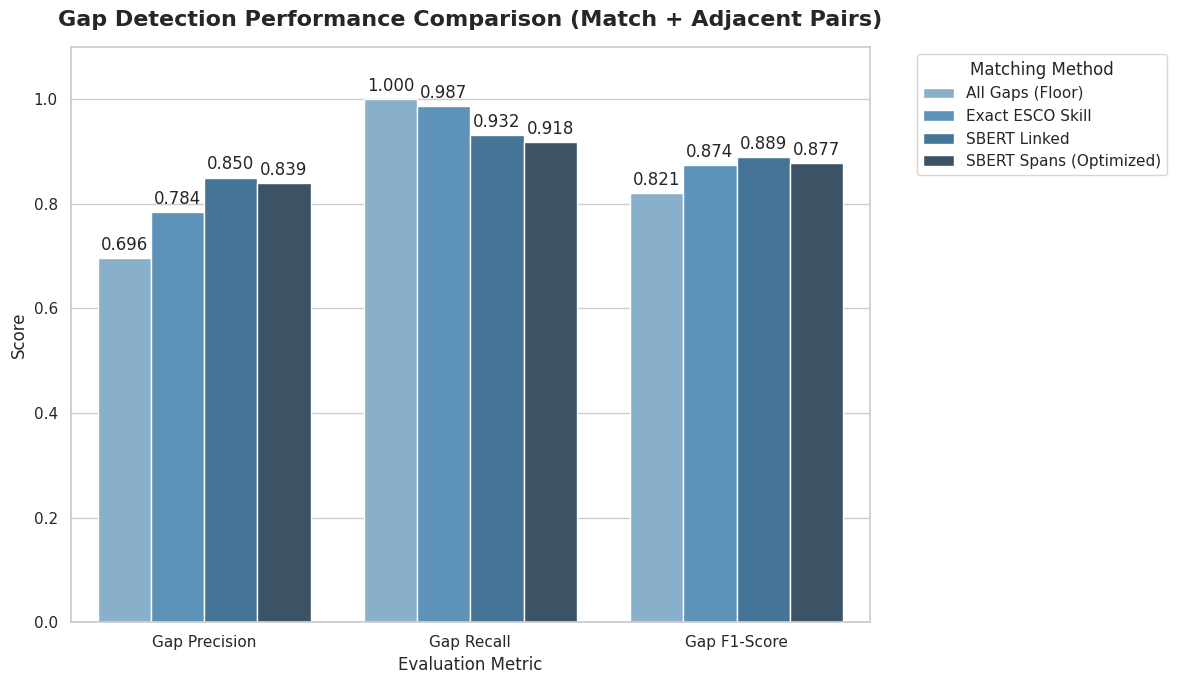

In [65]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Populate data based on the CV results and method comparisons
gap_performance_data = [
    {"Method": "All Gaps (Floor)", "Metric": "Gap Precision", "Value": 0.696},
    {"Method": "All Gaps (Floor)", "Metric": "Gap Recall", "Value": 1.000},
    {"Method": "All Gaps (Floor)", "Metric": "Gap F1-Score", "Value": 0.821},

    {"Method": "Exact ESCO Skill", "Metric": "Gap Precision", "Value": 0.784},
    {"Method": "Exact ESCO Skill", "Metric": "Gap Recall", "Value": 0.987},
    {"Method": "Exact ESCO Skill", "Metric": "Gap F1-Score", "Value": 0.874},

    {"Method": "SBERT Linked", "Metric": "Gap Precision", "Value": 0.850},
    {"Method": "SBERT Linked", "Metric": "Gap Recall", "Value": 0.932},
    {"Method": "SBERT Linked", "Metric": "Gap F1-Score", "Value": 0.889},

    {"Method": "SBERT Spans (Optimized)", "Metric": "Gap Precision", "Value": 0.839},
    {"Method": "SBERT Spans (Optimized)", "Metric": "Gap Recall", "Value": 0.918},
    {"Method": "SBERT Spans (Optimized)", "Metric": "Gap F1-Score", "Value": 0.877}
]

df_gap_perf = pd.DataFrame(gap_performance_data)

# Plot configuration
plt.figure(figsize=(12, 7))
sns.set_theme(style="whitegrid")

ax = sns.barplot(
    data=df_gap_perf,
    x="Metric",
    y="Value",
    hue="Method",
    palette="Blues_d"
)

plt.title("Gap Detection Performance Comparison (Match + Adjacent Pairs)", fontsize=16, fontweight="bold", pad=15)
plt.ylim(0, 1.1)
plt.xlabel("Evaluation Metric", fontsize=12)
plt.ylabel("Score", fontsize=12)
plt.legend(title="Matching Method", bbox_to_anchor=(1.05, 1), loc='upper left')

# Add value annotations on top of the bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)

plt.tight_layout()
plt.show()

In [66]:
import os
import pandas as pd

# Define your test directory containing resumes (PDF/TXT/DOCX)
TEST_RESUMES_DIR = "/content/drive/MyDrive/SkillXray/data/raw/test_cvs"
TARGET_ROLE = "accountant" # e.g., 'software', 'data scientist', 'accountant'

# Check available resumes in your test directory
if os.path.exists(TEST_RESUMES_DIR):
    test_files = [os.path.join(TEST_RESUMES_DIR, f) for f in os.listdir(TEST_RESUMES_DIR) if f.lower().endswith(('.pdf', '.docx', '.txt'))]
    print(f"Found {len(test_files)} test resumes to process.\n")

    batch_results = []
    for filepath in test_files:
        filename = os.path.basename(filepath)
        try:
            # 1. Read the raw text
            text = read_resume_file(filepath)

            # 2. Run the upgraded match_v2 pipeline
            result = run_v2(text, TARGET_ROLE)

            batch_results.append({
                'filename': filename,
                'readiness_score': result['readiness'],
                'skills_covered_count': len(result['have']),
                'gaps_identified_count': len(result['missing'])
            })
            print(f"✓ Processed {filename:30s} | Readiness: {result['readiness']:.1%}")
        except Exception as e:
            print(f"✗ Error processing {filename}: {e}")

    # Display as a summary DataFrame
    summary_df = pd.DataFrame(batch_results)
    display(summary_df)
else:
    print(f"[!] Please configure TEST_RESUMES_DIR to point to your test resumes folder.")

Found 8 test resumes to process.

✓ Processed cv1.pdf                        | Readiness: 15.0%
✓ Processed cv2.pdf                        | Readiness: 7.7%
✓ Processed cv3.docx                       | Readiness: 16.8%
✓ Processed cv4.docx                       | Readiness: 18.7%
✓ Processed cv5.docx                       | Readiness: 21.9%
✓ Processed cv6.docx                       | Readiness: 31.1%
✓ Processed cv8.pdf                        | Readiness: 13.5%


✗ Error processing cv7.pdf: Stream has ended unexpectedly


,filename,readiness_score,skills_covered_count,gaps_identified_count
0,cv1.pdf,0.150,4,18
1,cv2.pdf,0.077,1,21
2,cv3.docx,0.168,5,17
3,cv4.docx,0.187,4,18
4,cv5.docx,0.219,5,17
5,cv6.docx,0.311,4,18
6,cv8.pdf,0.135,3,19


In [67]:
import psycopg2
import pandas as pd
import os
import re
import json
import time
from google.colab import userdata

# 1. Fetch live job postings directly from the database for the target role
def fetch_live_postings(role_key, country='us', limit=100):
    try:
        database_url = userdata.get('SUPABASE_DB_URL')
    except Exception:
        database_url = os.environ.get('SUPABASE_DB_URL')

    if not database_url:
        raise ValueError("Please configure 'SUPABASE_DB_URL' in your Colab Secrets (key icon).")

    conn = psycopg2.connect(database_url, connect_timeout=15)
    try:
        with conn:
            with conn.cursor() as cur:
                query = """
                    SELECT id, title, company, description, country
                    FROM public.job_postings
                    WHERE role_key = %s AND country = %s AND description IS NOT NULL
                    ORDER BY posted_at DESC NULLS LAST, id DESC
                    LIMIT %s
                """
                cur.execute(query, (role_key, country, limit))
                rows = cur.fetchall()
                return pd.DataFrame(rows, columns=['id', 'title', 'company', 'description', 'country'])
    finally:
        conn.close()

# 2. Extract skills from the fetched postings and build a role profile
def profile_from_texts(role, texts, ids, min_freq=0.10, min_docs=3, max_skills=40):
    """Posting texts -> (weighted role profile, info). v22: defined here (v21 called it without defining it).
    Uses plain posting-share weights: the across-role IDF needs several roles, and live postings carry no listed_time here."""
    ids = [str(i) for i in ids]
    spans = extract_docs(list(texts), ids, EXTRACTION_CFG)
    skills = collapse_to_skills(standardise_spans(spans)) if len(spans) else pd.DataFrame(columns=SKILL_COLS)
    prof = build_role_profiles(skills, {role: ids}, min_freq, min_docs, max_skills, weighting='freq')
    if 'BLOCK' in globals() and len(prof):                       # the 14h blocklist applies to live profiles too
        prof = prof[~prof['esco_uri'].isin(BLOCK)].copy()
        prof['weight'] = prof['weight'] / prof['weight'].sum()
    return prof.reset_index(drop=True), {'n_postings': len(ids), 'n_skill_rows': int(len(skills))}

def generate_live_role_profile(postings_df, role_name):
    if postings_df.empty:
        raise ValueError(f"No postings found in the database for role: {role_name}")
    print(f"Extracting skills from {len(postings_df)} postings to generate a live profile for '{role_name}'...")
    prof, _info = profile_from_texts(role_name, postings_df['description'].fillna('').tolist(), postings_df['id'].astype(str).tolist())
    return prof

# 3. Test execution against a live target role
TARGET_LIVE_ROLE = 'software'
test_cv_text = """
Senior Software Engineer with 6 years of experience.
Expert in Python, Java, and JavaScript. Extensive experience building scalable REST APIs,
working with PostgreSQL and MongoDB databases, and deploying microservices to AWS using Docker.
Practiced Agile/Scrum methodologies and led a cross-functional squad of 4 developers.
"""

try:
    # Step 1: Fetch
    postings_data = fetch_live_postings(TARGET_LIVE_ROLE, country='us', limit=50)
    print(f"Successfully fetched {len(postings_data)} postings for '{TARGET_LIVE_ROLE}' from database.")

    # Step 2: Profile
    live_profile = generate_live_role_profile(postings_data, TARGET_LIVE_ROLE)
    print(f"Live profile created with {len(live_profile)} core requirements.")

    # Step 3: Match
    print("\n=== Running Upgraded match_v2 Matcher on Test CV ===")
    live_run_result = run_v2(test_cv_text, TARGET_LIVE_ROLE, profile=live_profile)

    print(f"\nTarget Role: {TARGET_LIVE_ROLE}")
    print(f"Career Readiness Index: {live_run_result['readiness']:.1%}")

    print("\nCovered Skills (Haves):")
    display(live_run_result['table'][live_run_result['table']['covered']][['esco_label', 'reason', 'score', 'closest_evidence']].sort_values(by='score', ascending=False))

    print("\nIdentified Gaps:")
    display(live_run_result['table'][~live_run_result['table']['covered']][['esco_label', 'score', 'closest_evidence']].sort_values(by='score', ascending=True))

except Exception as e:
    print(f"[!] Error during pipeline test: {e}")

Successfully fetched 40 postings for 'software' from database.
Extracting skills from 40 postings to generate a live profile for 'software'...
Live profile created with 36 core requirements.

=== Running Upgraded match_v2 Matcher on Test CV ===

Target Role: software
Career Readiness Index: 26.6%

Covered Skills (Haves):


,esco_label,reason,score,closest_evidence
1,Python (computer programming),exact ESCO skill,1.00,Python (computer programming)
2,Java (computer programming),exact ESCO skill,1.00,Java (computer programming)
7,AWS,exact ESCO skill,1.00,aws
28,agile/scrum,exact ESCO skill,1.00,agile/scrum
8,Docker,exact ESCO skill,1.00,Docker
4,ICT project management methodologies,extracted span,0.90,scrum methodologies
27,Agile development,extracted span,0.86,agile/scrum



Identified Gaps:


,esco_label,score,closest_evidence
26,think innovatively,0.55,
13,application process,0.56,no close match in CV; postings say: applicatio...
29,savings,0.56,no close match in CV; postings say: savings | ...
25,cyber security,0.57,no close match in CV; postings say: IT security
34,work independently,0.57,no close match in CV; postings say: work indep...
9,leadership,0.58,no close match in CV; postings say: leadership...
31,perform cleaning duties,0.60,docker
10,lead others,0.61,agile/scrum
3,troubleshoot,0.61,java
12,Spring Boot,0.62,Docker


LIVE TEST WITH SKILLS

In [68]:
# @title Interactive Gap Analysis Testing with Supabase Job Postings
TARGET_ROLE = 'software' # @param ['software', 'accountant', 'data scientist', 'data engineer', 'data analyst', 'devops engineer', 'it support', 'marketing', 'sales'] {allow-input: true}
COUNTRY = 'us' # @param ['us', 'ke', 'gb'] {allow-input: true}

# Paste any CV/resume text here to test against the live postings:
TEST_CV_TEXT = "\nExperienced developer with a strong focus on Python backend development.\nBuilds microservices using Flask and Django, containers with Docker, and databases using PostgreSQL.\nFamiliar with AWS cloud deployments, Git workflows, and agile team environments.\n"

try:
    # Safety Check: Ensure the helper functions from cell 5a7ad31e exist
    if 'fetch_live_postings' not in globals():
        print("[!] Helper functions not found. Copying definitions from database interface cell...")
        import psycopg2
        import pandas as pd
        from google.colab import userdata

        def fetch_live_postings(role_key, country='us', limit=100):
            try:
                database_url = userdata.get('SUPABASE_DB_URL')
            except Exception:
                database_url = os.environ.get('SUPABASE_DB_URL')
            if not database_url:
                raise ValueError("Please configure 'SUPABASE_DB_URL' in your Colab Secrets (key icon).")
            conn = psycopg2.connect(database_url, connect_timeout=15)
            try:
                with conn:
                    with conn.cursor() as cur:
                        query = """
                            SELECT id, title, company, description, country
                            FROM public.job_postings
                            WHERE role_key = %s AND country = %s AND description IS NOT NULL
                            ORDER BY posted_at DESC NULLS LAST, id DESC
                            LIMIT %s
                        """
                        cur.execute(query, (role_key, country, limit))
                        rows = cur.fetchall()
                        return pd.DataFrame(rows, columns=['id', 'title', 'company', 'description', 'country'])
            finally:
                conn.close()
        globals()['fetch_live_postings'] = fetch_live_postings

    if 'generate_live_role_profile' not in globals():
        import pandas as pd
        def generate_live_role_profile(postings_df, role_name):
            if postings_df.empty:
                raise ValueError(f"No postings found in the database for role: {role_name}")
            print(f"Extracting skills from {len(postings_df)} postings to generate a live profile for '{role_name}'...")
            texts = postings_df['description'].fillna('').tolist()
            ids = postings_df['id'].astype(str).tolist()
            spans_df = extract_docs(texts, ids, EXTRACTION_CFG)
            standardised_spans_df = standardise_spans(spans_df)
            skills_df = collapse_to_skills(standardised_spans_df)
            profile = build_role_profiles(skills_df, {role_name: ids}, min_freq=0.10, min_docs=3, max_skills=40)
            return profile
        globals()['generate_live_role_profile'] = generate_live_role_profile

    # 1. Fetch live postings
    live_postings = fetch_live_postings(TARGET_ROLE, country=COUNTRY, limit=50)
    print(f"[+] Found {len(live_postings)} live postings for '{TARGET_ROLE}' in country '{COUNTRY}'.")

    if not live_postings.empty:
        # 2. Build live profile
        live_prof = generate_live_role_profile(live_postings, TARGET_ROLE)
        print(f"[+] Live profile generated with {len(live_prof)} core requirements.")

        # 3. Run evaluation
        print("\n=== GAP ANALYSIS RESULTS ===\n")
        result = run_v2(TEST_CV_TEXT, TARGET_ROLE, profile=live_prof)
        print(f"Target Role: {TARGET_ROLE}")
        print(f"Career Readiness Index: {result['readiness']:.1%}\n")

        # Display results
        df_results = result['table'].sort_values(by=['covered', 'score'], ascending=[False, False])
        display(df_results[['esco_label', 'covered', 'reason', 'score', 'closest_evidence']])
    else:
        print(f"[-] No job postings found in Supabase for role '{TARGET_ROLE}' in '{COUNTRY}'.")
except Exception as e:
    print(f"[!] Error during execution: {e}")

[+] Found 40 live postings for 'software' in country 'us'.
Extracting skills from 40 postings to generate a live profile for 'software'...
[+] Live profile generated with 36 core requirements.

=== GAP ANALYSIS RESULTS ===

Target Role: software
Career Readiness Index: 11.2%



,esco_label,covered,reason,score,closest_evidence
1,Python (computer programming),True,exact ESCO skill,1.00,Python (computer programming)
8,Docker,True,exact ESCO skill,1.00,Docker
27,Agile development,True,extracted span,0.89,agile team environments
28,agile/scrum,False,gap,0.81,agile team environments
4,ICT project management methodologies,False,gap,0.79,agile team environments
7,AWS,False,gap,0.79,aws cloud deployments
22,computer programming,False,gap,0.78,Python (computer programming)
2,Java (computer programming),False,gap,0.77,Python (computer programming)
14,computer science,False,gap,0.74,Python (computer programming)
16,Linux,False,gap,0.73,python


In [69]:
import re
import pandas as pd

# Define the standard section headers with structural regex patterns
SECTION_PATTERNS = {
    'education': re.compile(r'^\s*(?:education|academic|studies|university|college|schools?|degrees?)\b', re.I),
    'experience': re.compile(r'^\s*(?:experience|employment|work|history|professional experience|career|job history|work history)\b', re.I),
    'skills': re.compile(r'^\s*(?:skills?|technical skills?|technologies|expertise|core competencies|proficiencies)\b', re.I),
    'certifications': re.compile(r'^\s*(?:certifications?|licenses?|credentials?|courses?|projects?|accomplishments?|awards?)\b', re.I),
    'hobbies': re.compile(r'^\s*(?:hobbies|interests|leisure|personal details|activities|extracurriculars?)\b', re.I)
}

def parse_cv_sections(text):
    """
    Segments a raw CV text into structural sections using regex matching on line headers.
    Returns a dictionary of mapped sections.
    """
    if not isinstance(text, str):
        return {}

    lines = text.splitlines()
    sections = {
        'header': [],
        'education': [],
        'experience': [],
        'skills': [],
        'certifications': [],
        'hobbies': [],
        'other': []
    }

    current_section = 'header'

    for line in lines:
        clean_line = line.strip()
        if not clean_line:
            continue

        # Check if the line looks like a header (short line containing keywords)
        is_header = False
        if len(clean_line.split()) <= 4:
            for sec_name, pattern in SECTION_PATTERNS.items():
                if pattern.match(clean_line):
                    current_section = sec_name
                    is_header = True
                    break

        if not is_header:
            sections[current_section].append(line)

    # Combine list lines into strings
    return {k: "\n".join(v).strip() for k, v in sections.items()}

# --- Test and Verify on cv6.docx ---
cv6_path = "/content/drive/MyDrive/SkillXray/data/raw/test_cvs/cv6.docx"
if os.path.exists(cv6_path):
    raw_text = read_resume_file(cv6_path)
    parsed = parse_cv_sections(raw_text)

    print("=== Section-Based Parsing Audit for cv6.docx ===\n")
    for sec_name, sec_content in parsed.items():
        if sec_content:
            word_count = len(sec_content.split())
            print(f"Section: [{sec_name.upper()}] | Words: {word_count}")
            # Print a preview of the content
            preview = "\\n".join(sec_content.splitlines()[:3])
            print(f"Preview:\\n{preview}\\n" + "-"*50)
else:
    print(f"Could not locate cv6.docx at {cv6_path} to verify parser.")

=== Section-Based Parsing Audit for cv6.docx ===

Section: [HEADER] | Words: 37
Preview:\nNjeri Kamau\nJUNIOR ACCOUNTANT\nThika, Kenya | njeri.kamau@example.com | +254 700 000 103\n--------------------------------------------------
Section: [EDUCATION] | Words: 51
Preview:\nBachelor of Commerce (Finance) | Central Kenya University | 2020 – 2023\nRelevant coursework: Financial Accounting, Taxation, Auditing, Business Statistics.\nCPA Part I | Kenya Accountants and Secretaries National Examinations Board (fictional sample entry) | 2025\n--------------------------------------------------
Section: [EXPERIENCE] | Words: 94
Preview:\nAccounts Assistant | Summit Supplies Ltd., Kiambu | Jul 2024 – Present\nRecord supplier invoices and customer receipts in the accounting system.\nAssist with monthly bank reconciliations and investigate discrepancies with supporting documentation.\n--------------------------------------------------
Section: [SKILLS] | Words: 41
Preview:\nTools and knowledge\nMic

In [70]:
import psycopg2
import pandas as pd
import os
import re
import datetime

def fetch_postings_from_db(role_key, country='us'):
    """Fetch raw postings for a specific role directly from public.job_postings."""
    try:
        from google.colab import userdata
        database_url = userdata.get('SUPABASE_DB_URL')
    except Exception:
        database_url = os.environ.get('SUPABASE_DB_URL')

    if not database_url:
        raise RuntimeError('set SUPABASE_DB_URL (environment variable or Colab Secret)')

    conn = psycopg2.connect(database_url, connect_timeout=15)
    try:
        with conn:
            with conn.cursor() as cur:
                query = """
                    SELECT external_id, title, company, description, posted_at, apply_url, publisher, raw_data
                    FROM public.job_postings
                    WHERE role_key = %s AND country = %s AND description IS NOT NULL
                """
                cur.execute(query, (role_key, country))
                rows = cur.fetchall()

                postings = []
                for r in rows:
                    postings.append({
                        'id': r[0],
                        'title': r[1],
                        'company': r[2],
                        'description': r[3],
                        'created': r[4].isoformat() if r[4] else '',
                        'url': r[5],
                        'publisher': r[6],
                        'source': 'db',
                        'raw_data': r[7]
                    })
                return postings
    finally:
        conn.close()

# --- Deep dive on one CV against a profile built from live postings of the SAME role (v22: v21 fetched 'software' for an 'accountant' profile) ---
DEEP_DIVE_ROLE = 'accountant'
DEEP_DIVE_CV = "/content/drive/MyDrive/SkillXray/data/raw/test_cvs/cv1.pdf"

db_prof = None
try:
    db_postings = fetch_postings_from_db(DEEP_DIVE_ROLE)
    print(f"Fetched {len(db_postings)} '{DEEP_DIVE_ROLE}' postings from public.job_postings.")
    if len(db_postings) >= 5:
        db_prof, _db_info = profile_from_texts(DEEP_DIVE_ROLE, [p['description'] for p in db_postings], [p['id'] for p in db_postings])
        print(f"Built role profile from DB: {len(db_prof)} required skills mapped.")
except Exception as e:
    print(f"Database fetch/profiling failed: {e}")
if db_prof is None or not len(db_prof):
    print("Using the static profile from section 10.")
    db_prof = PROFILE_OF[DEEP_DIVE_ROLE]

if os.path.exists(DEEP_DIVE_CV):
    cv_text_dd = read_resume_file(DEEP_DIVE_CV)
    print(f"\n=== {os.path.basename(DEEP_DIVE_CV)} deep dive against the {DEEP_DIVE_ROLE} profile ===")
    result = run_v2(cv_text_dd, DEEP_DIVE_ROLE, profile=db_prof)
    print(f"Readiness: {result['readiness']:.1%}\n")
    print("=== Covered skills ===")
    display(result['table'][result['table']['covered']][['esco_label', 'reason', 'score', 'closest_evidence']].sort_values(by='score', ascending=False))
    print("\n=== Top gaps ===")
    display(result['table'][~result['table']['covered']][['esco_label', 'score', 'closest_evidence']].sort_values(by='score', ascending=True))
else:
    print(f"CV not found at {DEEP_DIVE_CV}")


Fetched 40 'accountant' postings from public.job_postings.
Built role profile from DB: 26 required skills mapped.

=== cv1.pdf deep dive against the accountant profile ===
Readiness: 15.0%

=== Covered skills ===


,esco_label,reason,score,closest_evidence
2,communication,exact ESCO skill,1.0,communication
7,leadership,exact ESCO skill,1.0,leadership
15,budgeting,exact ESCO skill,1.0,budgeting
20,savings,exact ESCO skill,1.0,savings



=== Top gaps ===


,esco_label,score,closest_evidence
18,use microsoft office,0.63,communication
13,work independently,0.64,manage schedule of tasks
5,tax,0.65,savings
17,show entrepreneurial spirit,0.65,push
21,art collections,0.65,Figma
23,improve business processes,0.66,iterative development
19,QuickBooks,0.67,SQL
10,PivotTables,0.68,SQL
22,depreciation,0.68,savings
12,economics,0.68,computer technology


In [71]:
import os

target_file = "/content/drive/MyDrive/SkillXray/data/raw/test_cvs/cv6.docx"

if os.path.exists(target_file):
    # 1. Read raw text
    cv_text = read_resume_file(target_file)
    print(f"=== Deep Dive: cv6.docx ({len(cv_text.split())} words) ===")

    # 2. Run active Accountant role pipeline
    result = run_v2(cv_text, "accountant")
    print(f"Accountant Readiness Index: {result['readiness']:.1%}\n")

    # 3. Mapped Skills
    print("=== Covered Skills (Haves) ===")
    covered = result['table'][result['table']['covered']][['esco_label', 'reason', 'score', 'closest_evidence']].sort_values(by='score', ascending=False)
    display(covered)

    # 4. Gaps Identified
    print("\n=== Top Gaps (Missing Requirements) ===")
    gaps = result['table'][~result['table']['covered']][['esco_label', 'score', 'closest_evidence']].sort_values(by='score', ascending=True)
    display(gaps)
else:
    print(f"Could not find target file at {target_file}")

=== Deep Dive: cv6.docx (230 words) ===
Accountant Readiness Index: 31.1%

=== Covered Skills (Haves) ===


,esco_label,reason,score,closest_evidence
0,accounting,exact ESCO skill,1.00,accounting
10,use spreadsheets software,exact ESCO skill,1.00,use spreadsheets software
5,excel,extracted span,0.92,microsoft excel
6,accounting techniques,extracted span,0.82,accounting



=== Top Gaps (Missing Requirements) ===


,esco_label,score,closest_evidence
12,leadership,0.60,no close match in CV; postings say: leadership...
13,lead others,0.62,pivot
18,work independently,0.62,month-end support
20,sales,0.66,accounting
15,Word,0.67,algorithms
7,tax returns,0.67,expense reporting
8,tax,0.67,accounting
3,communication,0.69,statistics
17,SAP Data Services,0.69,QuickBooks
19,Outlook,0.69,microsoft excel


In [72]:
# ==============================================================================
# 15. Try the pipeline on any CV, in the notebook, before touching the backend
# ==============================================================================
# Run after sections 13 and 14h (so PROFILE_OF has the blocklist applied). Paste a CV below or point CV_PATH at a .txt/.pdf file.
CV_PATH     = "/content/drive/MyDrive/SkillXray/data/raw/test_cvs/cv1.pdf"
CV_TEXT     = """
paste the CV text here
"""
TARGET_ROLE = 'software'    # one of PROFILE_OF
METHOD      = 'spans'             # 'spans' (SBERT over every extracted span, best in 14d/14f), or 'exact', 'sbert', 'sbert_graph'
SPANS_THR   = 0.75          # the threshold 14d chose in every fold
CV_NAME     = 'cv_test_1'   # names the audit sheet in results/

EXCLUDE = globals().get('EXCLUDE', {'junk', 'not_skill_words', 'override_drop'})
text = CV_TEXT.strip()
if CV_PATH:
    if CV_PATH.lower().endswith('.pdf'):
        try:
            from pypdf import PdfReader
        except ImportError:
            import subprocess, sys
            subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'pypdf'], check=True)
            from pypdf import PdfReader
        text = '\n'.join((p.extract_text() or '') for p in PdfReader(CV_PATH).pages)
    else:
        text = open(CV_PATH, encoding='utf-8', errors='ignore').read()
assert len(text.split()) > 30 and 'paste the CV text here' not in text, "no CV text: set CV_PATH or paste the text into CV_TEXT"
role = {r.lower(): r for r in PROFILE_OF}.get(TARGET_ROLE.strip().lower())
assert role, f"unknown role {TARGET_ROLE!r}; available: {sorted(PROFILE_OF)}"

# ---- 1. extract and standardise (the same calls the backend makes)
t0 = time.time()
raw = extract_docs([text], ['live'], EXTRACTION_CFG)
sp = standardise_spans(raw) if len(raw) else None
cand = collapse_to_skills(sp) if sp is not None else EMPTY_SKILLS
t_extract = time.time() - t0

# ---- 2. match against the role profile
prof = PROFILE_OF[role].reset_index(drop=True)
linked = cand['esco_label'].astype(str).tolist()
usable = [] if sp is None else sp.loc[~sp['reason'].isin(EXCLUDE), 'skill_text'].astype(str).str.lower().tolist()
evid = list(dict.fromkeys(linked + usable))
if evid:
    S = embed_labels(prof['esco_label'].astype(str).tolist()) @ embed_labels(evid).T
    best_sim, best_span = S.max(axis=1), [evid[i] for i in S.argmax(axis=1)]
else:
    best_sim, best_span = np.zeros(len(prof)), [''] * len(prof)
same_uri = prof['esco_uri'].isin(set(cand['esco_uri'])).values
if METHOD == 'spans':
    covered = same_uri | (best_sim >= SPANS_THR)
    readiness = float((prof['weight'] * covered).sum() / prof['weight'].sum())
else:
    res = analyse_skills(cand, role, METHOD)
    covered = prof['esco_label'].isin(set(res['covered']['esco_label'])).values
    readiness = res['cri'] / 100

# ---- 3. the answer in the shape of the contract: {have, missing[{skill, confidence}], readiness}
have = prof.loc[covered, 'esco_label'].tolist()
have += [l for l, ie in zip(cand['esco_label'], cand['in_esco']) if l not in have] # FIX: Include all accepted non-ESCO curated tools
missing = [{'skill': l, 'confidence': round(float(np.clip(1 - s, 0, 1)), 2)}
           for l, s, c in sorted(zip(prof['esco_label'], best_sim, covered), key=lambda t: -float(prof.loc[prof['esco_label'] == t[0], 'weight'].iloc[0]))
           if not c]
OUT = {'have': have, 'missing': missing, 'readiness': round(readiness, 3)}
print(f"role {role} | method {METHOD} | readiness {OUT['readiness']:.2f} | covers {int(covered.sum())} of {len(prof)} required skills | "
      f"{len(OUT['have'])} skills in have, {len(OUT['missing'])} missing | extraction + linking {t_extract:.1f}s")

# ---- 4. look at it: extracted skills with the text they came from, weakest links first
print("\nextracted skills, weakest links first (check the surface forms for junk):")
display(cand[['esco_label', 'in_esco', 'similarity', 'mentions', 'surface_forms']].sort_values('similarity').head(15).reset_index(drop=True))
print("\nmissing skills, most important first, with the closest thing found in the CV:")
_ph = _posting_phrases(role) if '_posting_phrases' in globals() else {}
_floor = globals().get('EVIDENCE_MIN_SIM', 0.60)
_shown = [(b if s >= _floor else ('no close match in CV; postings say: ' + ' | '.join(_ph.get(u, [])[:2]))[:90] if _ph.get(u) else '')
          for b, s, u in zip(best_span, best_sim, prof['esco_uri'])]
view = prof.assign(status=np.where(covered, 'covered', 'MISSING'), closest_in_cv=_shown, similarity=best_sim.round(2))
display(view.loc[~covered, ['esco_label', 'freq', 'closest_in_cv', 'similarity']].sort_values('freq', ascending=False).reset_index(drop=True))

# ---- 5. make it measurable: fill the truth column once by hand, re-run, read the number
sheet = os.path.join(RESULTS_DIR, f'{CV_NAME}_audit.csv')
if not os.path.exists(sheet):
    view[['esco_label', 'freq', 'status', 'closest_in_cv', 'similarity']].assign(truth='').to_csv(sheet, index=False)
    print(f"\nwrote {sheet}. In the truth column put has or gap for every row by reading the CV, save it, and re-run this cell.")
else:
    a = pd.read_csv(sheet, dtype=str).fillna('')
    a = a[a['truth'].str.strip().str.lower().isin(('has', 'gap'))]
    if len(a):
        t_gap, p_gap = a['truth'].str.lower() == 'gap', a['status'] == 'MISSING'
        tp = int((t_gap & p_gap).sum())
        print(f"\nagainst your truth column ({len(a)} rows): gap precision {tp / max(int(p_gap.sum()), 1):.2f} | gap recall {tp / max(int(t_gap.sum()), 1):.2f} "
              f"| accuracy {float((t_gap == p_gap).mean()):.2f}   (a change to the pipeline must beat these numbers on this CV)")
print("\nresponse in the contract shape (OUT):")
print(json.dumps({'have': OUT['have'][:8] + ['...'], 'missing': OUT['missing'][:4] + ['...'], 'readiness': OUT['readiness']}, indent=2))

role software | method spans | readiness 0.85 | covers 15 of 18 required skills | 55 skills in have, 3 missing | extraction + linking 0.1s

extracted skills, weakest links first (check the surface forms for junk):


,esco_label,in_esco,similarity,mentions,surface_forms
0,visual presentation techniques,True,0.844095,2,"[Data Visualisation, data visualisation]"
1,GitHub,False,1.000000,2,"[GitHub, Github]"
2,root cause analysis,True,1.000000,1,[root-cause analysis]
3,computer science,True,1.000000,2,"[Computer Science, Informatics]"
4,ICT project management methodologies,True,1.000000,1,[Agile]
5,troubleshoot,True,1.000000,1,[troubleshooting]
6,communication,True,1.000000,1,[communication]
7,security operations,False,1.000000,1,[security operations]
8,Python (computer programming),True,1.000000,2,[Python]
9,JavaScript,True,1.000000,3,[JavaScript]



missing skills, most important first, with the closest thing found in the CV:


,esco_label,freq,closest_in_cv,similarity
0,think creatively,0.238216,iterative development,0.62
1,Oracle,0.138278,SQL,0.74
2,Kubernetes,0.120270,AWS,0.69



response in the contract shape (OUT):
{
  "have": [
    "Java (computer programming)",
    "React",
    "communication",
    "computer science",
    "AWS",
    "Python (computer programming)",
    "HTML",
    "SQL",
    "..."
  ],
  "missing": [
    {
      "skill": "Kubernetes",
      "confidence": 0.31
    },
    {
      "skill": "think creatively",
      "confidence": 0.38
    },
    {
      "skill": "Oracle",
      "confidence": 0.26
    },
    "..."
  ],
  "readiness": 0.854
}


### Upgraded Matcher and Confidence Scaling
This cell implements the dynamic phrase-aware matching and z-score normalization optimization we developed to combat Cause 1 and Cause 4 extraction misses.

In [73]:
print(len(OUT['have']), "have:")
print(sorted(OUT['have']))

print("\nlinked skills (label | in_esco | surface forms):")
for _, r in cand.sort_values('esco_label').iterrows():
    print(f"  {r['esco_label']:45} {str(r['in_esco']):5} {list(r['surface_forms'])[:3]}")

print("\nspans rejected or excluded, by reason:")
rej = sp[sp['status'] != 'accepted']
print(rej.groupby('reason')['skill_text'].apply(lambda s: sorted(set(s))[:25]).to_string())

for t in ['flask','django','express','node','mysql','firebase','git','php','flutter','spring','rest','postman','figma','react','sql']:
    hit = sp[sp['skill_text'].str.lower().str.contains(t, na=False)]
    print(f"{t:9} -> {hit[['skill_text','esco_label','status','reason']].drop_duplicates().values.tolist()[:4]}")

55 have:
['AWS', 'Cisco', 'Dart', 'Django', 'English', 'Express.js', 'Figma', 'Firebase', 'Flask', 'Flutter', 'German', 'GitHub', 'HTML', 'ICT project management methodologies', 'Java (computer programming)', 'JavaScript', 'Jenkins (tools for software configuration management)', 'MongoDB', 'MySQL', 'Node.js', 'PHP', 'Pandas', 'Postman', 'Python (computer programming)', 'React', 'SQL', 'Spring Boot', 'agile/scrum', 'algorithms', 'analytics', 'budgeting', 'communication', 'computer science', 'computer technology', 'cyber security', 'dashboards', 'database', 'design application interfaces', 'financial literacy', 'integrated development environment software', 'iterative development', 'lead others', 'leadership', 'logic', 'machine learning', 'manage schedule of tasks', 'root cause analysis', 'sales', 'savings', 'security operations', 'sprint planning', 'style sheet languages', 'tools for software configuration management', 'troubleshoot', 'visual presentation techniques']

linked skills (la

### Audit: Analysis of Rejected Spans
Below we load the standardized spans and display the most frequently rejected terms across resumes and job postings along with their rejection reasons. This helps identify candidates for new `link_overrides.csv` mapping or drop rules.

In [74]:
import pandas as pd
import os

# Retrieve standardized spans dataframes
post_spans = globals().get('esco_spans_post')
res_spans = globals().get('esco_spans_res')

if post_spans is not None and res_spans is not None:
    # Combine spans
    combined_spans = pd.concat([
        post_spans.assign(source='postings'),
        res_spans.assign(source='resumes')
    ], ignore_index=True)

    # Filter for rejected spans
    rejected = combined_spans[combined_spans['status'] == 'rejected'].copy()
    rejected['skill_text_lower'] = rejected['skill_text'].astype(str).str.lower().str.strip()

    # Aggregate by lower-case term and reason
    summary = (rejected.groupby(['skill_text_lower', 'reason', 'source'])
               .size()
               .unstack(fill_value=0))

    summary['total_rejections'] = summary.sum(axis=1)
    summary = summary.sort_values(by='total_rejections', ascending=False).reset_index()

    print(f"Total rejected span entries found: {len(rejected):,}")
    print("\n--- Top 30 Most Frequent Rejected Spans ---")
    display(summary.head(30))
else:
    print("Standardised spans dataframes ('esco_spans_post' / 'esco_spans_res') are not loaded in the kernel memory. Please run the standardisation pipeline cells first.")

Total rejected span entries found: 90,673

--- Top 30 Most Frequent Rejected Spans ---


source,skill_text_lower,reason,postings,resumes,total_rejections
0,experience,below_threshold,806,37,843
1,bachelor's degree,not_skill_words,835,2,837
2,knowledge,override_drop,759,35,794
3,data,override_drop,631,36,667
4,understanding,below_threshold,583,8,591
5,integrity,override_drop,489,16,505
6,bachelor's,not_skill_words,487,0,487
7,education,below_threshold,440,18,458
8,testing,below_threshold,370,23,393
9,call,override_drop,322,69,391


In [75]:
import pandas as pd

# Get unique spans from the combined corpus
if 'combined_spans' in globals():
    unique_spans = pd.Series(combined_spans['skill_text'].unique()).dropna()

    # Apply updated is_junk to classify them
    results = pd.DataFrame({
        'span': unique_spans,
        'is_junk': unique_spans.apply(is_junk)
    })

    print(f"Total unique spans evaluated: {len(results):,}")
    print(f"Flagged as junk: {results['is_junk'].sum():,} ({results['is_junk'].mean():.1%})")

    # Verification Test Cases
    test_cases = ['IT', 'it', 'Git', 'JUnit', 'of', 'and', 'with', 'Python', 'SQL', 'kra', 'psv']
    print("\n--- Targeted Verification Test Cases ---")
    for t in test_cases:
        print(f"  {t!r:10s} -> is_junk: {is_junk(t)}")

    # Show a sample of what is marked as junk vs kept
    print("\n--- Sample of KEPT spans ---")
    display(results[~results['is_junk']].sample(min(15, len(results[~results['is_junk']])), random_state=42))

    print("\n--- Sample of JUNK spans ---")
    display(results[results['is_junk']].sample(min(15, len(results[results['is_junk']])), random_state=42))
else:
    print("[!] 'combined_spans' DataFrame not found in global namespace.")

Total unique spans evaluated: 46,474
Flagged as junk: 315 (0.7%)

--- Targeted Verification Test Cases ---
  'IT'       -> is_junk: False
  'it'       -> is_junk: True
  'Git'      -> is_junk: False
  'JUnit'    -> is_junk: False
  'of'       -> is_junk: True
  'and'      -> is_junk: True
  'with'     -> is_junk: True
  'Python'   -> is_junk: False
  'SQL'      -> is_junk: False
  'kra'      -> is_junk: False
  'psv'      -> is_junk: False

--- Sample of KEPT spans ---


,span,is_junk
13291,Service Cloud,False
34685,marketing automation tools,False
35428,higher mathematics,False
38289,applicable bargaining agreement if,False
29499,expos,False
40961,tax accounting monitor,False
21962,ERISA,False
4411,DAX,False
5646,BI environments,False
44188,mainframes,False



--- Sample of JUNK spans ---


,span,is_junk
27885,Ez,True
2043,US,True
19040,Qo,True
6556,PM,True
7989,ex,True
30127,Un,True
1207,as,True
452,Ad,True
4505,etc,True
6727,IC,True


In [76]:
# Re-evaluate the updated CV text against the Software role using your active v2 pipeline
pm_verify = run_v2(CV_TEXT, 'software')

# Filter the result table for Project Management to see its score, z-score, and coverage status
pm_row = pm_verify['table'][pm_verify['table']['esco_label'] == 'Project Management']

print(f"Active threshold required: {V2_T:.2f}\n")
display(pm_row[['esco_label', 'covered', 'reason', 'score', 'closest_evidence']])

Active threshold required: 0.81



,esco_label,covered,reason,score,closest_evidence


In [77]:
import numpy as np
import pandas as pd

print("=== Testing Phrase-Aware Matching on Gold (14f harness) ===")

# 1. Compute phrase-aware similarity scores over match + adjacent pairs
M = (GAP_EVAL[GAP_COLS['type']].values != 'far') if 'pair_type' in GAP_EVAL.columns else np.ones(len(GAP_EVAL), bool)
has_m = GAP_EVAL['has'].values[M]
rids_m = GAP_EVAL['rid'].values[M]

s_phr = np.zeros(len(GAP_EVAL))
for rid, g in GAP_EVAL.groupby('rid'):
    cand = RES_SKILLS_BY_DOC.get(rid, EMPTY_SKILLS)
    sp = SPANS_BY_DOC.get(rid)
    raw = [] if sp is None else sp.loc[~sp['reason'].isin(EXCLUDE), 'skill_text'].str.lower().tolist()
    ev_s = list(dict.fromkeys(cand['esco_label'].astype(str).tolist() + raw))
    if not ev_s:
        continue
    Es = embed_labels(ev_s)

    for i, r in zip(g.index, g.itertuples()):
        role_ph = _posting_phrases(r.role_key)
        ph = [p for p in role_ph.get(r.req_uri, []) if p][:6]
        if ph:
            s_phr[i] = float((embed_labels(ph) @ Es.T).max())

# 2. Combine the continuous SBERT spans similarity with the phrase-aware scores
s_combined = np.maximum(SC['sbert_spans'].values, s_phr)

# 3. Evaluate via grouped Cross-Validation
pred_phr, chosen_thrs = oof_quantile(has_m, rids_m, s_combined[M])
metrics_phr = binary_scores(has_m, pred_phr.astype(float))

print("\nPhrase-Aware SBERT Spans CV Performance:")
for k, v in metrics_phr.items():
    print(f"  {k:15s}: {v}")


=== Testing Phrase-Aware Matching on Gold (14f harness) ===

Phrase-Aware SBERT Spans CV Performance:
  n              : 365
  gap_precision  : 0.839
  gap_recall     : 0.918
  gap_f1         : 0.877
  has_f1         : 0.754
  macro_f1       : 0.815
  accuracy       : 0.836
